In [1]:
!which python
!python --version
!which pip
!pip --version

/bin/bash: line 1: python: command not found
/usr/bin/pip
pip 24.0 from /usr/lib/python3/dist-packages/pip (python 3.12)


In [2]:
!which python3
!python3 --version

/usr/bin/python3
Python 3.12.3


In [3]:
print("hi")

hi


In [3]:
!python3 -m pip install torch torchvision torchaudio

In [4]:
import sys
print(sys.executable)

/venv/main/bin/python


In [5]:
!python3 -m pip show torch

Name: torch
Version: 2.13.0
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: 
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: 
Location: /usr/local/lib/python3.12/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: torchvision


In [6]:
import sys
print(sys.executable)
print(sys.version)

/venv/main/bin/python
3.12.13 | packaged by conda-forge | (main, Mar  5 2026, 16:50:00) [GCC 14.3.0]


In [7]:
!python3 -m pip show torch

Name: torch
Version: 2.13.0
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: 
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: 
Location: /usr/local/lib/python3.12/dist-packages
Requires: cuda-bindings, cuda-toolkit, filelock, fsspec, jinja2, networkx, nvidia-cudnn-cu13, nvidia-cusparselt-cu13, nvidia-nccl-cu13, nvidia-nvshmem-cu13, setuptools, sympy, triton, typing-extensions
Required-by: torchvision


In [8]:
!python3 -m pip install torch torchvision torchaudio

In [9]:
import sys
!{sys.executable} -m pip install torch torchvision torchaudio

In [10]:
import sys
print(sys.executable)

import torch
print(torch.__version__)
print(torch.cuda.is_available())

/venv/main/bin/python
2.13.0+cu130
True


In [11]:
# %% ===================== ENVIRONMENT SETUP =====================
# Most vast.ai template images (e.g. the official PyTorch ones) already ship a working
# torch+CUDA build -- that's normally the fastest/least error-prone option, which is why this
# cell does NOT force a torch reinstall (your original notebook lost a lot of time to that
# uninstall/reinstall loop). It only installs the extra python packages this pipeline needs, and
# then just reports whether CUDA is visible so you can act on it if not.
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
                'pandas', 'numpy', 'scipy', 'scikit-learn', 'matplotlib', 'tqdm', 'openpyxl',
                'pyarrow', 'icd-mappings', 'importlib_resources'], check=True)

import torch
print('torch       :', torch.__version__, flush=True)
print('torch.cuda  :', torch.version.cuda, flush=True)
print('cuda avail  :', torch.cuda.is_available(), flush=True)
if not torch.cuda.is_available():
    print('\n!! No GPU visible to torch. On vast.ai this almost always means either (a) you picked '
          'a CPU-only instance/image, or (b) the torch build here doesn\'t match the instance\'s '
          'CUDA driver. Check `nvidia-smi` first -- if that shows a GPU, only then consider '
          'reinstalling torch for the matching CUDA version, e.g.:\n'
          '  pip install torch --index-url https://download.pytorch.org/whl/cu121\n', flush=True)


torch       : 2.13.0+cu130
torch.cuda  : 13.0
cuda avail  : True


In [12]:
# %% ===================== IMPORTS & DEVICE =====================
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'torchcde', 'torchdiffeq'], check=True)

import math, os, json, pickle, random, gc, glob, re, time
import numpy as np
import pandas as pd

# Reduces CUDA memory fragmentation -- must be set before torch is imported.
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
import torchvision
from torchvision import transforms
from PIL import Image

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'[{time.strftime("%H:%M:%S")}] device = {DEVICE}', flush=True)
if DEVICE.type == 'cuda':
    print(f'  GPU: {torch.cuda.get_device_name(0)}', flush=True)
    print(f'  CUDA: {torch.version.cuda}  torch: {torch.__version__}', flush=True)
else:
    print('  WARNING: no GPU visible. On vast.ai, double check your instance actually has a GPU '
          'attached and that you selected a CUDA-enabled image.', flush=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


[01:13:35] device = cuda
  GPU: NVIDIA A100 80GB PCIe
  CUDA: 13.0  torch: 2.13.0+cu130


In [13]:
import torch

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Torch version: 2.13.0+cu130
CUDA available: True
GPU: NVIDIA A100 80GB PCIe


In [14]:
!pip install kaggle

In [14]:
!mkdir -p /workspace/datasets

# CXR metadata
!kaggle datasets download -d fahmidasultananaznin/cxr-metadata -p /workspace/datasets
!unzip -o /workspace/datasets/cxr-metadata.zip -d /workspace/datasets/cxr-metadata

# Item map
!kaggle datasets download -d fahmidasultananaznin/item-to-variablr-map -p /workspace/datasets
!unzip -o /workspace/datasets/item-to-variablr-map.zip -d /workspace/datasets/item-to-variablr-map


Dataset URL: https://www.kaggle.com/datasets/fahmidasultananaznin/cxr-metadata
License(s): unknown
cxr-metadata.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  /workspace/datasets/cxr-metadata.zip
  inflating: /workspace/datasets/cxr-metadata/mimic-cxr-2.0.0-metadata.csv  
Dataset URL: https://www.kaggle.com/datasets/fahmidasultananaznin/item-to-variablr-map
License(s): unknown
item-to-variablr-map.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  /workspace/datasets/item-to-variablr-map.zip
  inflating: /workspace/datasets/item-to-variablr-map/itemid_to_variable_map.csv  


In [ ]:
# MIMIC-CXR
!kaggle datasets download -d fahmidasultananaznin/mimic-cxr -p /workspace/datasets
!unzip -o /workspace/datasets/mimic-cxr.zip -d /workspace/datasets/mimic-cxr

# MIMIC-IV
!kaggle datasets download -d fahmidasultananaznin/mimic-iv -p /workspace/datasets
!unzip -o /workspace/datasets/mimic-iv.zip -d /workspace/datasets/mimic-iv

In [14]:
import os
import numpy as np
import pandas as pd

In [15]:
# %% ===================== CONFIG =====================
# Every knob that differs from your original notebook has a comment explaining why.
SEED = 42

# ---- cohort ----
TRAIN_WINDOW   = 36.0
HORIZONS       = [6, 12, 18, 24]
DISEASE_FILTER = True                # << REQUIRED by your supervisor -- the analysis/fine-tuning
                                     #    cohort stays restricted to TARGET_DISEASE. What changed
                                     #    instead: the EHR self-supervised PRETRAINING pool below
                                     #    is decoupled from this filter, so the encoder still gets
                                     #    to see a much larger population before it ever touches a
                                     #    disease-cohort label. See the pretraining markdown cell.
TARGET_DISEASE = "Cardiac dysrhythmias"
MAX_IMAGES     = 8

# ---- sequence / model ----
MAX_EVENTS       = 200
IMG_SIZE         = 224
D_MODEL          = 32
DROPOUT          = 0.15             # << was 0.10 -- small bump, fighting overfitting on tiny data
MODALITY_DROPOUT = 0.15             # << new: chance of hiding one modality per sample while training

# ---- cross-validation ----
TEST_FRAC = 0.15
N_FOLDS   = 5                       # << was 3. With the cohort size now fixed by the disease
                                     #    filter, squeezing the estimate as tight as possible
                                     #    matters more than saving compute -- 5 folds instead of 3.
REPEATS   = 1                       # << new: repeat the whole K-fold procedure with a different
                                     #    fold assignment each time and ensemble across ALL
                                     #    repeat x fold models. Total models per horizon/mode =
                                     #    N_FOLDS * REPEATS. Raise to 2-3 if you have the GPU
                                     #    hours -- this is the single easiest remaining dial for
                                     #    tightening/improving the reported number once everything
                                     #    below is in place.

# ---- training ----
BATCH_SIZE   = 8                    # << was 4 -- freezing most of the CNN (below) frees up enough
                                     #    memory to afford a bigger batch, which also stabilizes
                                     #    gradients on this small a dataset.
MAX_EPOCHS        = 150
PATIENCE          = 15
MIN_EPOCHS        = 15
LR                = 1e-4
WEIGHT_DECAY      = 1e-3
WARMUP_HEAD_EPOCHS = 5               # << new: first this many epochs train ONLY the fusion head
                                     #    (EHR encoder + CNN fully frozen) -- "linear-probe-then-
                                     #    fine-tune" (Kumar et al. 2022). Stops a randomly-init
                                     #    head from sending destabilizing gradients through your
                                     #    two pretrained encoders on epoch 1. Set to 0 to disable.

# ---- imbalance ----
IMBALANCE = 'focal'
FOCAL_ALPHA, FOCAL_GAMMA = 0.75, 2.0

# ---- EHR self-supervised pretraining (the core idea borrowed from STraTS) ----
EHR_PRETRAIN       = True
PRETRAIN_EPOCHS    = 40
PRETRAIN_LR        = 1e-3
FORECAST_HORIZON_H = 2.0            # predict the next 2h of vitals -- same horizon STraTS uses

# ---- CNN regularization ----
FREEZE_CNN_BACKBONE = True          # << new: freeze all of densenet121 except its last dense block

# ---- checkpointing / resume / logging ----
CKPT_ROOT = "/workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2"
RESUME    = True                    # set False once to force a from-scratch run, then back to True
HEARTBEAT_EVERY_BATCHES = 10
HEARTBEAT_EVERY_SECONDS = 60

os.makedirs(CKPT_ROOT, exist_ok=True)
#set_seed(SEED)
print('CKPT_ROOT:', CKPT_ROOT, flush=True)
print('NOTE: this directory lives on the vast.ai instance\'s local disk, which is destroyed if '
      'you destroy/rent-out the instance (it does survive a simple stop/restart of the SAME '
      'instance). If you want your checkpoints to survive the instance being torn down, mount a '
      'vast.ai network volume here, or periodically rsync/rclone CKPT_ROOT somewhere else.', flush=True)


CKPT_ROOT: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2
NOTE: this directory lives on the vast.ai instance's local disk, which is destroyed if you destroy/rent-out the instance (it does survive a simple stop/restart of the SAME instance). If you want your checkpoints to survive the instance being torn down, mount a vast.ai network volume here, or periodically rsync/rclone CKPT_ROOT somewhere else.


In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

### ContiFormer core (inlined from PhysioPro — MIT License, unchanged from your notebook)

`AttrDict`, `EncoderLayer`, `MultiHeadAttention`, `PositionwiseFeedForward`,
`ScaledDotProductAttention`, and their ODE/interpolation dependencies (`ODELinear`, `InterpLinear`,
`TimeVariableODE`, `build_fc_odefunc`), copied verbatim from your working notebook. Nothing here
was touched — the only ContiFormer-side change is the pooling step in `ContiFormerEncoder` further
down, which wraps this core rather than modifying it.


In [17]:
# ===================== ContiFormer core (inlined from Microsoft's PhysioPro, no git/pip install needed) =====================
# Source: microsoft/PhysioPro -- physiopro/network/contiformer.py, physiopro/module/{linear,ode,interpolate}.py
# Copied in directly (MIT License) so this notebook has zero dependency on cloning the repo.
from inspect import signature
import torchcde
from torchdiffeq import odeint_adjoint as odeint

class AttrDict(dict):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.__dict__ = self

# ---- ODE building blocks (physiopro/module/ode.py) ----
class ConcatLinear_v2(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self._layer = nn.Linear(dim_in, dim_out)
        self._hyper_bias = nn.Linear(1, dim_out, bias=False)
        self._hyper_bias.weight.data.fill_(0.0)
    def forward(self, t, x):
        return self._layer(x) + self._hyper_bias(t.view(-1, 1))

class ConcatLinearNorm(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self._layer = nn.Linear(dim_in, dim_out)
        self._hyper_bias = nn.Linear(1, dim_out, bias=False)
        self._hyper_bias.weight.data.fill_(0.0)
        self.norm = nn.LayerNorm(dim_out, eps=1e-6)
    def forward(self, t, x):
        return self.norm(self._layer(x) + self._hyper_bias(t.view(-1, 1)))

class ConcatSquashLinear(nn.Module):
    def __init__(self, dim_in, dim_out):
        super().__init__()
        self._layer = nn.Linear(dim_in, dim_out)
        self._hyper_bias = nn.Linear(1, dim_out, bias=False)
        self._hyper_gate = nn.Linear(1, dim_out)
    def forward(self, t, x):
        return self._layer(x) * torch.sigmoid(self._hyper_gate(t.view(-1, 1))) \
               + self._hyper_bias(t.view(-1, 1))

class DiffEqWrapper(nn.Module):
    def __init__(self, module):
        super().__init__()
        self.module = module
    def forward(self, t, y):
        if len(signature(self.module.forward).parameters) == 1:
            return self.module(y)
        if len(signature(self.module.forward).parameters) == 2:
            return self.module(t, y)
        raise ValueError("Differential equation needs to either take (t, y) or (y,) as input.")
    def __repr__(self):
        return self.module.__repr__()

def diffeq_wrapper(layer):
    return DiffEqWrapper(layer)

class SequentialDiffEq(nn.Module):
    """A container for a sequential chain of layers. Supports both regular and diffeq layers."""
    def __init__(self, *layers):
        super().__init__()
        self.layers = nn.ModuleList([diffeq_wrapper(layer) for layer in layers])
    def forward(self, t, x):
        for layer in self.layers:
            x = layer(t, x)
        return x

class TimeDependentSwish(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
        self.beta = nn.Sequential(
            nn.Linear(1, min(64, dim * 4)), nn.Softplus(),
            nn.Linear(min(64, dim * 4), dim), nn.Softplus(),
        )
    def forward(self, t, x):
        beta = self.beta(t.reshape(-1, 1))
        return x * torch.sigmoid_(x * beta)

class WrapRegularization(torch.autograd.Function):
    @staticmethod
    def forward(ctx, reg, *x):
        ctx.save_for_backward(reg)
        return x
    @staticmethod
    def backward(ctx, *grad_x):
        reg, = ctx.saved_variables
        return (torch.ones_like(reg), *grad_x)

class TimeVariableODE(nn.Module):
    start_time = -1.0
    end_time = 1.0
    def __init__(self, func, atol=1e-6, rtol=1e-6, method="dopri5", energy_regularization=0.01,
                 regularize=False, ortho=False):
        super().__init__()
        self.func = func
        self.atol = atol; self.rtol = rtol; self.method = method
        self.energy_regularization = energy_regularization
        self.regularize = regularize; self.ortho = ortho
        self.nfe = 0
        self.gauss_legendre = {
            1: torch.tensor([-1, 0, 1]),
            2: torch.tensor([-1, -0.57735, 0.57735, 1]),
            3: torch.tensor([-1, -0.77459, 0, 0.77459, 1]),
            4: torch.tensor([-1, -0.86113, -0.33998, 0.33998, 0.86113, 1]),
            5: torch.tensor([-1, -0.90618, -0.53846, 0, 0.53846, 0.90618, 1]),
        }
    def integrate(self, t0, t1, x0, nlinspace=1, method=None, gauss=False, save=None, atol=None):
        if save is not None:
            save_timestamp = save
        elif gauss:
            save_timestamp = self.gauss_legendre[nlinspace].to(t0)
        else:
            save_timestamp = torch.linspace(self.start_time, self.end_time, nlinspace + 1).to(t0)
        method = method or self.method
        atol = atol or self.atol
        solution = odeint(
            self, (t0, t1, torch.zeros(1).to(x0[0]), x0), save_timestamp,
            rtol=self.rtol, atol=self.atol, method=method, options={"step_size": atol},
        )
        _, _, energy, xs = solution
        if gauss:
            xs = xs[1:-1, ...]
        if self.regularize:
            reg = energy * self.energy_regularization
            return WrapRegularization.apply(reg, xs)[0]
        return xs
    def forward(self, s, state):
        """Solves the same dynamics but uses a dummy variable that always integrates [0, 1]."""
        self.nfe += 1
        t0, t1, _, x = state
        ratio = (t1 - t0) / (self.end_time - self.start_time)
        t = (s - self.start_time) * ratio + t0
        with torch.enable_grad():
            dx = self.func(t, x)
            if self.ortho:
                dx = dx - (dx * x).sum(dim=-1, keepdim=True) / (x * x).sum(dim=-1, keepdim=True) * x
            dx = dx * ratio.reshape(-1, *([1] * (dx.ndim - 1)))
            d_energy = torch.sum(dx * dx) / x.numel()
        if not self.training:
            dx = dx.detach()
        return tuple([torch.zeros_like(t0), torch.zeros_like(t1), d_energy, dx])
    def extra_repr(self):
        return f"method={self.method}, atol={self.atol}, rtol={self.rtol}, energy={self.energy_regularization}"

ACTFNS = {
    "softplus": (lambda dim: nn.Softplus()),
    "tanh": (lambda dim: nn.Tanh()),
    "swish": TimeDependentSwish,
    "relu": (lambda dim: nn.ReLU()),
    "leakyrelu": (lambda dim: nn.LeakyReLU()),
    "sigmoid": (lambda dim: nn.Sigmoid()),
}
LAYERTYPES = {
    "concatsquash": ConcatSquashLinear,
    "concat": ConcatLinear_v2,
    "concatlinear": ConcatLinear_v2,
    "concatnorm": ConcatLinearNorm,
}

def build_fc_odefunc(dim=2, hidden_dims=[64, 64, 64], out_dim=None, nonzero_dim=None, actfn="softplus",
                      layer_type="concat", zero_init=True, actfirst=False):
    assert layer_type in LAYERTYPES, f"layer_type must be one of {LAYERTYPES.keys()} but was given {layer_type}"
    layer_fn = LAYERTYPES[layer_type]
    if layer_type == "concatlinear":
        hidden_dims = None
    nonzero_dim = dim if nonzero_dim is None else nonzero_dim
    out_dim = out_dim or hidden_dims[-1]
    if hidden_dims:
        dims = [dim] + list(hidden_dims)
        layers = []
        for d_in, d_out in zip(dims[:-1], dims[1:]):
            layers.append(layer_fn(d_in, d_out))
            layers.append(ACTFNS[actfn](d_out))
        layers.append(layer_fn(hidden_dims[-1], out_dim))
        layers.append(ACTFNS[actfn](out_dim))
    else:
        layers = [layer_fn(dim, out_dim), ACTFNS[actfn](out_dim)]
    if actfirst and len(layers) > 1:
        layers = layers[1:]
    if nonzero_dim < dim:
        layers[0]._layer.weight.data[:, nonzero_dim:].fill_(0)
    if zero_init:
        for m in layers[-2].modules():
            if isinstance(m, nn.Linear):
                m.weight.data.fill_(0)
                if m.bias is not None:
                    m.bias.data.fill_(0)
    return SequentialDiffEq(*layers)

# ---- Interpolation helpers (physiopro/module/interpolate.py) ----
def linear_interpolation_coeffs(x, t):
    coeffs = []
    for i in range(x.size(0)):
        index = torch.where(~torch.isnan(x[i, :, 0]))[0]
        if len(index) == 1:
            coeff = x[i][index[0]].unsqueeze(0).repeat(x.size(1),1)
        elif len(index) == 0:
            coeff = torch.zeros_like(x[i])
        else:
            coeff = x[i].clone()
            if coeff[0].isnan().any():
                coeff[:index[0], :] = x[i][index[0]].unsqueeze(0)
            if coeff[-1].isnan().any():
                coeff[index[-1] + 1:, :] = x[i][index[-1]].unsqueeze(0)
            for (pre, post) in zip(index[:-1], index[1:]):
                rate = []
                for j in range(pre + 1, post):
                    rate.append(((t[j] - t[pre]) / (t[post] - t[pre])))
                rate = torch.tensor(rate).to(coeff)
                coeff[pre + 1: post] = x[i][pre].unsqueeze(0) \
                                       + rate.unsqueeze(-1) * (x[i][post] - x[i][pre]).unsqueeze(0)
        coeffs.append(coeff.unsqueeze(0))
    return torch.cat(coeffs, dim=0)

def hermite_cubic_coefficients_with_backward_differences(x, t=None):
    coeffs = linear_interpolation_coeffs(x, t=t)
    if t is None:
        t = torch.linspace(0, coeffs.size(-2) - 1, coeffs.size(-2), dtype=coeffs.dtype, device=coeffs.device)
    derivs = (coeffs[..., 1:, :] - coeffs[..., :-1, :]) / (t[1:] - t[:-1]).unsqueeze(-1)
    x_prev = coeffs[..., :-1, :]
    x_next = coeffs[..., 1:, :]
    derivs_prev = torch.cat((derivs[..., [0], :], derivs[..., :-1, :]), axis=-2)
    derivs_next = derivs
    x_diff = x_next - x_prev
    t_diff = (t[1:] - t[:-1]).unsqueeze(-1)
    a = x_prev
    b = derivs_prev
    two_c = 2 * (3 * (x_diff / t_diff - b) - derivs_next + derivs_prev) / t_diff
    three_d = (1 / t_diff ** 2) * (derivs_next - b) - (two_c) / t_diff
    return torch.cat([a, b, two_c, three_d], dim=-1).to(coeffs.device)

PAD = 0

class InterpLinear(nn.Module):
    def __init__(self, d_model, d_out=None, args_interp=None, norm=True):
        super().__init__()
        d_out = d_out or d_model
        if args_interp.linear_type != "inside":
            self.lin_outside = nn.Linear(d_model, d_out)
            nn.init.xavier_uniform_(self.lin_outside.weight)
        self.norm = norm
        self.gauss_weight = {
            1: torch.tensor([2]), 2: torch.tensor([1, 1]),
            3: torch.tensor([0.55555, 0.88888, 0.55555]),
            4: torch.tensor([0.34785, 0.65214, 0.65214, 0.34785]),
            5: torch.tensor([0.23692, 0.47863, 0.56888, 0.47863, 0.23692]),
        }
        self.gauss_legendre = {
            1: torch.tensor([0]), 2: torch.tensor([-0.57735, 0.57735]),
            3: torch.tensor([-0.77459, 0, 0.77459]),
            4: torch.tensor([-0.86113, -0.33998, 0.33998, 0.86113]),
            5: torch.tensor([-0.90618, -0.53846, 0, 0.53846, 0.90618]),
        }
        self.nlinspace = args_interp.nlinspace
        self.approximate_method = args_interp.approximate_method
        self.interpolation = args_interp.interpolate
        self.linear_type = args_interp.linear_type
        if self.approximate_method == "bilinear":
            self.nlinspace = 1
        self.atol = args_interp.itol
        self.d_model = d_model

    def pre_integrals(self, x, t):
        pad_num = torch.sum(t[:, 1:] == PAD, dim=-1)
        T = t.clone()
        for i in range(t.size(0)):
            if pad_num[i] == 0:
                continue
            T[i][-pad_num[i]:] = T[i][-pad_num[i] - 1]
        tt, sort_index = torch.unique(T, sorted=True, return_inverse=True)
        xx = torch.full((x.size(0), len(tt), x.size(-1)), float("nan")).to(x)
        r = torch.arange(x.size(0)).reshape(-1, 1).repeat(1, x.size(1)).reshape(-1)
        xx[r.numpy(), sort_index.reshape(-1).cpu().numpy(), :] = x.reshape(x.size(0) * x.size(1), -1)
        if self.interpolation == "linear":
            coeffs = linear_interpolation_coeffs(xx, t=tt)
        elif self.interpolation == "cubic":
            coeffs = hermite_cubic_coefficients_with_backward_differences(xx, t=tt)
        else:
            raise ValueError("Only 'linear' and 'cubic' interpolation methods are implemented.")
        return coeffs, tt

    def forward(self, x, t, approximate_method=None):
        T, Q = t.shape[1], t.shape[1]
        if self.linear_type == "before":
            x = self.lin_outside(x)
        coeffs, intervals = self.pre_integrals(x, t)
        if self.interpolation == "linear":
            X = torchcde.LinearInterpolation(coeffs, t=intervals)
        elif self.interpolation == "cubic":
            X = torchcde.CubicSpline(coeffs, t=intervals)
        else:
            raise ValueError("Only 'linear' and 'cubic' interpolation methods are implemented.")
        t0 = t.unsqueeze(-2).repeat(1, Q, 1)
        t1 = t.unsqueeze(-1).repeat(1, 1, T)
        approximate_method = approximate_method or self.approximate_method
        if approximate_method == "bilinear":
            interp_t = torch.cat((t0.unsqueeze(-1), t1.unsqueeze(-1)), dim=-1)
        elif approximate_method == "gauss":
            interp_rate = self.gauss_legendre[self.nlinspace].to(t0.device)
            interp_t = t0.unsqueeze(-1) + (t1.unsqueeze(-1) - t0.unsqueeze(-1)) * (interp_rate + 1) / 2
        else:
            interp_t = t1.unsqueeze(-1)
        discret_t = (interp_t / self.atol).long()
        linspace_t = torch.linspace(0, t.max().item() + 5 * self.atol, int(t.max().item() / self.atol + 6))
        interp_f = X.evaluate(linspace_t)
        discret_t = discret_t.reshape(t0.shape[0], -1).detach().cpu()
        idx = torch.arange(t0.shape[0]).unsqueeze(-1).repeat(1, discret_t.shape[1])
        x = interp_f[idx.reshape(-1), discret_t.reshape(-1), ...]
        x = x.reshape(t0.shape[0], t0.shape[1], t0.shape[2], -1, self.d_model)
        if self.linear_type == "after":
            x = self.lin_outside(x)
        if self.approximate_method == "bilinear":
            x = x * 0.5
        else:
            x = x * self.gauss_weight[self.nlinspace].to(x).reshape(1, 1, 1, -1, 1) * 0.5
        if not self.norm:
            x = x * (t1 - t0).unsqueeze(-1).unsqueeze(-1)
        return x

    def interpolate(self, x, t, qt, mask=None, approximate_method=None):
        T, Q = t.shape[1], qt.shape[1]
        if self.linear_type == "before":
            x = self.lin_outside(x)
        coeffs, intervals = self.pre_integrals(x, t)
        if self.interpolation == "linear":
            X = torchcde.LinearInterpolation(coeffs, t=intervals)
        elif self.interpolation == "cubic":
            X = torchcde.CubicSpline(coeffs, t=intervals)
        else:
            raise ValueError("Only 'linear' and 'cubic' interpolation methods are implemented.")
        t0 = t.unsqueeze(-2).repeat(1, Q, 1)
        t1 = qt.unsqueeze(-1).repeat(1, 1, T)
        approximate_method = approximate_method or self.approximate_method
        if approximate_method == "bilinear":
            interp_t = torch.cat((t0.unsqueeze(-1), t1.unsqueeze(-1)), dim=-1)
        elif approximate_method == "gauss":
            interp_rate = self.gauss_legendre[self.nlinspace].to(t0.device)
            interp_t = t0.unsqueeze(-1) + (t1.unsqueeze(-1) - t0.unsqueeze(-1)) * (interp_rate + 1) / 2
        else:
            interp_t = t1.unsqueeze(-1)
        discret_t = (interp_t / self.atol).long()
        linspace_t = torch.linspace(0, qt.max().item() + 5 * self.atol, int(qt.max().item() / self.atol + 6))
        interp_f = X.evaluate(linspace_t)
        discret_t = discret_t.reshape(t0.shape[0], -1).detach().cpu()
        idx = torch.arange(t0.shape[0]).unsqueeze(-1).repeat(1, discret_t.shape[1])
        x = interp_f[idx.reshape(-1), discret_t.reshape(-1), ...]
        x = x.reshape(t0.shape[0], t0.shape[1], t0.shape[2], -1, self.d_model)
        if self.linear_type == "after":
            x = self.lin_outside(x)
        if self.approximate_method == "bilinear":
            x = x * 0.5
        else:
            x = x * self.gauss_weight[self.nlinspace].to(x).reshape(1, 1, 1, -1, 1) * 0.5
        if not self.norm:
            x = x * (t1 - t0).reshape(x.size(0), x.size(-2), x.size(-2)).unsqueeze(-1).unsqueeze(-1)
        return x

class ODELinear(nn.Module):
    def __init__(self, d_model, d_out=None, args_ode=None, norm=True):
        super().__init__()
        d_out = d_out or d_model
        self.norm = norm
        if args_ode.linear_type == "inside":
            self.ode_func = build_fc_odefunc(d_model, out_dim=d_model, actfn=args_ode.actfn,
                                              layer_type=args_ode.layer_type, zero_init=args_ode.zero_init,
                                              hidden_dims=[d_model])
        else:
            if args_ode.linear_type == "before":
                self.ode_func = build_fc_odefunc(d_out, out_dim=d_out, actfn=args_ode.actfn,
                                                  layer_type=args_ode.layer_type, zero_init=args_ode.zero_init,
                                                  hidden_dims=None)
                self.lin_outside = nn.Linear(d_model, d_out)
                nn.init.xavier_uniform_(self.lin_outside.weight)
            else:
                self.ode_func = build_fc_odefunc(d_model, out_dim=d_model, actfn=args_ode.actfn,
                                                  layer_type=args_ode.layer_type, zero_init=args_ode.zero_init,
                                                  hidden_dims=None)
                self.lin_outside = nn.Linear(d_model, d_out)
                nn.init.xavier_uniform_(self.lin_outside.weight)
        self.linear_type = args_ode.linear_type
        self.ode = TimeVariableODE(self.ode_func, atol=args_ode.atol, rtol=args_ode.rtol,
                                   method=args_ode.method, regularize=args_ode.regularize)
        self.approximate_method = args_ode.approximate_method
        self.gauss_weight = {
            1: torch.tensor([2]), 2: torch.tensor([1, 1]),
            3: torch.tensor([0.55555, 0.88888, 0.55555]),
            4: torch.tensor([0.34785, 0.65214, 0.65214, 0.34785]),
            5: torch.tensor([0.23692, 0.47863, 0.56888, 0.47863, 0.23692]),
        }
        self.d_model = d_model
        self.nlinspace = args_ode.nlinspace
        if self.approximate_method in ["bilinear", "last"]:
            self.nlinspace = 1

    def forward(self, x, t, approximate_method=None):
        T, Q = t.shape[1], t.shape[1]
        BS = t.shape[0]
        x0 = x.unsqueeze(-3).repeat(1, Q, 1, 1)
        t0 = t.unsqueeze(-2).repeat(1, Q, 1)
        t1 = t.unsqueeze(-1).repeat(1, 1, T)
        x0 = x0.reshape(-1, self.d_model)
        t0 = t0.reshape(-1)
        t1 = t1.reshape(-1)
        if self.linear_type == "before":
            x0 = self.lin_outside(x0)
        y = self.ode.integrate(t0, t1, x0, nlinspace=self.nlinspace, gauss=self.approximate_method == "gauss")
        if self.linear_type == "after":
            y = self.lin_outside(y)
        y = y.reshape(y.size(0), BS, Q, T, -1)
        y = y.permute(1, 2, 3, 0, 4)
        approximate_method = approximate_method or self.approximate_method
        if approximate_method == "bilinear":
            y = y * 0.5
        elif approximate_method == "gauss":
            y = y * self.gauss_weight[self.nlinspace].to(x).reshape(1, 1, 1, -1, 1) * 0.5
        else:
            y = y[..., -1, :]
        if not self.norm:
            y = y * (t1 - t0).reshape(x.size(0), x.size(-2), x.size(-2)).unsqueeze(-1).unsqueeze(-1)
        return y

    def interpolate(self, x, t, qt, approximate_method=None):
        T, Q = t.shape[1], qt.shape[1]
        x0 = x.unsqueeze(-3).repeat(1, Q, 1, 1)
        t0 = t.unsqueeze(-2).repeat(1, Q, 1)
        t1 = qt.unsqueeze(-1).repeat(1, 1, T)
        x0 = x0.reshape(-1, self.d_model)
        t0 = t0.reshape(-1)
        t1 = t1.reshape(-1)
        if self.linear_type == "before":
            x0 = self.lin_outside(x0)
        y = self.ode.integrate(t0, t1, x0, nlinspace=self.nlinspace, gauss=self.approximate_method == "gauss")
        if self.linear_type == "after":
            y = self.lin_outside(y)
        y = y.reshape(y.size(0), -1, Q, T, self.d_model)
        y = y.permute(1, 2, 3, 0, 4)
        approximate_method = approximate_method or self.approximate_method
        if approximate_method == "bilinear":
            y = y * 0.5
        elif approximate_method == "gauss":
            y = y * self.gauss_weight[self.nlinspace].to(x).reshape(1, 1, 1, -1, 1) * 0.5
        else:
            y = y[..., -1:, :]
        if not self.norm:
            y = y * (t1 - t0).reshape(x.size(0), x.size(-2), x.size(-2)).unsqueeze(-1).unsqueeze(-1)
        return y

# ---- ContiFormer attention + encoder layer (physiopro/network/contiformer.py) ----
class ScaledDotProductAttention(nn.Module):
    """Scaled Dot-Product Attention"""
    def __init__(self, temperature, attn_dropout=0.2):
        super().__init__()
        self.temperature = temperature
        self.dropout = nn.Dropout(attn_dropout)
    def forward(self, q, k, v, mask=None):
        attn = (q / self.temperature * k).sum(dim=-1).sum(dim=-1)
        if mask is not None:
            attn = attn.masked_fill(mask, -1e9)
        attn = self.dropout(F.softmax(attn, dim=-1))
        output = (attn.unsqueeze(-1) * v.sum(dim=-2)).sum(dim=-2)
        return output, attn
    def interpolate(self, q, k, v, mask=None):
        print(">>> ENTER interpolate <<<")
        attn = (q / self.temperature * k).sum(dim=-1).sum(dim=-1)
        print("ATTN SHAPE:", attn.shape)
        if mask is not None:
            print("MASK SHAPE:", mask.shape)
            attn = attn.masked_fill(mask == 0, -1e9)
        attn = F.softmax(attn, dim=-1)
        output = (attn.unsqueeze(-1) * v.sum(dim=-2)).sum(dim=-2)
        return output, attn

class MultiHeadAttention(nn.Module):
    """Multi-Head Attention module"""
    def __init__(self, n_head, d_model, d_k, d_v, dropout=0.1, normalize_before=True, args_ode=None):
        super().__init__()
        self.normalize_before = normalize_before
        self.n_head = n_head; self.d_k = d_k; self.d_v = d_v
        assert d_model == n_head * d_k
        assert d_model == n_head * d_v
        self.w_qs = InterpLinear(d_model, n_head * d_k, args_ode)
        self.w_ks = ODELinear(d_model, n_head * d_k, args_ode)
        self.w_vs = ODELinear(d_model, n_head * d_v, args_ode)
        self.fc = nn.Linear(d_v * n_head, d_model)
        nn.init.xavier_uniform_(self.fc.weight)
        self.attention = ScaledDotProductAttention(temperature=d_k**0.5, attn_dropout=dropout)
        self.layer_norm = nn.LayerNorm(d_model, eps=1e-6)
        self.dropout = nn.Dropout(dropout)

    def forward(self, q, k, v, t, mask=None):
        d_k, n_head = self.d_k, self.n_head
        sz_b, len_q, len_k, len_v = q.size(0), q.size(1), k.size(1), v.size(1)
        residual = q
        if self.normalize_before:
            q = self.layer_norm(q)
        q = self.w_qs(q, t).view(sz_b, len_q, len_q, -1, n_head, d_k)
        k = self.w_ks(k, t).view(sz_b, len_k, len_k, -1, n_head, d_k)
        v = self.w_vs(v, t).view(sz_b, len_v, len_v, -1, n_head, d_k)
        q, k, v = q.permute(0, 4, 1, 2, 3, 5), k.permute(0, 4, 1, 2, 3, 5), v.permute(0, 4, 1, 2, 3, 5)
        if mask is not None:
            mask = mask.unsqueeze(1)
        output, attn = self.attention(q, k, v, mask=mask)
        output = output.transpose(1, 2).contiguous().view(sz_b, len_q, -1)
        output = self.dropout(self.fc(output))
        output += residual
        if not self.normalize_before:
            output = self.layer_norm(output)
        return output, attn

    def interpolate(self, q, k, v, t, qt, mask=None):
        d_k, n_head = self.d_k, self.n_head
        sz_b, len_q, len_k, len_v = q.size(0), q.size(1), k.size(1), v.size(1)
        len_qt = qt.size(1)
        q = self.w_qs.interpolate(q, t, qt, mask=mask).view(sz_b, len_qt, len_q, -1, n_head, d_k)
        k = self.w_ks.interpolate(k, t, qt).view(sz_b, len_qt, len_k, -1, n_head, d_k)
        v = self.w_vs.interpolate(v, t, qt).view(sz_b, len_qt, len_v, -1, n_head, d_k)
        q, k, v = q.permute(0, 4, 1, 2, 3, 5), k.permute(0, 4, 1, 2, 3, 5), v.permute(0, 4, 1, 2, 3, 5)
        if mask is not None:
            mask = mask.unsqueeze(1)
        output, _ = self.attention.interpolate(q, k, v, mask=mask)
        output = output.transpose(1, 2).contiguous().view(sz_b, len_qt, -1)
        output = self.fc(output)
        return output

class PositionwiseFeedForward(nn.Module):
    """Two-layer position-wise feed-forward neural network."""
    def __init__(self, d_in, d_hid, dropout=0.1, normalize_before=True):
        super().__init__()
        self.normalize_before = normalize_before
        self.w_1 = nn.Linear(d_in, d_hid)
        self.w_2 = nn.Linear(d_hid, d_in)
        self.layer_norm = nn.LayerNorm(d_in, eps=1e-6)
        self.dropout = nn.Dropout(dropout)
    def forward(self, x):
        residual = x
        if self.normalize_before:
            x = self.layer_norm(x)
        x = F.gelu(self.w_1(x))
        x = self.dropout(x)
        x = self.w_2(x)
        x = self.dropout(x)
        x = x + residual
        if not self.normalize_before:
            x = self.layer_norm(x)
        return x

class EncoderLayer(nn.Module):
    """Compose with two layers"""
    def __init__(self, d_model, d_inner, n_head, d_k, d_v, dropout=0.1, normalize_before=True, args=None):
        super().__init__()
        self.slf_attn = MultiHeadAttention(n_head, d_model, d_k, d_v, dropout=dropout,
                                            normalize_before=normalize_before, args_ode=args)
        self.pos_ffn = PositionwiseFeedForward(d_model, d_inner, dropout=dropout, normalize_before=normalize_before)
    def forward(self, x, t, mask=None):
        enc_output, enc_slf_attn = self.slf_attn(x, x, x, t, mask=mask)
        enc_output = self.pos_ffn(enc_output)
        return enc_output, enc_slf_attn


### Get the data

Downloads the same 4 Kaggle datasets your original notebook used. Skips re-downloading anything
already present under `/workspace/datasets`, so re-running this cell after a crash costs nothing.
Set `KAGGLE_USERNAME` / `KAGGLE_KEY` as environment variables before starting Jupyter, or drop your
own `kaggle.json` into `~/.kaggle/` ahead of time.


In [18]:
# %% ===================== KAGGLE DATASET DOWNLOAD =====================
# Condensed from your original notebook (which had this spread across ~15 cells while you were
# debugging). Put your Kaggle API token in the KAGGLE_API_TOKEN env var before running, or drop a
# kaggle.json into ~/.kaggle/ yourself and skip straight to the downloads below.

print('\n', os.listdir('/workspace/datasets'), flush=True)



 ['cxr-metadata.zip', 'cxr-metadata', 'item-to-variablr-map.zip', 'item-to-variablr-map', 'mimic-cxr.zip', 'mimic-cxr', 'mimic-iv.zip', 'mimic-iv']


### Load MIMIC-IV + MIMIC-CXR and build the cohort

Same logic as your original notebook (cohort filtering, adult-only, one-stay-per-admission,
mortality labeling, CXR linkage). Unchanged except where noted in the cells below.


In [19]:
# %% ===================== DATA PATHS =====================
import glob
DATA_ROOT = "/workspace/datasets"


def find_one(pattern, what):
    hits = glob.glob(pattern, recursive=True)
    if not hits:
        raise FileNotFoundError(f"Could not find {what}. Pattern: {pattern}")
    hits.sort(key=len)
    return hits[0]


ICUSTAYS = find_one(f"{DATA_ROOT}/mimic-iv/**/icu/icustays.csv*", "icustays")
MIMIC4 = os.path.dirname(os.path.dirname(ICUSTAYS))
CXR_META = find_one(f"{DATA_ROOT}/cxr-metadata/**/mimic-cxr-2.0.0-metadata.csv", "cxr metadata")
MM_CSV = find_one(f"{DATA_ROOT}/mimic-cxr/**/multimodal_dataset.csv", "multimodal_dataset.csv")
CXR_FILES = f"{DATA_ROOT}/mimic-cxr"

OUT = "/workspace/output/contiformer_mm_data"
RES = os.path.join(OUT, "resources")
os.makedirs(RES, exist_ok=True)

print("MIMIC4   :", MIMIC4, flush=True)
print("CXR_META :", CXR_META, flush=True)
print("MM_CSV   :", MM_CSV, flush=True)
print("CXR_FILES:", CXR_FILES, flush=True)
print(os.listdir(MIMIC4), flush=True)


MIMIC4   : /workspace/datasets/mimic-iv/mimic-iv-3.1
CXR_META : /workspace/datasets/cxr-metadata/mimic-cxr-2.0.0-metadata.csv
MM_CSV   : /workspace/datasets/mimic-cxr/files/multimodal_dataset.csv
CXR_FILES: /workspace/datasets/mimic-cxr
['hosp', 'icu', 'CHANGELOG.txt', 'LICENSE.txt', 'SHA256SUMS.txt']


In [20]:
def mimic_path(rel):
    for ext in ['.csv.gz', '.csv']:
        p = os.path.join(MIMIC4, rel + ext)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(rel)

pats = pd.read_csv(mimic_path('hosp/patients'), usecols=['subject_id','gender','anchor_age','dod'])
pats['dod'] = pd.to_datetime(pats.dod)

adm = pd.read_csv(mimic_path('hosp/admissions'))
race_col = 'race' if 'race' in adm.columns else 'ethnicity'
adm = adm[['subject_id','hadm_id','admittime','dischtime','deathtime',race_col]]
adm = adm.rename(columns={race_col: 'ethnicity'})
for c in ['admittime','dischtime','deathtime']:
    adm[c] = pd.to_datetime(adm[c])

stays = pd.read_csv(mimic_path('icu/icustays'))
stays['intime']  = pd.to_datetime(stays.intime)
stays['outtime'] = pd.to_datetime(stays.outtime)
print('start           :', stays.stay_id.nunique(), 'stays')

stays = stays[stays.first_careunit == stays.last_careunit]
stays = stays[['subject_id','hadm_id','stay_id','last_careunit','intime','outtime','los']]
print('no transfers    :', stays.stay_id.nunique())

stays = stays.merge(adm,  how='inner', on=['subject_id','hadm_id'])
stays = stays.merge(pats, how='inner', on='subject_id')

one = stays.groupby('hadm_id')['stay_id'].count().reset_index()
one = one[one.stay_id == 1][['hadm_id']]
stays = stays.merge(one, how='inner', on='hadm_id')
print('1 stay per admit:', stays.stay_id.nunique())

stays['age'] = stays.anchor_age
stays.loc[stays.age < 0, 'age'] = 90

in_unit  = stays.dod.notnull() & (stays.intime <= stays.dod) & (stays.outtime >= stays.dod)
in_unit |= stays.deathtime.notnull() & (stays.intime <= stays.deathtime) & (stays.outtime >= stays.deathtime)
stays['mortality_inunit'] = in_unit.astype(int)

in_hosp  = stays.dod.notnull() & (stays.admittime <= stays.dod) & (stays.dischtime >= stays.dod)
in_hosp |= stays.deathtime.notnull() & (stays.admittime <= stays.deathtime) & (stays.dischtime >= stays.deathtime)
stays['mortality'] = in_hosp.astype(int)

stays['death_ts']    = stays.deathtime.fillna(stays.dod)
stays.loc[stays.mortality == 0, 'death_ts'] = pd.NaT
stays['death_rel_h'] = (stays.death_ts - stays.intime).dt.total_seconds() / 3600.0
stays.loc[stays.death_rel_h < 0, 'death_rel_h'] = 0.0
stays['los_h']       = stays.los * 24.0

stays = stays[stays.age >= 18]
print('adults only     :', stays.stay_id.nunique())

def bucket_eth(s):
    s = str(s).upper()
    for b in ['WHITE','BLACK/AFRICAN AMERICAN','HISPANIC/LATINO','ASIAN',
              'AMERICAN INDIAN/ALASKA NATIVE']:
        if s.startswith(b):
            return b
    if 'UNABLE TO OBTAIN' in s:            return 'UNABLE TO OBTAIN'
    if 'UNKNOWN' in s or 'DECLINED' in s:  return 'UNKNOWN'
    return 'OTHER'
stays['ethnicity'] = stays.ethnicity.apply(bucket_eth)

stays.to_csv(os.path.join(OUT,'all_stays.csv'), index=False)
print('\nmortality rate  :', round(stays.mortality.mean(), 4))
print(stays.ethnicity.value_counts())


start           : 94458 stays
no transfers    : 94458
1 stay per admit: 77547
adults only     : 77547

mortality rate  : 0.1047
ethnicity
WHITE                            51435
UNKNOWN                           7316
BLACK/AFRICAN AMERICAN            7105
OTHER                             5232
ASIAN                             2396
HISPANIC/LATINO                   2353
UNABLE TO OBTAIN                  1548
AMERICAN INDIAN/ALASKA NATIVE      162
Name: count, dtype: int64


In [21]:
cxr_all = pd.read_csv(CXR_META)

mm = pd.read_csv(MM_CSV, usecols=['image_paths'])
in_csv = set()
for v in mm.image_paths.dropna():
    for p in str(v).split(','):
        p = p.replace('\\','/').strip()
        if p.endswith('.jpg'):
            in_csv.add(os.path.basename(p)[:-4])
print('dicoms listed in multimodal_dataset.csv:', len(in_csv), 'of', len(cxr_all))

def build_path(subject_id, study_id, dicom_id):
    s = int(subject_id)
    return f'{CXR_FILES}/files/p{str(s)[:2]}/p{s}/s{int(study_id)}/{dicom_id}.jpg'

probe = cxr_all[~cxr_all.dicom_id.isin(in_csv)].sample(300, random_state=0)
hits  = sum(os.path.exists(build_path(r.subject_id, r.study_id, r.dicom_id))
            for r in probe.itertuples())
print(f'unlisted dicoms found on disk: {hits}/300')

if hits > 270:
    print('>> Your dataset has the FULL image set. Using all of it.')
    cxr = cxr_all
else:
    print('>> Your dataset only has the csv subset. Restricting.')
    cxr = cxr_all[cxr_all.dicom_id.isin(in_csv)]
print('usable metadata rows:', len(cxr), '| AP rows:', (cxr.ViewPosition=='AP').sum())


dicoms listed in multimodal_dataset.csv: 214819 of 377110
unlisted dicoms found on disk: 0/300
>> Your dataset only has the csv subset. Restricting.
usable metadata rows: 214819 | AP rows: 57646


In [22]:
print(type(cxr))
print(len(cxr))

<class 'pandas.DataFrame'>
214819


In [23]:
pair = cxr.merge(stays[['subject_id','stay_id','intime','outtime','los_h']], how='inner', on='subject_id')
print(f'{"subject match":22s} {pair.stay_id.nunique():>7,} stays')

pair['StudyTime'] = pair.StudyTime.apply(lambda x: f'{int(float(x)):06}')
pair['StudyDateTime'] = pd.to_datetime(
    pair.StudyDate.astype(str) + ' ' + pair.StudyTime.astype(str), format='%Y%m%d %H%M%S')

pair['cxr_rel_h'] = (pair.StudyDateTime - pair.intime).dt.total_seconds() / 3600.0
pair = pair[(pair.cxr_rel_h >= -1e-6) & (pair.cxr_rel_h <= pair.los_h + 1e-6)]
print(f'{"<= stay LOS":22s} {pair.stay_id.nunique():>7,} stays')
print(f'{"view breakdown":22s}', dict(pair.ViewPosition.value_counts()))

pair['image_path'] = [build_path(r.subject_id, r.study_id, r.dicom_id) for r in pair.itertuples()]

sample = pair.image_path.sample(min(300, len(pair)), random_state=0)
hit = sum(os.path.exists(p) for p in sample)
print(f'{"path check":22s} {hit}/{len(sample)} exist')
assert hit == len(sample), 'some candidate images are missing on disk'

cand_stays = set(pair.stay_id.unique())
cohort   = stays[stays.stay_id.isin(cand_stays)].copy()
pair     = pair[pair.stay_id.isin(cohort.stay_id)].copy()
SUBJECTS = set(cohort.subject_id.astype(int).unique())

print(f'\n{"BASE COHORT":22s} {cohort.stay_id.nunique():>7,} stays / {len(SUBJECTS):>6,} patients')
print(f'{"eventual mortality":22s} {cohort.mortality.mean():>7.3f}')
for H in HORIZONS:
    eligible = cohort[cohort.los_h >= TRAIN_WINDOW + H - 1e-6]
    dead = (eligible.mortality == 1).sum()
    print(f'  H={H:>2}h  eligible_by_LOS={eligible.stay_id.nunique():>6,}  dead={dead:>5,}  '
          f'rate={dead / max(eligible.stay_id.nunique(),1):.4f}')

VIEW_POSITIONS = ['AP', 'PA', 'LATERAL', 'LL', 'OTHER']  # MAX_IMAGES now set in CONFIG cell
PAD_VIEW_IDX   = len(VIEW_POSITIONS)
N_VIEW_TYPES   = len(VIEW_POSITIONS) + 1

def view_to_idx(v):
    v = str(v).upper().strip()
    return VIEW_POSITIONS.index(v) if v in VIEW_POSITIONS[:-1] else VIEW_POSITIONS.index('OTHER')

print(f'\nMAX_IMAGES={MAX_IMAGES}  view vocab={VIEW_POSITIONS} (+ PAD)')


subject match           24,301 stays
<= stay LOS              4,646 stays
view breakdown         {'AP': np.int64(8975), 'LL': np.int64(105), 'PA': np.int64(101), 'LATERAL': np.int64(26), 'XTABLE LATERAL': np.int64(1)}
path check             300/300 exist

BASE COHORT              4,646 stays /  4,304 patients
eventual mortality       0.160
  H= 6h  eligible_by_LOS= 3,784  dead=  647  rate=0.1710
  H=12h  eligible_by_LOS= 3,560  dead=  631  rate=0.1772
  H=18h  eligible_by_LOS= 3,351  dead=  601  rate=0.1793
  H=24h  eligible_by_LOS= 3,198  dead=  583  rate=0.1823

MAX_IMAGES=8  view vocab=['AP', 'PA', 'LATERAL', 'LL', 'OTHER'] (+ PAD)


### Snapshot the full cohort before the disease filter narrows it

`cohort`/`pair` at this point are the full CXR-linked cohort — no disease restriction yet. This
cell keeps a copy (`cohort_full`/`pair_full`/`SUBJECTS_FULL`) before the next cell narrows
`cohort`/`pair` down to `TARGET_DISEASE`. The snapshot is used only for EHR self-supervised
pretraining further down; every labeled result in this notebook still comes from the
disease-narrowed `cohort`.


In [24]:
# %% ===================== SNAPSHOT: full CXR-linked cohort (pre-disease-filter) =====================
# NEW cell. Taken right after `cohort`/`pair` are built (full CXR-linked population, no disease
# restriction yet) and right before the disease filter narrows them. `cohort_full`/`pair_full`/
# `SUBJECTS_FULL` are kept around so the EHR self-supervised pretraining step further down can
# use this larger population, even though `cohort`/`pair` (and everything derived from them for
# the actual fine-tuning/test results) get narrowed to TARGET_DISEASE right after this cell.
cohort_full = cohort.copy()
pair_full = pair.copy()
SUBJECTS_FULL = set(SUBJECTS)
print(f'snapshotted full CXR-linked cohort for pretraining: {cohort_full.stay_id.nunique()} stays, '
      f'{len(SUBJECTS_FULL)} patients (before any disease filtering)', flush=True)


snapshotted full CXR-linked cohort for pretraining: 4646 stays, 4304 patients (before any disease filtering)


### Disease-phenotype filter (official HCUP CCS grouping)

Unchanged logic — this is the code that respects `DISEASE_FILTER` from the CONFIG cell, which is
now `True` (your supervisor's requirement): `cohort`/`pair` get narrowed to `TARGET_DISEASE`
("Cardiac dysrhythmias") right here, and everything downstream that reports results — the K-fold
splits, the fine-tuning windows, the test set — is built from this narrowed cohort. The cell right
before this one snapshotted the *unnarrowed* cohort as `cohort_full`/`pair_full`, which is used
later only for EHR pretraining (no labels involved, so no conflict with the disease restriction).


In [25]:
# ---- DISEASE PHENOTYPE (official HCUP CCS grouping) + FILTER TO MOST COMMON DISEASE ----
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'icd-mappings', 'importlib_resources'], check=True)

import re
import importlib_resources
from icdmappings import Mapper
from icdmappings import data_files
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

MAPPER = Mapper()

_grouper_path = importlib_resources.files(data_files).joinpath('CCS-SingleDiagnosisGrouper.txt')
CCS_NAMES = {}
with _grouper_path.open() as f:
    for line in f:
        m = re.match(r'^(\d+)\s+([A-Za-z].*\S)\s*$', line)
        if m:
            CCS_NAMES[m.group(1)] = m.group(2)

dx = pd.read_csv(mimic_path('hosp/diagnoses_icd'),
                 usecols=['subject_id','hadm_id','seq_num','icd_code','icd_version'],
                 dtype={'icd_code':'string'})
cohort_keys = cohort[['hadm_id','stay_id','mortality']].drop_duplicates('stay_id')
dx = dx.merge(cohort_keys[['hadm_id','stay_id','mortality']].drop_duplicates('hadm_id'),
              on='hadm_id', how='inner')
dx['icd_code'] = dx.icd_code.str.upper().str.replace('.', '', regex=False).str.strip()

is10 = (dx.icd_version == 10).values
icd9_equiv = dx.icd_code.astype(object).tolist()
icd10_codes = dx.loc[is10, 'icd_code'].tolist()
mapped = MAPPER.map(icd10_codes, source='icd10', target='icd9')
j = 0
for i in range(len(icd9_equiv)):
    if is10[i]:
        icd9_equiv[i] = mapped[j]
        j += 1

dx['ccs']   = MAPPER.map(icd9_equiv, source='icd9', target='ccs')
dx['group'] = dx.ccs.map(CCS_NAMES)

dxg = dx[dx.group.notnull()]
print(f'diagnoses mapped to an official CCS category: {len(dxg):,} / {len(dx):,} '
      f'({len(dxg) / len(dx) * 100:.1f}%)')

stay_disease = dxg[['stay_id', 'group']].drop_duplicates()
prev = stay_disease.groupby('group').stay_id.nunique().sort_values(ascending=False)

mort = (stay_disease.merge(cohort_keys[['stay_id', 'mortality']], on='stay_id')
                     .groupby('group').mortality.mean())

N = cohort.stay_id.nunique()
summary = pd.DataFrame({'stays': prev, 'pct_of_cohort': (prev / N * 100).round(1),
                         'mortality': mort.round(3)}).sort_values('stays', ascending=False)

EXCLUDE_KEYWORDS = ["Residual", "E Codes", "aftercare", "screening", "history", "place of occurrence"]
mask = ~summary.index.str.contains("|".join(EXCLUDE_KEYWORDS), case=False, regex=True)
summary = summary[mask]

# TARGET_DISEASE is set in the CONFIG cell above
if DISEASE_FILTER:
    if TARGET_DISEASE not in summary.index:
        print("Available diseases:"); print(summary.index.tolist())
        raise ValueError(f"{TARGET_DISEASE} not found.")
    TOP = TARGET_DISEASE
    disease_stay_ids = set(stay_disease.loc[stay_disease.group == TOP, 'stay_id'])
    cohort = cohort[cohort.stay_id.isin(disease_stay_ids)].copy()
    pair   = pair[pair.stay_id.isin(disease_stay_ids)].copy()
    SUBJECTS = set(cohort.subject_id.astype(int).unique())
    print(f'\n>> Selected disease: {TOP} -> {cohort.stay_id.nunique()} stays, '
          f'{len(SUBJECTS)} patients, eventual mortality {cohort.mortality.mean():.3f}')
else:
    TOP = 'ALL_DISEASES'
    print(f'\n>> DISEASE_FILTER is OFF: {cohort.stay_id.nunique()} stays.')

stay_ids = cohort.stay_id.unique()
summary.to_csv(os.path.join(OUT, 'disease_summary.csv'))

DISEASE_TAG = TARGET_DISEASE.replace(' ', '_') if DISEASE_FILTER else 'ALL_DISEASES'
print('DISEASE_TAG for caching:', DISEASE_TAG)


diagnoses mapped to an official CCS category: 96,900 / 96,990 (99.9%)

>> Selected disease: Cardiac dysrhythmias -> 1908 stays, 1796 patients, eventual mortality 0.193
DISEASE_TAG for caching: Cardiac_dysrhythmias


### Raw event scan — chartevents + labevents, full stay timeline (cached)

This is the most expensive preprocessing step (it scans the full chartevents/labevents tables).
**Changed:** result is cached to disk keyed by `DISEASE_TAG`, so if anything downstream crashes,
re-running this cell loads the cached result instantly instead of re-scanning.


In [26]:
# %% ===================== RAW EVENT SCAN + CLEANING (cached to disk) =====================
# This is the single most expensive preprocessing step (scans all of chartevents/labevents).
# CHANGED (two things):
#  1. Cached to disk so a crash/disconnect later in the notebook never forces a redo.
#  2. Scans events for SUBJECTS_FULL (the full CXR-linked cohort) rather than the disease-
#     narrowed SUBJECTS, and attaches events to cohort_full rather than the narrowed `cohort`.
#     This is what lets EHR pretraining (further down) draw on more patients than the disease
#     filter alone would allow, while `cohort`/`pair` (already narrowed by the disease filter
#     above) still drive every actual fine-tuning/test-set computation. The cache key is fixed
#     (not disease-tag-dependent) since this step no longer depends on DISEASE_FILTER at all.
import time
EP_CACHE = os.path.join(RES, 'ep_events_ALL_CXR_COHORT.pkl')

if os.path.exists(EP_CACHE):
    print(f'[cache hit] loading cleaned events from {EP_CACHE}', flush=True)
    ep = pd.read_pickle(EP_CACHE)
    print('full-stay events:', ep.shape, '|', ep.stay.nunique(), 'stays have data', flush=True)
else:
    print('[cache miss] scanning chartevents/labevents from scratch -- this can take a while', flush=True)

    ITEM_MAP = find_one(
        f"{DATA_ROOT}/item-to-variablr-map/**/itemid_to_variable_map.csv",
        "itemid_to_variable_map.csv"
    )
    vm = pd.read_csv(ITEM_MAP).fillna('').astype(str)
    vm['COUNT'] = vm.COUNT.astype(int)
    vm = vm[(vm.LEVEL2 != '') & (vm.COUNT > 0) & (vm.STATUS == 'ready')]
    vm['ITEMID'] = vm.ITEMID.astype(int)
    vm = vm[['LEVEL2', 'ITEMID', 'MIMIC LABEL']].rename(
        columns={'LEVEL2': 'variable', 'ITEMID': 'itemid', 'MIMIC LABEL': 'mimic_label'})

    ITEMS = set(vm.itemid.tolist())
    print(len(ITEMS), 'itemids ->', vm.variable.nunique(), 'variables', flush=True)

    def scan_events(path, cols, chunksize=2_000_000, label=''):
        keep, seen, t0 = [], 0, time.time()
        for i, ch in enumerate(pd.read_csv(path, usecols=cols, chunksize=chunksize,
                                            dtype={'value': 'string', 'valueuom': 'string'}, low_memory=False)):
            seen += len(ch)
            ch = ch[ch.itemid.isin(ITEMS)]
            ch = ch[ch.subject_id.isin(SUBJECTS_FULL)]
            if len(ch):
                keep.append(ch)
            if i % 10 == 0:
                kept = sum(len(k) for k in keep)
                print(f'  {label} {seen/1e6:6.1f}M scanned | {kept/1e6:5.2f}M kept | '
                      f'{time.time()-t0:6.0f}s', flush=True)
        out = pd.concat(keep, ignore_index=True) if keep else pd.DataFrame(columns=cols)
        print(f'  {label} done: {len(out):,} rows in {time.time()-t0:.0f}s', flush=True)
        return out

    ce = scan_events(mimic_path('icu/chartevents'),
                      ['subject_id', 'hadm_id', 'stay_id', 'charttime', 'itemid', 'value', 'valueuom'],
                      label='chartevents')
    le = scan_events(mimic_path('hosp/labevents'),
                      ['subject_id', 'hadm_id', 'charttime', 'itemid', 'value', 'valueuom'],
                      label='labevents')
    le['stay_id'] = -1
    ev = pd.concat([ce, le], ignore_index=True)
    del ce, le
    ev['charttime'] = pd.to_datetime(ev.charttime)
    ev['stay_id'] = ev.stay_id.fillna(-1).astype('int64')
    ev = ev[ev.value.notnull()]
    print('events kept:', ev.shape, flush=True)

    ev = ev.merge(vm, on='itemid', how='inner')
    ev['valueuom'] = ev.valueuom.fillna('').astype(str)
    ev['mimic_label'] = ev.mimic_label.fillna('').astype(str)

    def clean_sbp(df):
        v = df.value.astype(str).copy()
        idx = v.str.contains('/', na=False)
        v.loc[idx] = v[idx].str.extract(r'^(\d+)/(\d+)$')[0]
        return pd.to_numeric(v, errors='coerce')

    def clean_dbp(df):
        v = df.value.astype(str).copy()
        idx = v.str.contains('/', na=False)
        v.loc[idx] = v[idx].str.extract(r'^(\d+)/(\d+)$')[1]
        return pd.to_numeric(v, errors='coerce')

    def clean_crr(df):
        v = pd.Series(np.nan, index=df.index)
        s = df.value.astype(str)
        v.loc[s.isin(['Normal <3 secs', 'Brisk'])] = 0
        v.loc[s.isin(['Abnormal >3 secs', 'Delayed'])] = 1
        return v

    def clean_fio2(df):
        v = pd.to_numeric(df.value, errors='coerce')
        idx = ~df.valueuom.str.lower().str.contains('torr', na=False) & (v > 1.0)
        v.loc[idx] = v[idx] / 100.
        return v

    def clean_lab(df):
        return pd.to_numeric(df.value, errors='coerce')

    def clean_o2sat(df):
        v = pd.to_numeric(df.value, errors='coerce')
        idx = v <= 1
        v.loc[idx] = v[idx] * 100.
        return v

    def clean_temperature(df):
        v = pd.to_numeric(df.value, errors='coerce')
        idx = (df.valueuom.str.upper().str.contains('F', na=False)
               | df.mimic_label.str.upper().str.contains('F', na=False) | (v >= 79))
        v.loc[idx] = (v[idx] - 32) * 5. / 9
        return v

    def clean_weight(df):
        v = pd.to_numeric(df.value, errors='coerce')
        oz = df.valueuom.str.lower().str.contains('oz', na=False) | df.mimic_label.str.lower().str.contains('oz', na=False)
        v.loc[oz] = v[oz] / 16.
        lb = oz | df.valueuom.str.lower().str.contains('lb', na=False) | df.mimic_label.str.lower().str.contains('lb', na=False)
        v.loc[lb] = v[lb] * 0.453592
        return v

    def clean_height(df):
        v = pd.to_numeric(df.value, errors='coerce')
        idx = df.valueuom.str.lower().str.contains('in', na=False) | df.mimic_label.str.lower().str.contains('in', na=False)
        v.loc[idx] = np.round(v[idx] * 2.54)
        return v

    CLEAN = {'Capillary refill rate': clean_crr, 'Diastolic blood pressure': clean_dbp,
             'Systolic blood pressure': clean_sbp, 'Fraction inspired oxygen': clean_fio2,
             'Oxygen saturation': clean_o2sat, 'Glucose': clean_lab, 'pH': clean_lab,
             'Temperature': clean_temperature, 'Weight': clean_weight, 'Height': clean_height}

    ev['value'] = ev.value.astype(object)
    for var, fn in CLEAN.items():
        idx = ev.variable == var
        if idx.any():
            ev.loc[idx, 'value'] = fn(ev[idx]).astype(object)
    ev = ev[ev.value.notnull()]
    print('after cleaning:', ev.shape, flush=True)

    st = cohort_full[['subject_id', 'stay_id', 'intime', 'outtime']].rename(columns={'stay_id': 'stay'})
    ep = ev.merge(st, on='subject_id', how='inner')
    belongs = (ep.stay_id == ep.stay) | ((ep.charttime >= ep.intime) & (ep.charttime <= ep.outtime))
    ep = ep[belongs].copy()
    ep['hours'] = (ep.charttime - ep.intime).dt.total_seconds() / 3600.
    ep = ep[ep.hours > -1e-6]
    ep = ep[['stay', 'hours', 'variable', 'value']].drop_duplicates(
        subset=['stay', 'hours', 'variable'], keep='last').sort_values(['stay', 'hours'])
    print('full-stay events:', ep.shape, '|', ep.stay.nunique(), 'stays have data '
          '(spans the FULL CXR cohort, not just the disease-filtered subset)', flush=True)

    del ev
    ep.to_pickle(EP_CACHE)
    print(f'[cache saved] {EP_CACHE}', flush=True)



[cache hit] loading cleaned events from /workspace/output/contiformer_mm_data/resources/ep_events_ALL_CXR_COHORT.pkl
full-stay events: (5958620, 4) | 4646 stays have data


### Channel definitions + continuous event-stream builder (no binning, no imputation)

Unchanged from your original notebook. `DISCRETIZER_CONFIG` is kept only for its channel list,
categorical flags, and category vocabularies — never used to bin time or fill in a missing
reading.


In [27]:
# %% ===================== CHANNEL DEFINITIONS (no binning, no imputation) =====================
import json
DISCRETIZER_CONFIG = {
 "id_to_channel": ["Capillary refill rate","Diastolic blood pressure","Fraction inspired oxygen",
   "Glascow coma scale eye opening","Glascow coma scale motor response","Glascow coma scale total",
   "Glascow coma scale verbal response","Glucose","Heart Rate","Height","Mean blood pressure",
   "Oxygen saturation","Respiratory rate","Systolic blood pressure","Temperature","Weight","pH"],

 "is_categorical_channel": {"Capillary refill rate": True,"Diastolic blood pressure": False,
   "Fraction inspired oxygen": False,"Glascow coma scale eye opening": True,
   "Glascow coma scale motor response": True,"Glascow coma scale total": True,
   "Glascow coma scale verbal response": True,"Glucose": False,"Heart Rate": False,"Height": False,
   "Mean blood pressure": False,"Oxygen saturation": False,"Respiratory rate": False,
   "Systolic blood pressure": False,"Temperature": False,"Weight": False,"pH": False},

 "possible_values": {
   "Capillary refill rate": ["0.0","1.0"],
   "Diastolic blood pressure": [], "Fraction inspired oxygen": [],
   "Glascow coma scale eye opening": ["None","1 No Response","To Pain","2 To pain","To Speech",
      "3 To speech","Spontaneously","4 Spontaneously"],
   "Glascow coma scale motor response": ["No response","1 No Response","Abnormal extension",
      "2 Abnorm extensn","Abnormal Flexion","3 Abnorm flexion","Flex-withdraws","4 Flex-withdraws",
      "Localizes Pain","5 Localizes Pain","Obeys Commands","6 Obeys Commands"],
   "Glascow coma scale total": ["3","4","5","6","7","8","9","10","11","12","13","14","15"],
   "Glascow coma scale verbal response": ["No Response-ETT","No Response","1 No Response",
      "1.0 ET/Trach","Incomprehensible sounds","2 Incomp sounds","Inappropriate Words",
      "3 Inapprop words","Confused","4 Confused","Oriented","5 Oriented"],
   "Glucose": [], "Heart Rate": [], "Height": [], "Mean blood pressure": [],
   "Oxygen saturation": [], "Respiratory rate": [], "Systolic blood pressure": [],
   "Temperature": [], "Weight": [], "pH": []},

 # kept for documentation ONLY -- never used to fill a missing reading in this notebook.
 "normal_values": {"Capillary refill rate": "0.0","Diastolic blood pressure": "59.0",
   "Fraction inspired oxygen": "0.21","Glascow coma scale eye opening": "4 Spontaneously",
   "Glascow coma scale motor response": "6 Obeys Commands","Glascow coma scale total": "15",
   "Glascow coma scale verbal response": "5 Oriented","Glucose": "128.0","Heart Rate": "86",
   "Height": "170.0","Mean blood pressure": "77.0","Oxygen saturation": "98.0",
   "Respiratory rate": "19","Systolic blood pressure": "118.0","Temperature": "36.6",
   "Weight": "81.0","pH": "7.4"}
}
json.dump(DISCRETIZER_CONFIG, open(os.path.join(RES, 'discretizer_config.json'), 'w'), indent=1)

CH     = DISCRETIZER_CONFIG['id_to_channel']
IS_CAT = DISCRETIZER_CONFIG['is_categorical_channel']
POSS   = DISCRETIZER_CONFIG['possible_values']
CH_IDX = {c: i for i, c in enumerate(CH)}
N_CH   = len(CH)                                  # 17

# per-event feature layout: [ one-hot channel (N_CH) | value (1) | elapsed_hour (1) | dt_since_last (1) ]
EVENT_DIM     = N_CH + 3                          # 20
BASELINE_COLS = list(range(0, N_CH + 2))          # onehot + value + elapsed          -> 19 dims
TRACE_COLS    = list(range(0, N_CH + 3))          # + real time-since-last-observed   -> 20 dims

def encode_value(c, v):
    """One raw (channel, value) -> one scalar. Categorical channels use the ordinal
    position in POSS[c] (already ordered low->high severity), scaled to [0,1].
    Returns None (never a filled-in guess) if the value can't be encoded."""
    if IS_CAT[c]:
        vals = POSS[c]
        s = str(v)
        if s not in vals:
            return None
        return vals.index(s) / max(len(vals) - 1, 1)
    try:
        return float(v)
    except (TypeError, ValueError):
        return None

print(f'{N_CH} channels -> event feature dim {EVENT_DIM} '
      f'(baseline {len(BASELINE_COLS)} dims, trace {len(TRACE_COLS)} dims)')


17 channels -> event feature dim 20 (baseline 19 dims, trace 20 dims)


In [28]:
# %% ===================== BUILD ONE STAY'S RAW SEQUENCE (exact timestamps only) =====================
# Unchanged from your original notebook.
def build_stay_sequence(g, window_start, window_len, ch_mean, ch_std):
    """g: this stay's full-timeline raw events (hours, variable, value). Keeps ONLY the
    events whose real timestamp falls in [window_start, window_start+window_len), in
    the order they were actually charted. Nothing is added, nothing is filled in --
    a stay with 40 real readings in its window produces a length-40 sequence, a stay
    with 4 produces a length-4 sequence."""
    rows_t, rows_f = [], []
    last_seen = {}
    for h, c, v in zip(g.hours.values, g.variable.values, g.value.values):
        rel = h - window_start
        if rel < -1e-6 or rel >= window_len:
            continue
        val = encode_value(c, v)
        if val is None:
            continue
        ci = CH_IDX[c]
        if not IS_CAT[c]:
            val = (val - ch_mean[ci]) / ch_std[ci]
        onehot = [0.0] * N_CH
        onehot[ci] = 1.0
        dt = rel - last_seen.get(c, rel)          # real gap since THIS channel was last seen (0 if new)
        rows_f.append(onehot + [val, rel, dt])
        rows_t.append(rel)
        last_seen[c] = rel
    if not rows_t:
        return None
    order = np.argsort(rows_t, kind='stable')
    times = np.asarray(rows_t, dtype=np.float32)[order]
    feats = np.asarray(rows_f, dtype=np.float32)[order]
    return times, feats


def build_horizon_continuous(H):
    """Same windowing/eligibility/image-selection logic as your original build_horizon_continuous().
    CHANGED: no more single fixed 'split' column. train/val is now resolved per-fold at Dataset
    construction time (see the K-fold cell below), so this function only needs to know which
    subjects are in the permanently held-out TEST set (never used for anything else, including
    normalization stats) -- everyone else counts as "trainable" for computing ch_mean/ch_std.
    Requires the global `test_subjects` (a set of subject_id) to already be defined."""
    inc = cohort[cohort.los_h >= (TRAIN_WINDOW + H - 1e-6)].copy()
    inc['window_end']   = inc.los_h - H
    inc['window_start'] = inc.window_end - TRAIN_WINDOW
    inc['y'] = inc.mortality.astype(int)

    win = inc.set_index('stay_id')[['window_start', 'window_end']]
    cx = pair[pair.stay_id.isin(win.index)].merge(win, left_on='stay_id', right_index=True)
    cx = cx[(cx.cxr_rel_h >= cx.window_start - 1e-6) & (cx.cxr_rel_h < cx.window_end + 1e-6)]
    cx = cx.sort_values('StudyDateTime')
    img_map = {}
    for sid, g in cx.groupby('stay_id'):
        g = g.tail(MAX_IMAGES)
        recency = (g.window_end - g.cxr_rel_h).clip(lower=0).values
        img_map[int(sid)] = list(zip(g.dicom_id.tolist(), g.image_path.tolist(),
                                     g.ViewPosition.tolist(), recency.tolist()))
    inc = inc[inc.stay_id.isin(img_map.keys())].copy()
    inc['n_images'] = inc.stay_id.map(lambda s: len(img_map[int(s)]))
    inc['is_test'] = inc.subject_id.astype(int).isin(test_subjects)

    ws_map = dict(zip(inc.stay_id, inc.window_start))

    # pass 1: per-continuous-channel mean/std from all NON-TEST events, inside each stay's window.
    # (Simplification vs a fully nested CV: stats pool every fold's train+val together, but the
    # held-out test subjects are still 100% excluded -- no test leakage. If you want per-fold
    # stats too, move this block inside the fold loop further down; for a dataset this size the
    # extra rigor buys very little and costs a lot of recompute.)
    sums = np.zeros(N_CH); sqs = np.zeros(N_CH); cnts = np.zeros(N_CH)
    tr_ids = set(inc.loc[~inc.is_test, 'stay_id'].astype(int))
    for sid in tr_ids:
        g = groups_all.get(int(sid))
        if g is None:
            continue
        ws = ws_map[sid]
        in_win = (g.hours.values >= ws - 1e-6) & (g.hours.values < ws + TRAIN_WINDOW + 1e-6)
        for h, c, v in zip(g.hours.values[in_win], g.variable.values[in_win], g.value.values[in_win]):
            if IS_CAT[c]:
                continue
            try:
                fv = float(v)
            except (TypeError, ValueError):
                continue
            ci = CH_IDX[c]; sums[ci] += fv; sqs[ci] += fv * fv; cnts[ci] += 1
    ch_mean = np.divide(sums, cnts, out=np.zeros_like(sums), where=cnts > 0)
    ch_var  = np.divide(sqs, cnts, out=np.zeros_like(sums), where=cnts > 0) - ch_mean ** 2
    ch_std  = np.sqrt(np.clip(ch_var, 1e-7, None))
    ch_std[cnts == 0] = 1.0

    # pass 2: build the actual raw sequences (every subject, train+val+test alike)
    seqs, keep_stay = {}, []
    for sid in inc.stay_id.astype(int).values:
        g = groups_all.get(sid)
        if g is None:
            continue
        ws = ws_map[sid]
        out = build_stay_sequence(g, ws, TRAIN_WINDOW, ch_mean, ch_std)
        if out is None:
            continue
        seqs[int(sid)] = out
        keep_stay.append(sid)
    if not seqs:
        return None

    inc = inc.set_index('stay_id').loc[keep_stay].reset_index()
    img_map = {sid: img_map[sid] for sid in keep_stay}
    inc['mortality'] = inc['y']
    inc['n_events'] = inc.stay_id.map(lambda s: len(seqs[int(s)][0]))

    listfile = inc[['subject_id', 'hadm_id', 'stay_id', 'age', 'gender', 'ethnicity', 'los', 'mortality',
                    'window_start', 'window_end', 'n_images', 'n_events', 'is_test']].copy()
    return {'H': H, 'seqs': seqs, 'listfile': listfile, 'ch_mean': ch_mean, 'ch_std': ch_std,
            'image_map': img_map}


### Patient-level split: fixed outer TEST + K-fold (x REPEATS) over the rest

**Changed** from your original notebook's single random 70/15/15 split. See the intro cell for
why: with test sets this small, one random split gives you one noisy sample of "what your AUROC
could be." This carves out a permanent test set from the disease-filtered cohort (never trained
on, never used for any statistic) and keeps `groups_all` — built from the *broader* event data —
available for pretraining. Fold assignment for the remaining patients happens per-`REPEATS` in the
run loop, so every horizon/mode ends up with `N_FOLDS * REPEATS` independently-trained models,
evaluated on the same test set and then ensembled.


In [29]:
# %% ===================== SPLIT: fixed outer TEST + patient pool for K-fold =====================
# CHANGED from your original notebook's single random 70/15/15 split. With test sets this small
# (see the honest discussion in the intro cell), one random split gives you one noisy sample of
# what your AUROC could be. K folds gives you K independently-trained models to ensemble on the
# SAME held-out test set -- which reduces variance and typically improves the point estimate too.
# `test_subjects` is drawn from `cohort` (the disease-filtered analysis population, as required).
# Fold assignment itself (`fold_of`) is built per-REPEAT in the run loop further down, since with
# REPEATS > 1 each repeat gets its own random fold assignment before being ensembled together.
all_subjects = np.array(sorted(cohort.subject_id.unique()))
rng = np.random.default_rng(SEED)
rng.shuffle(all_subjects)
n = len(all_subjects)
n_test = int(round(n * TEST_FRAC))
test_subjects = set(int(s) for s in all_subjects[:n_test])
remaining = all_subjects[n_test:]

# groups_all spans the FULL CXR cohort (see the event-scan cell above) -- deliberately broader
# than `cohort`/`remaining`/`test_subjects`, which stay scoped to the disease-filtered population.
# It's used both for building the disease-cohort's labeled windows (below) and, more broadly, for
# EHR self-supervised pretraining further down.
ep_sorted = ep.sort_values(['stay', 'hours'])
groups_all = {int(s): g for s, g in ep_sorted.groupby('stay', sort=False)}

print(f'disease-filtered analysis cohort: {n} patients | {n_test} permanently held out as TEST | '
      f'{len(remaining)} used for {N_FOLDS}-fold x {REPEATS}-repeat train/val', flush=True)
print(f'groups_all spans {len(groups_all)} stays total (full CXR cohort, used for pretraining)', flush=True)


def make_fold_assignment(remaining_subjects, n_folds, seed):
    r = np.random.default_rng(seed)
    order = remaining_subjects.copy()
    r.shuffle(order)
    return {int(s): i % n_folds for i, s in enumerate(order)}



disease-filtered analysis cohort: 1796 patients | 269 permanently held out as TEST | 1527 used for 5-fold x 1-repeat train/val
groups_all spans 4646 stays total (full CXR cohort, used for pretraining)


In [30]:
# %% ===================== BUILD H_DATA_CONT (per-horizon sequences), cached to disk =====================
import pickle
H_CACHE = os.path.join(RES, f'H_DATA_CONT_{DISEASE_TAG}.pkl')

if os.path.exists(H_CACHE):
    print(f'[cache hit] loading H_DATA_CONT from {H_CACHE}', flush=True)
    with open(H_CACHE, 'rb') as f:
        H_DATA_CONT = pickle.load(f)
    for H, pack in sorted(H_DATA_CONT.items()):
        lf = pack['listfile']
        print(f'{H:>3}h  {len(lf):>7} stays  {int((~lf.is_test).sum()):>7} train+val  '
              f'{int(lf.is_test.sum()):>6} test  {int(lf.mortality.sum()):>6} dead  '
              f'{lf.n_events.mean():>11.1f} avg_events  {lf.n_images.mean():>9.2f} avg_imgs', flush=True)
else:
    H_DATA_CONT = {}
    print(f'TRAIN_WINDOW = {TRAIN_WINDOW}h | DISEASE_FILTER = {DISEASE_FILTER} | MAX_IMAGES = {MAX_IMAGES}\n', flush=True)
    print(f'{"H":>4} {"stays":>7} {"train+val":>10} {"test":>6} {"dead":>6} '
          f'{"avg_events":>11} {"avg_imgs":>9}', flush=True)
    print('-' * 76, flush=True)
    for H in HORIZONS:
        pack = build_horizon_continuous(H)
        if pack is None:
            print(f'{H:>3}h  -> no usable stays. Skipped.', flush=True)
            continue
        lf = pack['listfile']
        print(f'{H:>3}h  {len(lf):>7} {int((~lf.is_test).sum()):>10} {int(lf.is_test.sum()):>6} '
              f'{int(lf.mortality.sum()):>6} {lf.n_events.mean():>11.1f} {lf.n_images.mean():>9.2f}', flush=True)
        H_DATA_CONT[H] = pack

    with open(H_CACHE, 'wb') as f:
        pickle.dump(H_DATA_CONT, f)
    print(f'[cache saved] {H_CACHE}', flush=True)

print('\nhorizons available:', sorted(H_DATA_CONT.keys()), '| event_dim:', EVENT_DIM, flush=True)


[cache hit] loading H_DATA_CONT from /workspace/output/contiformer_mm_data/resources/H_DATA_CONT_Cardiac_dysrhythmias.pkl
  6h      503 stays      417 train+val      86 test      85 dead        270.2 avg_events       1.29 avg_imgs
 12h      452 stays      371 train+val      81 test      88 dead        274.9 avg_events       1.26 avg_imgs
 18h      440 stays      356 train+val      84 test      81 dead        278.8 avg_events       1.30 avg_imgs
 24h      480 stays      395 train+val      85 test      82 dead        281.7 avg_events       1.31 avg_imgs

horizons available: [6, 12, 18, 24] | event_dim: 20


### Metrics + imbalance-aware loss

Unchanged from your original notebook — same AUROC/AUPRC/Recall/F1/DeLong-p-value definitions, so
these results stay comparable to what you already have.


In [31]:
# %% ===================== METRICS (AUROC, Accuracy, AUPRC, Recall, F1, DeLong p-value) =====================
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score,
                              f1_score, accuracy_score)

def compute_metrics(y_true, y_prob, thresh=0.5):
    y_pred = (y_prob >= thresh).astype(int)
    return {'AUROC': roc_auc_score(y_true, y_prob), 'Accuracy': accuracy_score(y_true, y_pred),
            'AUPRC': average_precision_score(y_true, y_prob),
            'Recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0)}

def bootstrap_metrics(y_true, y_prob, n_boot=1000, seed=42):
    rng = np.random.RandomState(seed)
    N = len(y_true)
    rows = []
    for _ in range(n_boot):
        idx = rng.randint(0, N, size=N)
        yt, yp = y_true[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        rows.append(compute_metrics(yt, yp))
    df = pd.DataFrame(rows)
    return df.mean(), df.std()

def delong_auc_variance(y_true, y_prob):
    order = np.argsort(-y_prob)
    y_true, y_prob = y_true[order], y_prob[order]
    pos = y_prob[y_true == 1]; neg = y_prob[y_true == 0]
    m, n = len(pos), len(neg)
    def midrank(x):
        s = np.argsort(x); r = np.empty(len(x))
        r[s] = np.arange(1, len(x) + 1)
        i = 0
        while i < len(x):
            j = i
            while j < len(x) - 1 and x[s[j+1]] == x[s[i]]:
                j += 1
            r[s[i:j+1]] = (i + j + 2) / 2.0
            i = j + 1
        return r
    tx = midrank(pos); ty = midrank(neg); tz = midrank(np.concatenate([pos, neg]))
    v01 = (tz[:m] - tx) / n
    v10 = 1.0 - (tz[m:] - ty) / m
    auc = v01.mean()
    s01 = np.cov(v01)[()] if m > 1 else 0.0
    s10 = np.cov(v10)[()] if n > 1 else 0.0
    var = s01 / m + s10 / n
    return auc, var

def delong_p_value(y_true, prob_a, prob_b):
    auc_a, var_a = delong_auc_variance(y_true, prob_a)
    auc_b, var_b = delong_auc_variance(y_true, prob_b)
    se = np.sqrt(max(var_a + var_b, 1e-12))
    z = (auc_a - auc_b) / se
    from scipy.stats import norm
    return 2 * (1 - norm.cdf(abs(z)))

IMBALANCE = 'focal'
FOCAL_ALPHA, FOCAL_GAMMA = 0.75, 2.0

def focal_bce(logit, y, alpha=0.75, gamma=2.0):
    ce   = F.binary_cross_entropy_with_logits(logit, y, reduction='none')
    p    = torch.sigmoid(logit)
    p_t  = p * y + (1 - p) * (1 - y)
    a_t  = alpha * y + (1 - alpha) * (1 - y)
    return (a_t * (1 - p_t) ** gamma * ce).mean()

def tune_threshold(y, p):
    best_t, best_f1 = 0.5, -1.0
    for t in np.linspace(0.05, 0.95, 19):
        f1 = f1_score(y, (p >= t).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_t = f1, t
    return float(best_t)


### Multimodal architecture: ContiFormer (continuous EHR) + CNN (chest X-ray), fused

Same overall design as your original notebook — ContiFormer encodes the raw EHR event stream,
DenseNet121 encodes the chest X-ray(s), and the two are fused for a mortality prediction. Changes
vs your original (all called out in the code comments below): attention pooling on the EHR side,
partial CNN freezing, modality dropout, attention-pooling across ALL available X-rays per stay
(not just the latest), and a `set_finetune_phase()` helper used by the trainer for the warmup
schedule. The ODE-based attention mechanism itself is exactly what you had.


In [32]:
# %% ===================== MODEL (ContiFormer + CNN, with 3 changes vs your original) =====================
ARGS_ODE = AttrDict({
    'use_ode': True, 'actfn': 'tanh', 'layer_type': 'concat', 'zero_init': True,
    'atol': 1e-2, 'rtol': 1e-2, 'method': 'rk4', 'regularize': False,
    'approximate_method': 'bilinear', 'nlinspace': 1, 'linear_type': 'before',
    'interpolate': 'linear', 'itol': 1e-2,
})


class ContiFormerEncoder(nn.Module):
    """Same ODE-based ContiFormer encoder as your original notebook. CHANGED: the pooling
    step. Your original notebook averaged every timestep equally (masked mean). Here we add
    STraTS's 'FusionAtt' idea instead -- a small learned attention layer that scores each
    observation and takes a weighted sum, so a handful of clinically decisive readings can
    matter more than routine, repeated ones. This is a ~1k-parameter addition, not a capacity
    increase that would risk more overfitting."""
    def __init__(self, input_dim, d_model=32, d_inner=64, n_head=4, d_k=8, d_v=8, dropout=0.1):
        super().__init__()
        self.lin_in = nn.Linear(input_dim, d_model)
        self.encoder = EncoderLayer(d_model, d_inner, n_head, d_k, d_v, args=ARGS_ODE, dropout=dropout)
        self.register_buffer('position_vec',
            torch.tensor([math.pow(10000.0, 2.0 * (i // 2) / d_model) for i in range(d_model)]))
        self.d_model = d_model
        self.feats_dim = d_model
        # --- STraTS-style fusion attention pooling (new) ---
        self.att_W = nn.Linear(d_model, d_model)
        self.att_u = nn.Linear(d_model, 1, bias=False)

    def temporal_enc(self, t):
        r = (t.unsqueeze(-1) / self.position_vec).clone()
        r[..., 0::2] = torch.sin(r[..., 0::2])
        r[..., 1::2] = torch.cos(r[..., 1::2])
        return r

    def forward(self, x, t, pad_mask):
        h = self.lin_in(x) + self.temporal_enc(t)
        out, _ = self.encoder(h, t, mask=pad_mask)
        valid = ~pad_mask.squeeze(-1)                                            # bsz, T (True = real obs)
        att_score = self.att_u(torch.tanh(self.att_W(out))).squeeze(-1)          # bsz, T
        att_score = att_score.masked_fill(~valid, torch.finfo(att_score.dtype).min)
        att_w = torch.softmax(att_score, dim=-1).unsqueeze(-1)                   # bsz, T, 1
        return (out * att_w).sum(1)


class MedFuseCXR(nn.Module):
    """Same densenet121 backbone/choice as your original notebook. CHANGED: freezes everything
    except the last dense block + final batchnorm by default. Fine-tuning all ~7M densenet121
    params against a few hundred labeled images is a classic overfitting setup; this keeps most
    of the ImageNet-pretrained feature extractor fixed and only adapts the top of the network."""
    def __init__(self, backbone='densenet121', pretrained=True, freeze_backbone=True, dropout=0.2):
        super().__init__()
        net = getattr(torchvision.models, backbone)(weights='DEFAULT' if pretrained else None)
        d_visual = None
        for attr in ('classifier', 'fc'):
            layer = getattr(net, attr, None)
            if layer is not None:
                d_visual = layer.in_features
                setattr(net, attr, nn.Identity())
                break
        assert d_visual is not None, f'could not find classifier/fc head on {backbone}'
        self.backbone = net
        self.feats_dim = d_visual
        self.dropout = nn.Dropout(dropout)
        if freeze_backbone and hasattr(net, 'features'):
            unfreeze_substrings = ('denseblock4', 'norm5')
            for name, p in net.features.named_parameters():
                p.requires_grad = any(u in name for u in unfreeze_substrings)
            n_trainable = sum(p.numel() for p in net.parameters() if p.requires_grad)
            n_total = sum(p.numel() for p in net.parameters())
            print(f'  MedFuseCXR: {n_trainable:,}/{n_total:,} params trainable '
                  f'({100*n_trainable/n_total:.1f}%) -- frozen everything but {unfreeze_substrings}', flush=True)

    def forward(self, x):
        return self.dropout(self.backbone(x))


class MultiImagePool(nn.Module):
    """NEW. Your original notebook only ever used the single most-recent CXR per stay, even
    though up to MAX_IMAGES were already collected in image_map. Patients with more than one
    X-ray in their window were throwing away real signal. This attention-pools ALL available
    images for a stay (same FusionAtt-style mechanism as the EHR encoder), with a learned
    recency bias so more-recent images can be weighted higher without forcing them to be -- the
    model gets to decide how much recency should matter."""
    def __init__(self, d_model):
        super().__init__()
        self.att_W = nn.Linear(d_model, d_model)
        self.att_u = nn.Linear(d_model, 1, bias=False)
        self.recency_weight = nn.Parameter(torch.tensor(0.0))

    def forward(self, feats, mask, recency_norm):
        # feats: B,K,d_model | mask: B,K bool (True = real image) | recency_norm: B,K in [0,1]
        score = self.att_u(torch.tanh(self.att_W(feats))).squeeze(-1)      # B,K
        score = score - self.recency_weight.abs() * recency_norm
        score = score.masked_fill(~mask, torch.finfo(score.dtype).min)
        w = torch.softmax(score, dim=-1).unsqueeze(-1)
        return (feats * w).sum(1)


class ContiFormerMultimodal(nn.Module):
    """CHANGED: (1) adds modality dropout -- each sample independently has a small chance of
    having its EHR branch or its CXR branch replaced with a learned 'missing' vector (not zeros
    -- zeros can occur naturally after normalization and would be an ambiguous signal). This is
    the same idea MedFuse uses: it stops the model from leaning entirely on whichever modality is
    easier to fit. (2) fuses ALL available CXRs per stay via MultiImagePool instead of using only
    the latest one."""
    def __init__(self, input_dim, d_model=32, dropout=0.15, num_classes=1,
                 cxr_backbone='densenet121', pretrained=True,
                 freeze_cnn_backbone=True, modality_dropout=0.15):
        super().__init__()
        self.ehr_encoder = ContiFormerEncoder(input_dim, d_model=d_model, dropout=dropout)
        self.cxr_model = MedFuseCXR(cxr_backbone, pretrained, freeze_backbone=freeze_cnn_backbone, dropout=dropout)
        self.projection = nn.Linear(self.cxr_model.feats_dim, d_model)
        self.img_pool = MultiImagePool(d_model)
        self.modality_dropout = modality_dropout
        self.missing_ehr = nn.Parameter(torch.zeros(d_model))
        self.missing_cxr = nn.Parameter(torch.zeros(d_model))
        self.head = nn.Sequential(nn.LayerNorm(2 * d_model), nn.Linear(2 * d_model, d_model), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(d_model, num_classes))

    def forward(self, x, t, pad_mask, imgs, img_mask, recency_norm):
        ehr_feat = self.ehr_encoder(x, t, pad_mask)

        B, K, C, H, W = imgs.shape
        flat_feats = self.cxr_model(imgs.reshape(B * K, C, H, W))          # (B*K, feats_dim)
        flat_feats = self.projection(flat_feats).reshape(B, K, -1)         # (B, K, d_model)
        cxr_feat = self.img_pool(flat_feats, img_mask, recency_norm)       # (B, d_model)

        if self.training and self.modality_dropout > 0:
            roll = torch.rand(B, device=ehr_feat.device)
            drop_ehr = (roll < self.modality_dropout / 2).unsqueeze(-1)
            drop_cxr = ((roll >= self.modality_dropout / 2) & (roll < self.modality_dropout)).unsqueeze(-1)
            ehr_feat = torch.where(drop_ehr, self.missing_ehr.expand_as(ehr_feat), ehr_feat)
            cxr_feat = torch.where(drop_cxr, self.missing_cxr.expand_as(cxr_feat), cxr_feat)
        fused = torch.cat([ehr_feat, cxr_feat], dim=-1)
        return self.head(fused).squeeze(-1)


def _cont_cols(mode):
    assert mode in ('baseline', 'trace')
    return BASELINE_COLS if mode == 'baseline' else TRACE_COLS


def set_finetune_phase(model, phase):
    """NEW. Implements a short 'linear-probe-then-fine-tune' warmup (Kumar et al. 2022): for the
    first WARMUP_HEAD_EPOCHS epochs (phase='warmup'), everything except the fusion head/pooling/
    projection/missing-embeddings is frozen -- both pretrained encoders hold still while the
    randomly-initialized head catches up. From phase='full' onward, the EHR encoder unfreezes
    completely and the CNN unfreezes according to FREEZE_CNN_BACKBONE (its last dense block).
    Safe to call every epoch (idempotent) and safe to call right after a checkpoint resume."""
    assert phase in ('warmup', 'full')
    for p in model.ehr_encoder.parameters():
        p.requires_grad = (phase == 'full')
    if phase == 'warmup':
        for p in model.cxr_model.backbone.parameters():
            p.requires_grad = False
    else:
        if not FREEZE_CNN_BACKBONE:
            for p in model.cxr_model.backbone.parameters():
                p.requires_grad = True
        elif hasattr(model.cxr_model.backbone, 'features'):
            # re-apply the original last-block-only unfreezing
            unfreeze_substrings = ('denseblock4', 'norm5')
            for name, p in model.cxr_model.backbone.features.named_parameters():
                p.requires_grad = any(u in name for u in unfreeze_substrings)


### EHR self-supervised pretraining (the STraTS idea, applied to your encoder)

STraTS's actual contribution isn't a different transformer — it's pretraining the encoder on a
self-supervised forecasting task before fine-tuning on a small labeled set, so the encoder already
understands normal vitals dynamics before it ever sees a mortality label. This section does exactly
that for the ContiFormer EHR encoder, using every non-test patient's full stay timeline.

**Population used here is deliberately broader than the disease filter**: `non_test_stay_ids` is
built from `groups_all` (spanning the full CXR-linked cohort, per the event-scan cell earlier),
minus only the `test_subjects` that belong to the disease-cohort test set. This is what lets the
encoder see more patients than `DISEASE_FILTER=True` alone would allow, while every labeled
result downstream still comes only from the disease-filtered cohort, respecting your supervisor's
requirement.

If you want to push this further, the next lever would be broadening the event scan itself to ICU
stays that never got a chest X-ray at all (currently everything is still scoped to the CXR-linked
cohort) — that requires rescanning chartevents/labevents for a bigger subject set, which is a
bigger compute cost and is left out of this notebook.


In [33]:
# %% ===================== PERSISTENT LOGGER =====================
# Every major event (epoch results, resumes, pretraining progress) goes through log(), which
# prints to the console AND appends to a file on disk. If your SSH session drops, reconnect and
# run `tail -f <path printed below>` to watch training continue in real time -- you don't need
# the original notebook/terminal to still be open.
RUN_LOG = os.path.join(CKPT_ROOT, 'run_log.txt')
print(f'Progress log (tail -f this from a fresh terminal if you get disconnected): {RUN_LOG}', flush=True)


def log(msg):
    line = f'[{time.strftime("%Y-%m-%d %H:%M:%S")}] {msg}'
    print(line, flush=True)
    with open(RUN_LOG, 'a') as f:
        f.write(line + '\n')


Progress log (tail -f this from a fresh terminal if you get disconnected): /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/run_log.txt


In [34]:
# %% ===================== EHR SELF-SUPERVISED PRETRAINING (the core STraTS idea) =====================
# STraTS's headline contribution is not its transformer -- it's training the encoder first on a
# self-supervised forecasting task (predict the next couple of hours of vitals from the past),
# using every patient timeline you have, THEN fine-tuning on the small labeled task. That's what
# this cell does for the ContiFormer EHR encoder: pretrain on full-stay timelines (much longer
# and more numerous training windows than the fixed labeled 36h window), then hand the resulting
# weights to train_one_run() as an initialization.
#
# It never touches test-set patients, even though this task has no labels, so there is no leakage.

# NOTE: cohort_full (the full CXR-linked cohort, before the disease filter) is used here on
# purpose, not the disease-narrowed `cohort` -- this is what makes the pretraining pool bigger
# than the fine-tuning/test population. test_subjects is still scoped to the disease cohort
# (it's a subset of it), so excluding those subjects here still fully prevents test leakage.
stay_to_subject = dict(zip(cohort_full.stay_id.astype(int), cohort_full.subject_id.astype(int)))
non_test_stay_ids = [sid for sid in groups_all.keys() if stay_to_subject.get(sid) not in test_subjects]
print(f'EHR pretraining pool: {len(non_test_stay_ids)} non-test stays with usable events '
      f'(drawn from the full {cohort_full.stay_id.nunique()}-stay CXR cohort, not just the '
      f'{cohort.stay_id.nunique()}-stay disease-filtered cohort)', flush=True)


def compute_full_timeline_stats(stay_ids, groups_all):
    sums = np.zeros(N_CH); sqs = np.zeros(N_CH); cnts = np.zeros(N_CH)
    for sid in stay_ids:
        g = groups_all.get(sid)
        if g is None:
            continue
        for c, v in zip(g.variable.values, g.value.values):
            if IS_CAT[c]:
                continue
            try:
                fv = float(v)
            except (TypeError, ValueError):
                continue
            ci = CH_IDX[c]; sums[ci] += fv; sqs[ci] += fv * fv; cnts[ci] += 1
    mean = np.divide(sums, cnts, out=np.zeros_like(sums), where=cnts > 0)
    var = np.divide(sqs, cnts, out=np.zeros_like(sums), where=cnts > 0) - mean ** 2
    std = np.sqrt(np.clip(var, 1e-7, None))
    std[cnts == 0] = 1.0
    return mean, std


PRETRAIN_CH_MEAN, PRETRAIN_CH_STD = compute_full_timeline_stats(non_test_stay_ids, groups_all)


class EHRForecastDataset(Dataset):
    """STraTS's pretext task: sample a random cut time t1 within a stay's full timeline, encode
    everything up to t1 as input, and predict the mean value of each channel observed in the
    following FORECAST_HORIZON_H hours. Because t1 is resampled every time an item is fetched,
    each stay yields many different (input, target) pairs across epochs -- not just one."""
    def __init__(self, stay_ids, groups_all, cols, max_events=MAX_EVENTS, min_input_events=3):
        self.stay_ids = [s for s in stay_ids if s in groups_all]
        self.groups_all = groups_all
        self.cols = cols
        self.max_events = max_events
        self.min_input_events = min_input_events

    def __len__(self):
        return len(self.stay_ids)

    def __getitem__(self, idx):
        sid = self.stay_ids[idx]
        g = self.groups_all[sid]
        hours = g.hours.values
        variable = g.variable.values
        value = g.value.values
        if len(hours) < self.min_input_events + 1:
            cut_idx = max(1, len(hours) - 1)
        else:
            cut_idx = int(np.random.randint(self.min_input_events, len(hours)))
        t1 = hours[cut_idx - 1]

        rows_f, rows_t, last_seen = [], [], {}
        for h, c, v in zip(hours[:cut_idx], variable[:cut_idx], value[:cut_idx]):
            val = encode_value(c, v)
            if val is None:
                continue
            ci = CH_IDX[c]
            if not IS_CAT[c]:
                val = (val - PRETRAIN_CH_MEAN[ci]) / PRETRAIN_CH_STD[ci]
            onehot = [0.0] * N_CH
            onehot[ci] = 1.0
            dt = h - last_seen.get(c, h)
            rows_f.append(onehot + [val, h, dt])
            rows_t.append(h)
            last_seen[c] = h
        if not rows_t:
            rows_f, rows_t = [[0.0] * EVENT_DIM], [0.0]
        feats = np.asarray(rows_f, dtype=np.float32)[:, self.cols]
        times = np.asarray(rows_t, dtype=np.float32)
        if len(times) > self.max_events:
            feats, times = feats[-self.max_events:], times[-self.max_events:]

        target = np.zeros(N_CH, dtype=np.float32)
        mask = np.zeros(N_CH, dtype=np.float32)
        sums = np.zeros(N_CH); cnts = np.zeros(N_CH)
        fut = (hours > t1) & (hours <= t1 + FORECAST_HORIZON_H)
        for h, c, v in zip(hours[fut], variable[fut], value[fut]):
            val = encode_value(c, v)
            if val is None:
                continue
            ci = CH_IDX[c]
            if not IS_CAT[c]:
                val = (val - PRETRAIN_CH_MEAN[ci]) / PRETRAIN_CH_STD[ci]
            sums[ci] += val; cnts[ci] += 1
        has = cnts > 0
        target[has] = (sums[has] / cnts[has]).astype(np.float32)
        mask[has] = 1.0

        return {'ehr': torch.from_numpy(feats), 't': torch.from_numpy(times),
                'target': torch.from_numpy(target), 'mask': torch.from_numpy(mask)}


def ehr_collate(batch):
    lengths = [b['ehr'].shape[0] for b in batch]
    Lmax = max(lengths)
    B = len(batch); Fdim = batch[0]['ehr'].shape[1]
    x = torch.zeros(B, Lmax, Fdim); t = torch.zeros(B, Lmax)
    pad_mask = torch.ones(B, Lmax, 1, dtype=torch.bool)
    targets = torch.stack([b['target'] for b in batch])
    masks = torch.stack([b['mask'] for b in batch])
    for i, b in enumerate(batch):
        L = lengths[i]
        x[i, :L] = b['ehr']; t[i, :L] = b['t']; pad_mask[i, :L] = False
    return {'x': x, 't': t, 'pad_mask': pad_mask, 'target': targets, 'mask': masks}


class EHRForecastHead(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        self.head = nn.Linear(encoder.feats_dim, N_CH)

    def forward(self, x, t, pad_mask):
        return self.head(self.encoder(x, t, pad_mask))


def masked_mse(pred, target, mask):
    denom = mask.sum().clamp(min=1)
    return ((pred - target) ** 2 * mask).sum() / denom


def pretrain_ehr_encoder(mode, non_test_stay_ids, groups_all):
    cols = _cont_cols(mode)
    input_dim = len(cols)
    ckpt_path = os.path.join(CKPT_ROOT, f'pretrain_last_{mode}.pt')
    final_path = os.path.join(CKPT_ROOT, f'pretrain_encoder_{mode}.pt')

    encoder = ContiFormerEncoder(input_dim, d_model=D_MODEL, dropout=DROPOUT)
    model = EHRForecastHead(encoder).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=PRETRAIN_LR, weight_decay=1e-5)
    scaler = GradScaler(enabled=False)

    ds = EHRForecastDataset(non_test_stay_ids, groups_all, cols)
    loader = DataLoader(ds, batch_size=32, shuffle=True, collate_fn=ehr_collate, num_workers=2, pin_memory=True)

    start_epoch = 1
    if RESUME and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); scaler.load_state_dict(ck['scaler'])
        start_epoch = ck['epoch'] + 1
        log(f'[resume] pretrain({mode}) from epoch {start_epoch}')

    if start_epoch > PRETRAIN_EPOCHS:
        log(f'[pretrain:{mode}] already complete ({PRETRAIN_EPOCHS} epochs).')
    else:
        log(f'[pretrain:{mode}] {len(ds)} stays, target {PRETRAIN_EPOCHS} epochs, starting at {start_epoch}')
        t_start = time.time()
        for epoch in range(start_epoch, PRETRAIN_EPOCHS + 1):
            model.train()
            losses = []
            t_beat = time.time()
            for bi, batch in enumerate(loader):
                x = batch['x'].to(DEVICE); t_ = batch['t'].to(DEVICE); pm = batch['pad_mask'].to(DEVICE)
                target = batch['target'].to(DEVICE); mask = batch['mask'].to(DEVICE)
                with autocast(device_type=DEVICE.type, enabled=(DEVICE.type == 'cuda')):
                    pred = model(x, t_, pm)
                    loss = masked_mse(pred, target, mask)
                opt.zero_grad()
                scaler.scale(loss).backward()
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update()
                losses.append(loss.item())
                now = time.time()
                if (bi + 1) % HEARTBEAT_EVERY_BATCHES == 0 or (now - t_beat) > HEARTBEAT_EVERY_SECONDS:
                    print(f'  [pretrain:{mode}] epoch {epoch} batch {bi+1}/{len(loader)} '
                          f'loss {np.mean(losses[-20:]):.4f} elapsed {now-t_start:.0f}s', flush=True)
                    t_beat = now
            log(f'[pretrain:{mode}] epoch {epoch}/{PRETRAIN_EPOCHS} mean_loss {np.mean(losses):.4f} '
                f'elapsed {time.time()-t_start:.0f}s')
            torch.save({'epoch': epoch, 'model': model.state_dict(), 'opt': opt.state_dict(),
                        'scaler': scaler.state_dict()}, ckpt_path)
            # Overwrite the encoder-only snapshot every epoch (not just at the end) so a crash
            # mid-pretraining still leaves a usable, up-to-date encoder for fine-tuning.
            torch.save(model.encoder.state_dict(), final_path)
        log(f'[pretrain:{mode}] done. Encoder saved -> {final_path}')

    return final_path if os.path.exists(final_path) else None


EHR pretraining pool: 4338 non-test stays with usable events (drawn from the full 4646-stay CXR cohort, not just the 1908-stay disease-filtered cohort)


### Dataset wrapping (EHR sequence + most-recent CXR)

Same wrapping logic as your original notebook, with light train-only image augmentation and an
explicit `stay_ids` argument instead of a static `split` column (since train/val membership now
depends on which fold is currently running).


In [35]:
# %% ===================== DATASET WRAPPING (EHR sequence + most-recent CXR) =====================
# CHANGED: (1) light train-only image augmentation, since fine-tuning even a partially-frozen CNN
# on a few hundred images benefits from some invariance; val/test stay deterministic. (2) the
# Dataset now takes an explicit list of stay_ids rather than a static 'split' column, since which
# stays are "train" vs "val" now depends on which fold is currently running.
from torchvision import transforms
mm_img_tf_train = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),   # remove this line if left/right laterality matters for your task
    transforms.RandomRotation(7),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
mm_img_tf_eval = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


class ContiFormerMMDataset(Dataset):
    """CHANGED: returns ALL available images for a stay (up to MAX_IMAGES, already capped when
    image_map was built) instead of only the most recent one, plus a recency value per image so
    MultiImagePool can weight them."""
    def __init__(self, mode, listfile, stay_ids, seqs, image_map, img_tf, max_events=MAX_EVENTS):
        assert mode in ('baseline', 'trace')
        keep_ids = set(int(s) for s in stay_ids)
        keep = listfile.stay_id.astype(int).isin(keep_ids)
        self.meta = listfile[keep].reset_index(drop=True)
        self.seqs = seqs
        self.image_map = image_map
        self.cols = _cont_cols(mode)
        self.img_tf = img_tf
        self.max_events = max_events

    def __len__(self):
        return len(self.meta)

    def __getitem__(self, idx):
        r = self.meta.iloc[idx]
        sid = int(r.stay_id)
        times, feats = self.seqs[sid]
        if self.max_events is not None and len(times) > self.max_events:
            times = times[-self.max_events:]
            feats = feats[-self.max_events:]
        ehr = feats[:, self.cols].astype(np.float32)

        items = self.image_map[sid]     # list of (dicom_id, path, view, recency_hours), oldest->newest
        imgs = torch.stack([self.img_tf(Image.open(path).convert('RGB')) for _, path, _, _ in items])
        recency = torch.tensor([rec for _, _, _, rec in items], dtype=torch.float32)

        return {'ehr': torch.from_numpy(ehr), 't': torch.from_numpy(times.astype(np.float32)),
                'imgs': imgs, 'recency': recency,
                'label': torch.tensor(float(r.mortality)), 'stay_id': sid}


def mm_collate(batch):
    lengths = [b['ehr'].shape[0] for b in batch]
    Lmax = max(lengths)
    B = len(batch); Fdim = batch[0]['ehr'].shape[1]
    x = torch.zeros(B, Lmax, Fdim)
    t = torch.zeros(B, Lmax)
    pad_mask = torch.ones(B, Lmax, 1, dtype=torch.bool)
    labels = torch.zeros(B)
    stay_ids = []

    K = MAX_IMAGES
    C, IH, IW = batch[0]['imgs'].shape[1:]
    imgs = torch.zeros(B, K, C, IH, IW)
    img_mask = torch.zeros(B, K, dtype=torch.bool)       # True = real image
    recency_norm = torch.zeros(B, K)

    for i, b in enumerate(batch):
        L = lengths[i]
        x[i, :L] = b['ehr']; t[i, :L] = b['t']; pad_mask[i, :L] = False
        labels[i] = b['label']; stay_ids.append(b['stay_id'])

        k = b['imgs'].shape[0]
        imgs[i, :k] = b['imgs']
        img_mask[i, :k] = True
        recency_norm[i, :k] = (b['recency'] / max(TRAIN_WINDOW, 1e-6)).clamp(0, 1)

    return {'x': x, 't': t, 'pad_mask': pad_mask, 'imgs': imgs, 'img_mask': img_mask,
            'recency_norm': recency_norm, 'label': labels, 'stay_id': stay_ids}


### Trainer: heartbeat logging + full checkpoint/resume + LP-FT warmup

This is the part that directly answers "print something so I know it's not crashed" and "don't
make me start from scratch." Every epoch is checkpointed in full (model, optimizer, scheduler, AMP
scaler, RNG state, best-val-AUC, early-stop counter); re-running the same cell after any crash
resumes at the next epoch. A heartbeat line prints every 10 batches or 60 seconds, whichever comes
first.

Also implements the `WARMUP_HEAD_EPOCHS` linear-probe-then-fine-tune schedule (`set_finetune_phase`
from the model cell) and forwards the multi-image batch (`imgs`/`img_mask`/`recency_norm`) through
`ContiFormerMultimodal` instead of a single image.


In [36]:
# %% ===================== TRAINER (heartbeat logging + full checkpoint/resume + LP-FT warmup) =====================
# CHANGED vs your original notebook:
#  - forward() now takes the multi-image batch (imgs/img_mask/recency_norm) instead of a single img.
#  - applies the WARMUP_HEAD_EPOCHS linear-probe-then-fine-tune schedule via set_finetune_phase().
#  - prints a heartbeat line every HEARTBEAT_EVERY_BATCHES batches (or every
#    HEARTBEAT_EVERY_SECONDS seconds, whichever comes first) so a long epoch on vast.ai never
#    looks "stuck" -- you always know it's alive, and roughly how far along it is.
#  - every epoch, saves a FULL resumable checkpoint (model + optimizer + scheduler + AMP scaler
#    + RNG state + best-val-AUC + early-stop counter) to last.pt. If the instance dies or you get
#    disconnected, re-running the same cell picks back up at the next epoch instead of from
#    scratch. The best-val-AUC model is saved separately to best.pt.
#  - tag/checkpoint path now includes the repeat index, since REPEATS > 1 trains more than one
#    fold-assignment per horizon/mode.

def rng_state_dict():
    return {'torch': torch.get_rng_state(), 'numpy': np.random.get_state(), 'random': random.getstate(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}


def rng_state_load(state):
    try:
        t = state["torch"]

        # Handle old checkpoints
        if isinstance(t, list):
            t = torch.tensor(t, dtype=torch.uint8)
        elif isinstance(t, np.ndarray):
            t = torch.from_numpy(t.astype(np.uint8))

        if isinstance(t, torch.Tensor):
            t = t.to(dtype=torch.uint8, device="cpu")
            torch.set_rng_state(t)

        np.random.set_state(state["numpy"])
        random.setstate(state["random"])

        if state.get("cuda") is not None and torch.cuda.is_available():
            torch.cuda.set_rng_state_all(state["cuda"])

    except Exception as e:
        print(f"[WARNING] Could not restore RNG state: {e}")
        print("[WARNING] Continuing training without restoring RNG.")


class ContiFormerMMTrainer:
    def __init__(self, model, pos_weight, lr=LR, weight_decay=WEIGHT_DECAY):
        self.model = model.to(DEVICE)
        self.pos_weight = torch.tensor([pos_weight], device=DEVICE)
        self.opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
        self.sched = torch.optim.lr_scheduler.ReduceLROnPlateau(self.opt, mode='max', factor=0.3, patience=15)
        self.scaler = GradScaler(enabled=(DEVICE.type == 'cuda'))

    def _loss(self, logit, y):
        if IMBALANCE == 'focal':
            return focal_bce(logit, y, FOCAL_ALPHA, FOCAL_GAMMA)
        if IMBALANCE == 'posweight':
            return F.binary_cross_entropy_with_logits(logit, y, pos_weight=self.pos_weight)
        return F.binary_cross_entropy_with_logits(logit, y)

    def run_epoch(self, loader, train=True, tag='', epoch=0):
        self.model.train(train)
        losses, probs, labels = [], [], []
        ctx = torch.enable_grad() if train else torch.no_grad()
        t0 = time.time(); t_beat = t0
        with ctx:
            for bi, batch in enumerate(loader):
                x = batch['x'].to(DEVICE); t = batch['t'].to(DEVICE); pm = batch['pad_mask'].to(DEVICE)
                imgs = batch['imgs'].to(DEVICE); img_mask = batch['img_mask'].to(DEVICE)
                recency_norm = batch['recency_norm'].to(DEVICE); y = batch['label'].to(DEVICE)
                with autocast(device_type=DEVICE.type, enabled=(DEVICE.type == 'cuda')):
                    logit = self.model(x, t, pm, imgs, img_mask, recency_norm)
                    loss = self._loss(logit, y)
                if train:
                    self.opt.zero_grad()
                    self.scaler.scale(loss).backward()
                    self.scaler.unscale_(self.opt)
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                    self.scaler.step(self.opt)
                    self.scaler.update()
                losses.append(loss.item())
                probs.append(torch.sigmoid(logit.float()).detach().cpu().numpy())
                labels.append(y.cpu().numpy())
                now = time.time()
                if train and ((bi + 1) % HEARTBEAT_EVERY_BATCHES == 0 or (now - t_beat) > HEARTBEAT_EVERY_SECONDS):
                    mem = f'{torch.cuda.memory_allocated()/1e9:.2f}GB' if DEVICE.type == 'cuda' else 'cpu'
                    print(f'    [{tag}] epoch {epoch} batch {bi+1}/{len(loader)} '
                          f'loss {np.mean(losses[-20:]):.4f} gpu_mem {mem} elapsed {now-t0:.0f}s', flush=True)
                    t_beat = now
                del x, t, pm, imgs, img_mask, recency_norm, y, logit, loss
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()
        return np.mean(losses), np.concatenate(probs), np.concatenate(labels)


def train_one_run(H, mode, fold, repeat, pack, fold_of, test_subjects, pretrain_encoder_path=None,
                   max_epochs=MAX_EPOCHS, patience=PATIENCE, min_epochs=MIN_EPOCHS,
                   seed=SEED, batch_size=BATCH_SIZE):
    tag = f'H{H}_{mode}_r{repeat}_fold{fold}'
    run_dir = os.path.join(CKPT_ROOT, tag)
    os.makedirs(run_dir, exist_ok=True)
    last_path = os.path.join(run_dir, 'last.pt')
    best_path = os.path.join(run_dir, 'best.pt')

    if DEVICE.type == 'cuda':
        gc.collect(); torch.cuda.empty_cache()
    set_seed(seed + repeat)  # each repeat also gets a distinct init/shuffle seed

    input_dim = len(_cont_cols(mode))
    model = ContiFormerMultimodal(input_dim=input_dim, d_model=D_MODEL, dropout=DROPOUT, num_classes=1,
                                  cxr_backbone='densenet121', pretrained=True,
                                  freeze_cnn_backbone=FREEZE_CNN_BACKBONE, modality_dropout=MODALITY_DROPOUT)
    if pretrain_encoder_path is not None and os.path.exists(pretrain_encoder_path):
        sd = torch.load(pretrain_encoder_path, map_location='cpu')
        model.ehr_encoder.load_state_dict(sd, strict=False)
        print(f'  [{tag}] loaded pretrained EHR encoder from {pretrain_encoder_path}', flush=True)

    listfile, seqs, image_map = pack['listfile'], pack['seqs'], pack['image_map']
    subj = listfile.set_index('stay_id')['subject_id'].to_dict()
    test_ids  = [sid for sid in listfile.stay_id if subj[sid] in test_subjects]
    train_ids = [sid for sid in listfile.stay_id
                 if subj[sid] not in test_subjects and fold_of.get(int(subj[sid]), -1) != fold]
    val_ids   = [sid for sid in listfile.stay_id
                 if subj[sid] not in test_subjects and fold_of.get(int(subj[sid]), -1) == fold]

    train_ds = ContiFormerMMDataset(mode, listfile, train_ids, seqs, image_map, mm_img_tf_train)
    val_ds   = ContiFormerMMDataset(mode, listfile, val_ids,   seqs, image_map, mm_img_tf_eval)
    test_ds  = ContiFormerMMDataset(mode, listfile, test_ids,  seqs, image_map, mm_img_tf_eval)

    n_pos = int(train_ds.meta.mortality.sum()); n_neg = len(train_ds.meta) - n_pos
    pos_weight = n_neg / max(n_pos, 1)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, collate_fn=mm_collate,
                              num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False, collate_fn=mm_collate,
                              num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, collate_fn=mm_collate,
                              num_workers=2, pin_memory=True)

    trainer = ContiFormerMMTrainer(model, pos_weight=pos_weight)
    start_epoch, best_val_auc, wait, best_state = 1, 0.0, 0, None

    if RESUME and os.path.exists(last_path):
        ck = torch.load(last_path, map_location=DEVICE,weights_only=False)
        model.load_state_dict(ck['model']); trainer.opt.load_state_dict(ck['opt'])
        trainer.sched.load_state_dict(ck['sched']); trainer.scaler.load_state_dict(ck['scaler'])
        rng_state_load(ck['rng']); start_epoch = ck['epoch'] + 1
        best_val_auc, wait = ck['best_val_auc'], ck['wait']
        if os.path.exists(best_path):
            best_state = torch.load(best_path, map_location=DEVICE, weights_only=False)['model']
        log(f'[{tag}] RESUMED from epoch {start_epoch} (best_val_auc so far {best_val_auc:.4f})')

    log(f'{tag} START (pos_weight={pos_weight:.2f}, imbalance={IMBALANCE}, '
        f'train={len(train_ds)} [{n_pos} pos], val={len(val_ds)}, test={len(test_ds)}, '
        f'warmup_head_epochs={WARMUP_HEAD_EPOCHS}, starting epoch={start_epoch})')

    if start_epoch > max_epochs:
        log(f'[{tag}] already reached max_epochs ({max_epochs}) in a previous run.')
    else:
        t_start = time.time()
        for epoch in range(start_epoch, max_epochs + 1):
            phase = 'warmup' if epoch <= WARMUP_HEAD_EPOCHS else 'full'
            set_finetune_phase(model, phase)
            if epoch == WARMUP_HEAD_EPOCHS + 1:
                log(f'[{tag}] warmup done -> unfreezing EHR encoder + CNN last block for full fine-tune')

            tr_loss, _, _          = trainer.run_epoch(train_loader, train=True, tag=tag, epoch=epoch)
            va_loss, va_prob, va_y = trainer.run_epoch(val_loader, train=False, tag=tag, epoch=epoch)
            va_auc = roc_auc_score(va_y, va_prob) if len(np.unique(va_y)) > 1 else float('nan')
            trainer.sched.step(va_auc if not np.isnan(va_auc) else 0.5)

            log(f'[{tag}] ep {epoch:3d}/{max_epochs} [{phase}] | train {tr_loss:.4f} | val {va_loss:.4f} | '
                f'val_AUROC {va_auc:.4f} | best {best_val_auc:.4f} | wait {wait} | '
                f'elapsed {time.time()-t_start:.0f}s')

            improved = (not np.isnan(va_auc)) and va_auc > best_val_auc
            if improved:
                best_val_auc = va_auc; wait = 0
                best_state = {k: v.clone() for k, v in model.state_dict().items()}
                torch.save({'model': best_state, 'val_auc': best_val_auc, 'epoch': epoch}, best_path)
            else:
                wait += 1

            torch.save({'epoch': epoch, 'model': model.state_dict(), 'opt': trainer.opt.state_dict(),
                        'sched': trainer.sched.state_dict(), 'scaler': trainer.scaler.state_dict(),
                        'best_val_auc': best_val_auc, 'wait': wait, 'rng': rng_state_dict()}, last_path)

            if epoch > WARMUP_HEAD_EPOCHS and epoch >= min_epochs and wait >= patience:
                log(f'[{tag}] early stop at epoch {epoch} (best val AUROC {best_val_auc:.4f})')
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    _, va_prob, va_y = trainer.run_epoch(val_loader, train=False, tag=tag, epoch=-1)
    thr = tune_threshold(va_y, va_prob) if len(np.unique(va_y)) > 1 else 0.5
    _, te_prob, te_y = trainer.run_epoch(test_loader, train=False, tag=tag, epoch=-1)

    m = {'H': H, 'mode': mode, 'repeat': repeat, 'fold': fold, 'threshold': thr, 'n_train': len(train_ds),
         'n_val': len(val_ds), 'n_test': len(test_ds), 'pos_train': n_pos, 'pos_test': int(te_y.sum())}
    if len(np.unique(te_y)) > 1:
        mean_m, sd_m = bootstrap_metrics(te_y, te_prob, n_boot=1000)
        yhat = (te_prob >= thr).astype(int)
        m.update({'AUROC': roc_auc_score(te_y, te_prob), 'AUPRC': average_precision_score(te_y, te_prob),
                  'AUROC_sd': float(sd_m['AUROC']), 'AUPRC_sd': float(sd_m['AUPRC']),
                  'Accuracy': accuracy_score(te_y, yhat), 'Recall': recall_score(te_y, yhat, zero_division=0),
                  'F1': f1_score(te_y, yhat, zero_division=0)})
    else:
        m.update({'AUROC': float('nan'), 'AUPRC': float('nan'), 'AUROC_sd': float('nan'),
                  'AUPRC_sd': float('nan'), 'Accuracy': float('nan'), 'Recall': float('nan'), 'F1': float('nan')})

    del trainer
    if DEVICE.type == 'cuda':
        gc.collect(); torch.cuda.empty_cache()
    return model, te_y, te_prob, m


In [39]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Run everything: pretrain both modes, then K-fold × REPEATS × 4 horizons × {baseline, trace}

This is the long-running cell. It pretrains the EHR encoder once per mode, then trains
`N_FOLDS * REPEATS` models for each of the 8 horizon/mode combinations (`4 horizons ×
{baseline, trace}`), saving every model and evaluating all of them on the same held-out test set.
If this cell is interrupted for any reason, just re-run it — every pretraining run and every
fold/repeat's training run picks up from its own last checkpoint automatically (`RESUME = True` in
CONFIG). With the defaults (`N_FOLDS=5`, `REPEATS=1`) that's 5 models per horizon/mode, 40 total;
raising `REPEATS` multiplies that linearly.

**Running this unattended on vast.ai:** start it inside `tmux`/`screen`, or convert this notebook
to a script and run it with `nohup ... &`, so the training keeps going even if your SSH session
drops. The persistent log file printed by the logger cell above can be tailed from a fresh
connection to check on progress.


In [40]:
# %% ===================== RUN: pretrain, then REPEATS x K-fold x {4 horizons} x {baseline} =====================
results = []
probs_store = {}      # (H, mode, repeat, fold) -> (te_y, te_prob)
ensemble_store = {}   # (H, mode)                -> (te_y, mean_prob_across_all_repeat*fold_models)

pretrain_paths = {}
if EHR_PRETRAIN:
    for mode in ['baseline']:                    # << trace dropped, baseline only
        pretrain_paths[mode] = pretrain_ehr_encoder(mode, non_test_stay_ids, groups_all)
else:
    pretrain_paths = {'baseline': None}

fold_assignments = [make_fold_assignment(remaining, N_FOLDS, seed=SEED + 1000 * r) for r in range(REPEATS)]

for H in [h for h in sorted(H_DATA_CONT.keys()) if h >= 6]:
    pack = H_DATA_CONT[H]
    for mode in ['baseline']:                     # << trace dropped, baseline only
        run_probs, run_te_y = [], None
        for r in range(REPEATS):
            fold_of_r = fold_assignments[r]
            for fold in range(N_FOLDS):
                model, te_y, te_prob, m = train_one_run(H, mode, fold, r, pack, fold_of_r, test_subjects,
                                                         pretrain_encoder_path=pretrain_paths.get(mode))
                results.append(m)
                probs_store[(H, mode, r, fold)] = (te_y, te_prob)
                run_probs.append(te_prob); run_te_y = te_y
                log(f'{H}h {mode} repeat{r} fold{fold} -> AUROC {m["AUROC"]:.3f}  AUPRC {m["AUPRC"]:.3f}  '
                    f'F1 {m["F1"]:.3f} @thr {m["threshold"]:.2f}  (test pos {m["pos_test"]})')
                del model
                if DEVICE.type == 'cuda':
                    gc.collect(); torch.cuda.empty_cache()

        ens_prob = np.mean(np.stack(run_probs, axis=0), axis=0)
        ensemble_store[(H, mode)] = (run_te_y, ens_prob)

results_df = pd.DataFrame(results)
results_df.to_csv(os.path.join(CKPT_ROOT, 'per_run_results.csv'), index=False)
print(f'\nSaved per-run results ({len(results_df)} rows = {N_FOLDS} folds x {REPEATS} repeats x '
      f'{len(H_DATA_CONT)} horizons x 1 mode) -> {os.path.join(CKPT_ROOT, "per_run_results.csv")}', flush=True)

[2026-08-03 01:40:42] [resume] pretrain(baseline) from epoch 41
[2026-08-03 01:40:42] [pretrain:baseline] already complete (40 epochs).
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  [H6_baseline_r0_fold0] loaded pretrained EHR encoder from /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/pretrain_encoder_baseline.pt
[WARNING] Could not restore RNG state: RNG state must be a torch.ByteTensor
[WARNING] Continuing training without restoring RNG.
[2026-08-03 01:40:44] [H6_baseline_r0_fold0] RESUMED from epoch 35 (best_val_auc so far 0.8796)
[2026-08-03 01:40:44] H6_baseline_r0_fold0 START (pos_weight=4.26, imbalance=focal, train=326 [62 pos], val=91, test=86, warmup_head_epochs=5, starting epoch=35)
    [H6_baseline_r0_fold0] epoch 35 batch 9/41 loss 0.0269 gpu_mem 0.52GB elapsed 66s
    [H6_baseline_r0_fold0] epoch 35 batch 10/41 loss 0.0255 gpu_mem 0.52GB elapsed 74s
    [H6_baseline_r0_fold0] epo

In [41]:
# %% ===================== FINAL REPORT =====================
ens_rows = []

for (H, mode), (y, p) in ensemble_store.items():
    thr = tune_threshold(y, p) if len(np.unique(y)) > 1 else 0.5

    if len(np.unique(y)) > 1:
        mean_m, sd_m = bootstrap_metrics(y, p, n_boot=1000)
        yhat = (p >= thr).astype(int)

        ens_rows.append({
            'H': H,
            'mode': mode,
            'threshold': thr,
            'n_test': len(y),
            'pos_test': int(y.sum()),
            'AUROC': roc_auc_score(y, p),
            'AUPRC': average_precision_score(y, p),
            'AUROC_sd': float(sd_m['AUROC']),
            'AUPRC_sd': float(sd_m['AUPRC']),
            'Accuracy': accuracy_score(y, yhat),
            'Recall': recall_score(y, yhat, zero_division=0),
            'F1': f1_score(y, yhat, zero_division=0)
        })

ens_df = pd.DataFrame(ens_rows)
ens_df.to_csv(os.path.join(CKPT_ROOT, 'ensemble_results.csv'), index=False)

W = 104
print('=' * W)
print(f'ENSEMBLE RESULTS -- ContiFormer + CNN, multimodal, '
      f'{N_FOLDS}-fold x {REPEATS}-repeat '
      f'({N_FOLDS * REPEATS} models) ensemble '
      f'(test set; mean +/- SD over 1000 bootstraps)')
print('=' * W)

print(f'{"H":>4} {"Mode":>9} {"N":>5} {"Pos":>5} {"AUROC":>16} '
      f'{"Accuracy":>10} {"AUPRC":>16} {"Recall":>8} '
      f'{"F1":>7} {"Thr":>6}')

print('-' * W)

for _, r in ens_df.sort_values(['H', 'mode']).iterrows():
    print(f'{int(r.H):>3}h {r["mode"]:>9} '
          f'{int(r.n_test):>5} {int(r.pos_test):>5} '
          f'{r.AUROC:>6.3f}+/-{r.AUROC_sd:<8.3f} '
          f'{r.Accuracy:>10.3f} '
          f'{r.AUPRC:>6.3f}+/-{r.AUPRC_sd:<8.3f} '
          f'{r.Recall:>8.3f} '
          f'{r.F1:>7.3f} '
          f'{r.threshold:>6.2f}')

print('=' * W)

print(f'\nPer-run AUROC across all {N_FOLDS * REPEATS} models:')

for H in sorted(H_DATA_CONT.keys()):
    sub = results_df[(results_df.H == H) &
                     (results_df.mode == 'baseline')]

    if len(sub) == 0:
        continue

    print(f'  H={H:>2}h baseline: '
          f'{sub.AUROC.mean():.3f} +/- {sub.AUROC.std():.3f} '
          f'(runs: {[round(v,3) for v in sub.AUROC]})')

print(f'\nSaved: {os.path.join(CKPT_ROOT, "per_run_results.csv")}')
print(f'Saved: {os.path.join(CKPT_ROOT, "ensemble_results.csv")}')
print(f'All per-run model checkpoints (best.pt/last.pt) are under: {CKPT_ROOT}')

ENSEMBLE RESULTS -- ContiFormer + CNN, multimodal, 5-fold x 1-repeat (5 models) ensemble (test set; mean +/- SD over 1000 bootstraps)
   H      Mode     N   Pos            AUROC   Accuracy            AUPRC   Recall      F1    Thr
--------------------------------------------------------------------------------------------------------
  6h  baseline    86    13  0.810+/-0.053         0.779  0.428+/-0.120       0.615   0.457   0.45
 12h  baseline    81    16  0.834+/-0.058         0.827  0.655+/-0.110       0.562   0.562   0.50
 18h  baseline    84    14  0.680+/-0.084         0.833  0.331+/-0.112       0.357   0.417   0.50
 24h  baseline    85    13  0.676+/-0.075         0.435  0.359+/-0.116       0.923   0.333   0.35

Per-run AUROC across all 5 models:

Saved: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/per_run_results.csv
Saved: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/ensemble_results.csv
All per-run model checkpoints

In [39]:
import sys
!{sys.executable} -m pip install seaborn

In [40]:
import os

print(CKPT_ROOT)
print(os.listdir(CKPT_ROOT))

/workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2
['run_log.txt', 'ensemble_results.csv', 'pretrain_last_baseline.pt', 'pretrain_encoder_baseline.pt', 'H6_baseline_r0_fold0', 'H6_baseline_r0_fold1', 'H6_baseline_r0_fold2', 'H6_baseline_r0_fold3', 'H6_baseline_r0_fold4', 'H12_baseline_r0_fold0', 'H12_baseline_r0_fold1', 'H12_baseline_r0_fold2', 'H12_baseline_r0_fold3', 'H12_baseline_r0_fold4', 'H18_baseline_r0_fold0', 'H18_baseline_r0_fold1', 'H18_baseline_r0_fold2', 'H18_baseline_r0_fold3', 'H18_baseline_r0_fold4', 'H24_baseline_r0_fold0', 'H24_baseline_r0_fold1', 'H24_baseline_r0_fold2', 'H24_baseline_r0_fold3', 'H24_baseline_r0_fold4', 'per_run_results.csv', 'phase1_fold_spread.png', 'phase1_horizon_trend.png', 'phase1_heatmap.png', 'phase1_performance_table.csv', 'phase1_roc.png', 'phase1_pr.png', 'phase1_calibration.png', 'phase1_confusion.png', 'phase1_f1_recall_trend.png', 'phase2_channel_attn.png', 'phase2_attn_recency.png', 'phase2_trajectory_6h_pca.pn

In [41]:
# ===== CELL: shared helpers to reload trained checkpoints and rebuild test loaders =====
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix
from sklearn.calibration import calibration_curve

def get_ckpt_dir(H, fold, repeat=0, mode='baseline'):
    return os.path.join(CKPT_ROOT, f'H{H}_{mode}_r{repeat}_fold{fold}')

def build_fresh_model(mode='baseline'):
    input_dim = len(_cont_cols(mode))
    return ContiFormerMultimodal(input_dim=input_dim, d_model=D_MODEL, dropout=DROPOUT, num_classes=1,
                                  cxr_backbone='densenet121', pretrained=True,
                                  freeze_cnn_backbone=FREEZE_CNN_BACKBONE, modality_dropout=MODALITY_DROPOUT)

def load_fold_model(H, fold, repeat=0, mode='baseline', which='best'):
    m = build_fresh_model(mode).to(DEVICE)
    path = os.path.join(get_ckpt_dir(H, fold, repeat, mode), f'{which}.pt')
    ck = torch.load(path, map_location=DEVICE, weights_only=False)
    m.load_state_dict(ck['model'])
    m.eval()
    return m

def best_fold_for_horizon(H, mode='baseline', repeat=0):
    """Picks the fold with the highest recorded val AUROC to act as the representative
    model for a horizon during interpretability (cheaper than explaining all 5 folds)."""
    best_fold, best_auc = None, -1
    for fold in range(N_FOLDS):
        p = os.path.join(get_ckpt_dir(H, fold, repeat, mode), 'best.pt')
        if os.path.exists(p):
            ck = torch.load(p, map_location='cpu', weights_only=False)
            if ck.get('val_auc', -1) > best_auc:
                best_auc, best_fold = ck['val_auc'], fold
    return best_fold, best_auc

def get_test_loader(H, mode='baseline', batch_size=4):
    pack = H_DATA_CONT[H]
    listfile, seqs, image_map = pack['listfile'], pack['seqs'], pack['image_map']
    subj = listfile.set_index('stay_id')['subject_id'].to_dict()
    test_ids = [sid for sid in listfile.stay_id if subj[sid] in test_subjects]
    test_ds = ContiFormerMMDataset(mode, listfile, test_ids, seqs, image_map, mm_img_tf_eval)
    loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, collate_fn=mm_collate)
    return test_ds, loader

HORIZONS_USE = [h for h in sorted(H_DATA_CONT.keys()) if h >= 6]
print('Horizons available in this notebook:', HORIZONS_USE)

Horizons available in this notebook: [6, 12, 18, 24]


In [44]:
# ===== CELL: consolidate results (in-memory if this session ran training, else from disk) =====
per_run_csv = os.path.join(CKPT_ROOT, 'per_run_results.csv')
ens_csv = os.path.join(CKPT_ROOT, 'ensemble_results.csv')

results_df_all = pd.read_csv(per_run_csv) if os.path.exists(per_run_csv) else results_df.copy()
ens_df_all = pd.read_csv(ens_csv) if os.path.exists(ens_csv) else ens_df.copy()
results_df_all = results_df_all.sort_values(['H','fold','repeat']).reset_index(drop=True)
ens_df_all = ens_df_all.sort_values('H').reset_index(drop=True)
print(ens_df_all[['H','n_test','pos_test','AUROC','AUROC_sd','AUPRC','AUPRC_sd','F1']])

    H  n_test  pos_test     AUROC  AUROC_sd     AUPRC  AUPRC_sd        F1
0   6      86        13  0.810327  0.053099  0.428350  0.120264  0.457143
1  12      81        16  0.833654  0.058140  0.655007  0.110300  0.562500
2  18      84        14  0.679592  0.084497  0.330765  0.112060  0.416667
3  24      85        13  0.676282  0.074805  0.358934  0.116166  0.333333


In [46]:
# ===== CELL: fold-level spread + ensemble marker, per horizon =====
fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, metric in zip(axes, ['AUROC','AUPRC']):
    sns.boxplot(data=results_df_all, x='H', y=metric, ax=ax, color='lightsteelblue', width=0.5)
    sns.stripplot(data=results_df_all, x='H', y=metric, ax=ax, color='navy', size=6, jitter=0.15)
    horizons_sorted = sorted(ens_df_all.H.unique())
    ens_vals = [ens_df_all.loc[ens_df_all.H==h, metric].values[0] for h in horizons_sorted]
    ax.scatter(range(len(horizons_sorted)), ens_vals, marker='D', s=110, color='crimson', zorder=5, label='ensemble')
    ax.set_title(f'{metric} by horizon, fold spread + ensemble'); ax.set_xlabel('horizon (h)'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(CKPT_ROOT,'phase1_fold_spread.png'), dpi=150); plt.show()

In [47]:
# ===== CELL: single model (ensemble) trend across horizons, with variance band =====
fig, ax = plt.subplots(figsize=(7,5))
for metric, color in [('AUROC','navy'), ('AUPRC','darkorange')]:
    sd_col = f'{metric}_sd'
    s = ens_df_all.sort_values('H')
    ax.plot(s.H, s[metric], marker='o', color=color, label=metric)
    ax.fill_between(s.H, s[metric]-s[sd_col], s[metric]+s[sd_col], color=color, alpha=0.15)
ax.set_xlabel('prediction horizon (h)'); ax.set_ylabel('score'); ax.grid(alpha=0.3)
ax.set_title('ContiFormer + CNN, single model, performance vs. horizon'); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(CKPT_ROOT,'phase1_horizon_trend.png'), dpi=150); plt.show()

In [48]:
# ===== CELL: metric x horizon heatmap =====
metrics_show = ['AUROC','AUPRC','Accuracy','Recall','F1']
heat = ens_df_all.set_index('H')[metrics_show].sort_index()
fig, ax = plt.subplots(figsize=(6,4))
sns.heatmap(heat.T, annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar_kws={'label':'score'})
ax.set_title('ensemble metrics x horizon'); ax.set_xlabel('horizon (h)')
plt.tight_layout(); plt.savefig(os.path.join(CKPT_ROOT,'phase1_heatmap.png'), dpi=150); plt.show()

In [49]:
# ===== CELL: cross-horizon comparison, honest version =====
# DeLong needs the SAME ground-truth label for both arms. "Mortality within H hours" is a
# different label at every horizon, so a paired DeLong test across horizons isn't well posed --
# it's only valid for comparing two MODELS on the same horizon/label (see the DeLong section
# further down, which does exactly that). What's valid across horizons is a plain 95% CI overlap
# check.
def ci_overlap(row_a, row_b, metric):
    lo_a, hi_a = row_a[metric]-1.96*row_a[f'{metric}_sd'], row_a[metric]+1.96*row_a[f'{metric}_sd']
    lo_b, hi_b = row_b[metric]-1.96*row_b[f'{metric}_sd'], row_b[metric]+1.96*row_b[f'{metric}_sd']
    return not (hi_a < lo_b or hi_b < lo_a)

horizons = sorted(ens_df_all.H.unique())
for i in range(len(horizons)):
    for j in range(i+1, len(horizons)):
        ha, hb = horizons[i], horizons[j]
        ra, rb = ens_df_all[ens_df_all.H==ha].iloc[0], ens_df_all[ens_df_all.H==hb].iloc[0]
        print(f'{ha}h vs {hb}h  AUROC {ra.AUROC:.3f} vs {rb.AUROC:.3f}  95% CI overlap: {ci_overlap(ra, rb, "AUROC")}')

6h vs 12h  AUROC 0.810 vs 0.834  95% CI overlap: True
6h vs 18h  AUROC 0.810 vs 0.680  95% CI overlap: True
6h vs 24h  AUROC 0.810 vs 0.676  95% CI overlap: True
12h vs 18h  AUROC 0.834 vs 0.680  95% CI overlap: True
12h vs 24h  AUROC 0.834 vs 0.676  95% CI overlap: True
18h vs 24h  AUROC 0.680 vs 0.676  95% CI overlap: True


In [51]:
# ===== CELL: get (y_true, y_prob_ensemble, per_fold_probs) for a horizon, in-memory or reconstructed =====
def get_horizon_predictions(H, mode='baseline', repeat=0):
    if 'ensemble_store' in globals() and (H, mode) in ensemble_store:
        y_true, y_prob = ensemble_store[(H, mode)]
        per_fold = {}
        for fold in range(N_FOLDS):
            key = (H, mode, repeat, fold)
            if 'probs_store' in globals() and key in probs_store:
                per_fold[fold] = probs_store[key][1]
        if per_fold:
            return np.asarray(y_true), np.asarray(y_prob), per_fold

    print(f'[recompute] H={H}: rerunning inference from saved fold checkpoints')
    _, loader = get_test_loader(H, mode=mode, batch_size=8)
    per_fold_probs, y_true = {}, None
    for fold in range(N_FOLDS):
        ck_path = os.path.join(get_ckpt_dir(H, fold, repeat, mode), 'best.pt')
        if not os.path.exists(ck_path):
            continue
        model = load_fold_model(H, fold, repeat, mode)
        probs, labels = [], []
        with torch.no_grad():
            for batch in loader:
                x=batch['x'].to(DEVICE); t=batch['t'].to(DEVICE); pm=batch['pad_mask'].to(DEVICE)
                imgs=batch['imgs'].to(DEVICE); img_mask=batch['img_mask'].to(DEVICE)
                recency_norm=batch['recency_norm'].to(DEVICE)
                logit = model(x, t, pm, imgs, img_mask, recency_norm)
                probs.append(torch.sigmoid(logit).cpu().numpy())
                labels.append(batch['label'].numpy())
        per_fold_probs[fold] = np.concatenate(probs)
        y_true = np.concatenate(labels)
        del model
        if DEVICE.type == 'cuda': gc.collect(); torch.cuda.empty_cache()
    y_prob_ens = np.mean(np.stack(list(per_fold_probs.values())), axis=0)
    return y_true, y_prob_ens, per_fold_probs

HORIZON_PREDICTIONS = {}
for H in HORIZONS_USE:
    HORIZON_PREDICTIONS[H] = get_horizon_predictions(H)
    y, p, _ = HORIZON_PREDICTIONS[H]
    print(f'{H}h: n={len(y)}, pos={int(y.sum())}, AUROC={roc_auc_score(y,p):.3f}')

[recompute] H=6: rerunning inference from saved fold checkpoints
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
6h: n=86, pos=13, AUROC=0.811
[recompute] H=12: rerunning inference from saved fold checkpoints
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everyth

In [52]:
# ===== CELL: one formatted table per horizon, ready to paste into a thesis/paper =====
table_rows = []
for H in HORIZONS_USE:
    r = ens_df_all[ens_df_all.H == H].iloc[0]
    table_rows.append({
        'Horizon': f'{int(H)}h', 'N (pos)': f'{int(r.n_test)} ({int(r.pos_test)})',
        'AUROC': f'{r.AUROC:.3f} \u00b1 {r.AUROC_sd:.3f}', 'AUPRC': f'{r.AUPRC:.3f} \u00b1 {r.AUPRC_sd:.3f}',
        'Accuracy': f'{r.Accuracy:.3f}', 'Recall': f'{r.Recall:.3f}', 'F1': f'{r.F1:.3f}',
        'Threshold': f'{r.threshold:.2f}',
    })
perf_table = pd.DataFrame(table_rows)
perf_table.to_csv(os.path.join(CKPT_ROOT, 'phase1_performance_table.csv'), index=False)
perf_table

,Horizon,N (pos),AUROC,AUPRC,Accuracy,Recall,F1,Threshold
0,6h,86 (13),0.810 ± 0.053,0.428 ± 0.120,0.779,0.615,0.457,0.45
1,12h,81 (16),0.834 ± 0.058,0.655 ± 0.110,0.827,0.562,0.562,0.50
2,18h,84 (14),0.680 ± 0.084,0.331 ± 0.112,0.833,0.357,0.417,0.50
3,24h,85 (13),0.676 ± 0.075,0.359 ± 0.116,0.435,0.923,0.333,0.35


In [72]:
# ===== CELL: ROC curves, all horizons overlaid =====
fig, ax = plt.subplots(figsize=(6,6))

for H in HORIZONS_USE:
    y, p, _ = HORIZON_PREDICTIONS[H]
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, label=f'{H}h (AUROC={roc_auc_score(y,p):.3f})')

ax.plot([0,1],[0,1], '--', color='gray', label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves (Ensemble Model)')
ax.legend(loc='lower right')

plt.tight_layout()

# Save the figure
save_path = os.path.join(CKPT_ROOT, 'phase1_roc.png')
plt.savefig(save_path, dpi=150)

# Display inside Jupyter
plt.show()

print(f"Figure saved to: {save_path}")

Figure saved to: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase1_roc.png


Figure saved to: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase1_pr.png


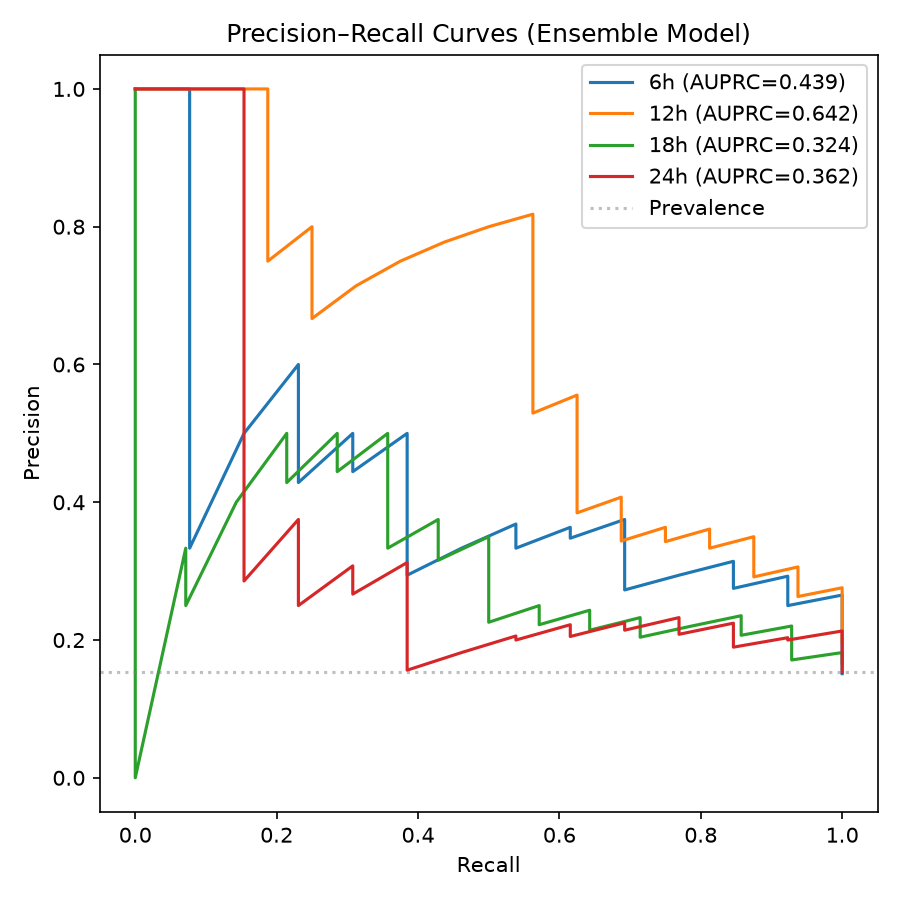

In [73]:
# ===== CELL: Precision-Recall curves, all horizons overlaid =====
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(6,6))

for H in HORIZONS_USE:
    y, p, _ = HORIZON_PREDICTIONS[H]
    prec, rec, _ = precision_recall_curve(y, p)
    ax.plot(rec, prec, label=f'{H}h (AUPRC={average_precision_score(y,p):.3f})')

# Baseline = prevalence
ax.axhline(y.mean(), color='gray', linestyle=':', alpha=0.5, label='Prevalence')

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.setTitle = ax.set_title('Precision–Recall Curves (Ensemble Model)')
ax.legend(loc='best')

plt.tight_layout()

# Save figure
save_path = os.path.join(CKPT_ROOT, 'phase1_pr.png')
plt.savefig(save_path, dpi=150)

# Show in notebook
plt.show()

print(f"Figure saved to: {save_path}")

# Display the saved image below the cell
display(Image(filename=save_path))

Figure saved to: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase1_calibration.png


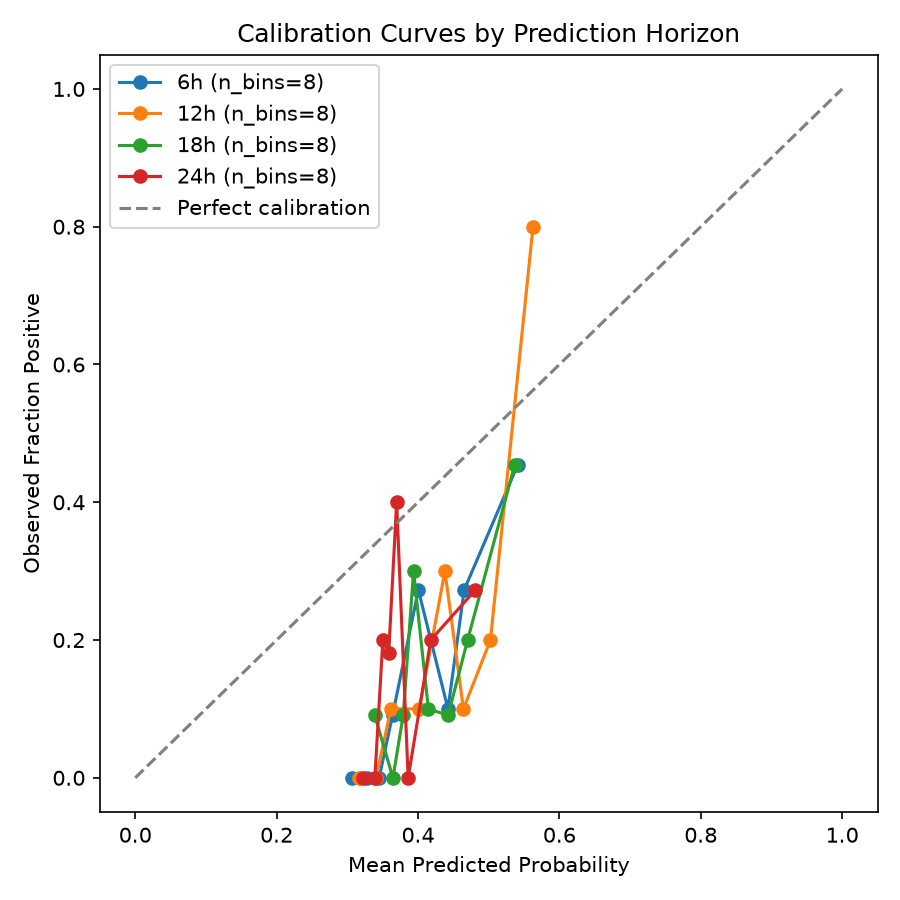

In [74]:
# ===== CELL: Calibration curves =====
from IPython.display import Image, display

fig, ax = plt.subplots(figsize=(6,6))

for H in HORIZONS_USE:
    y, p, _ = HORIZON_PREDICTIONS[H]

    n_bins_used = None
    for n_bins in [8, 5, 3]:
        try:
            frac_pos, mean_pred = calibration_curve(
                y, p,
                n_bins=n_bins,
                strategy='quantile'
            )
            n_bins_used = n_bins
            break
        except Exception:
            continue

    ax.plot(
        mean_pred,
        frac_pos,
        marker='o',
        label=f'{H}h (n_bins={n_bins_used})'
    )

# Perfect calibration reference
ax.plot([0,1], [0,1], '--', color='gray', label='Perfect calibration')

ax.set_xlabel('Mean Predicted Probability')
ax.set_ylabel('Observed Fraction Positive')
ax.set_title('Calibration Curves by Prediction Horizon')
ax.legend(loc='best')

plt.tight_layout()

# Save figure
save_path = os.path.join(CKPT_ROOT, 'phase1_calibration.png')
plt.savefig(save_path, dpi=150)

# Show in notebook
plt.show()

print(f"Figure saved to: {save_path}")

# Display the saved image below the cell
display(Image(filename=save_path))

/tmp/ipykernel_123778/4208360389.py:4: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axes = plt.subplots(1, len(HORIZONS_USE), figsize=(4 * len(HORIZONS_USE), 4))


Figure saved to: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase1_confusion.png


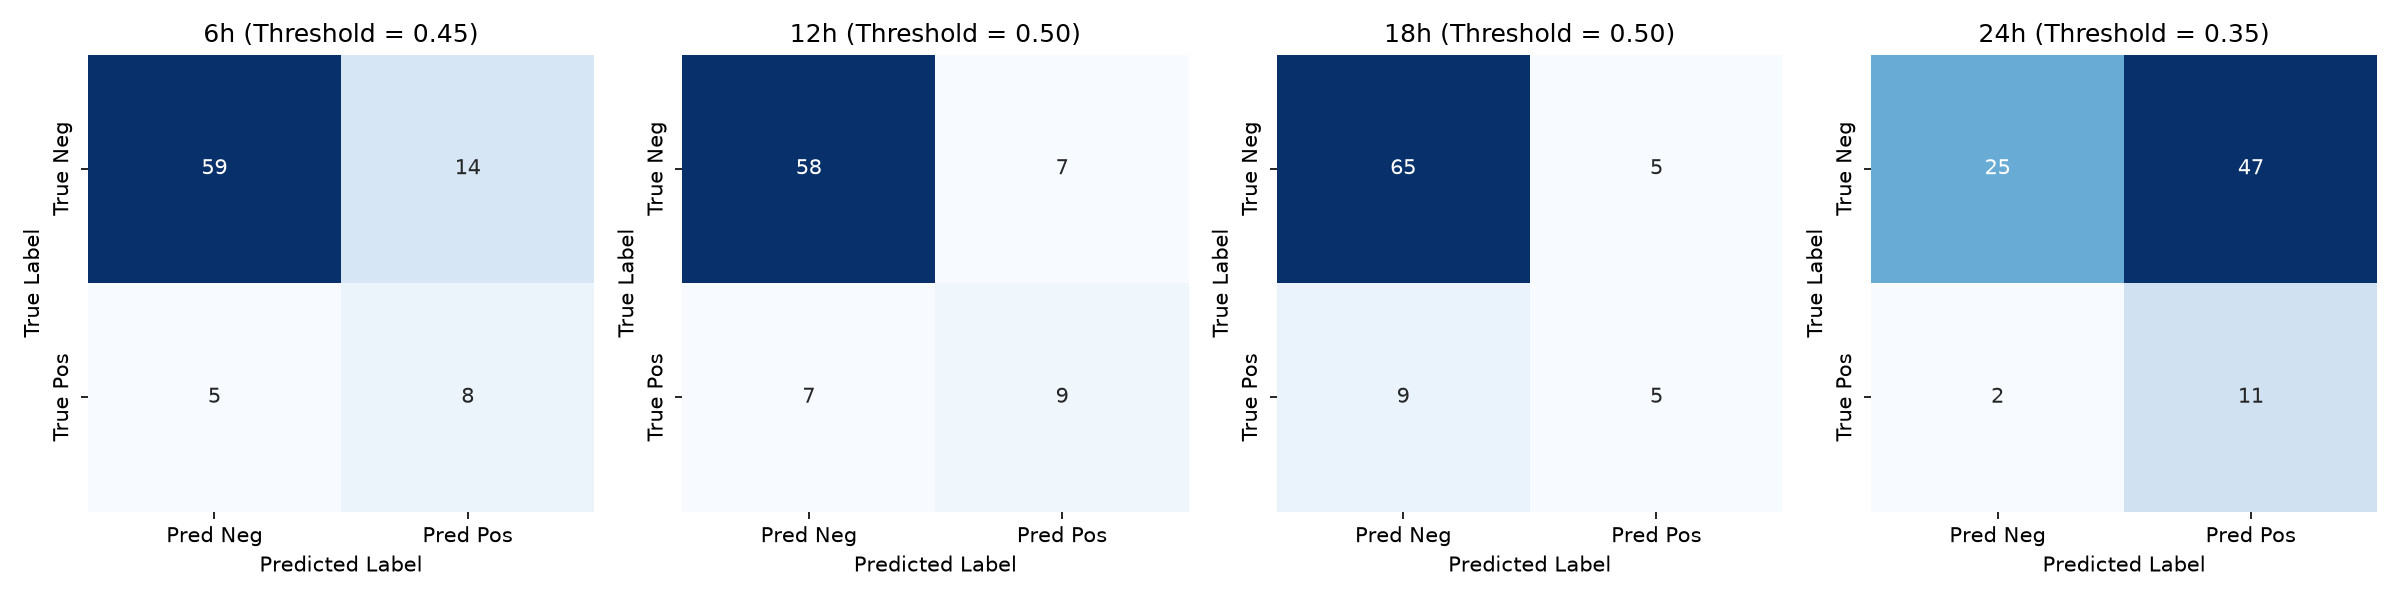

In [75]:
# ===== CELL: Confusion matrices, one per horizon =====
from IPython.display import Image, display

fig, axes = plt.subplots(1, len(HORIZONS_USE), figsize=(4 * len(HORIZONS_USE), 4))

if len(HORIZONS_USE) == 1:
    axes = [axes]

for ax, H in zip(axes, HORIZONS_USE):
    y, p, _ = HORIZON_PREDICTIONS[H]

    # Tuned threshold from ens_df_all
    thr = ens_df_all.loc[ens_df_all.H == H, 'threshold'].values[0]

    cm = confusion_matrix(y, (p >= thr).astype(int))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=ax,
        xticklabels=['Pred Neg', 'Pred Pos'],
        yticklabels=['True Neg', 'True Pos']
    )

    ax.set_title(f'{H}h (Threshold = {thr:.2f})')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()

# Save figure
save_path = os.path.join(CKPT_ROOT, 'phase1_confusion.png')
plt.savefig(save_path, dpi=150)

# Show in notebook
plt.show()

print(f"Figure saved to: {save_path}")

# Display the saved image below the cell
display(Image(filename=save_path))

In [58]:
# ===== CELL: DeLong within a horizon =====
for H in HORIZONS_USE:
    y, p_ens, per_fold = HORIZON_PREDICTIONS[H]
    print(f'\n--- {H}h ---')
    fold_aucs = {f: roc_auc_score(y, pf) for f, pf in per_fold.items()}
    if not fold_aucs:
        continue
    best_fold = max(fold_aucs, key=fold_aucs.get)
    pv = delong_p_value(y, p_ens, per_fold[best_fold])
    print(f'ensemble {roc_auc_score(y,p_ens):.3f} vs best single fold {best_fold} '
          f'({fold_aucs[best_fold]:.3f})  DeLong p={pv:.3f}')
    folds = sorted(per_fold.keys())
    for i in range(len(folds)):
        for j in range(i+1, len(folds)):
            pv = delong_p_value(y, per_fold[folds[i]], per_fold[folds[j]])
            print(f'  fold{folds[i]} ({fold_aucs[folds[i]]:.3f}) vs fold{folds[j]} '
                  f'({fold_aucs[folds[j]]:.3f})  p={pv:.3f}')


--- 6h ---
ensemble 0.811 vs best single fold 3 (0.849)  DeLong p=0.621
  fold0 (0.815) vs fold1 (0.784)  p=0.728
  fold0 (0.815) vs fold2 (0.776)  p=0.611
  fold0 (0.815) vs fold3 (0.849)  p=0.633
  fold0 (0.815) vs fold4 (0.765)  p=0.513
  fold1 (0.784) vs fold2 (0.776)  p=0.929
  fold1 (0.784) vs fold3 (0.849)  p=0.477
  fold1 (0.784) vs fold4 (0.765)  p=0.840
  fold2 (0.776) vs fold3 (0.849)  p=0.364
  fold2 (0.776) vs fold4 (0.765)  p=0.900
  fold3 (0.849) vs fold4 (0.765)  p=0.294

--- 12h ---
ensemble 0.826 vs best single fold 1 (0.818)  DeLong p=0.934
  fold0 (0.796) vs fold1 (0.818)  p=0.829
  fold0 (0.796) vs fold2 (0.730)  p=0.528
  fold0 (0.796) vs fold3 (0.765)  p=0.776
  fold0 (0.796) vs fold4 (0.795)  p=0.992
  fold1 (0.818) vs fold2 (0.730)  p=0.405
  fold1 (0.818) vs fold3 (0.765)  p=0.628
  fold1 (0.818) vs fold4 (0.795)  p=0.801
  fold2 (0.730) vs fold3 (0.765)  p=0.750
  fold2 (0.730) vs fold4 (0.795)  p=0.490
  fold3 (0.765) vs fold4 (0.795)  p=0.761

--- 18h ---


In [59]:
# ===== CELL: F1 and Recall trend, to go with the AUROC/AUPRC trend from before =====
fig, axes = plt.subplots(1, 2, figsize=(12,5))
for ax, metric in zip(axes, ['F1','Recall']):
    s = ens_df_all.sort_values('H')
    ax.plot(s.H, s[metric], marker='o', color='teal')
    ax.set_xlabel('horizon (h)'); ax.set_ylabel(metric); ax.set_title(f'{metric} vs horizon'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(CKPT_ROOT,'phase1_f1_recall_trend.png'), dpi=150); plt.show()

In [60]:
# ===== CELL: composite rank across metrics, answers "which horizon actually wins" =====
rank_df = ens_df_all[['H','AUROC','AUPRC','F1','Recall','Accuracy']].copy()
for m in ['AUROC','AUPRC','F1','Recall','Accuracy']:
    rank_df[f'{m}_rank'] = rank_df[m].rank(ascending=False)
rank_df['mean_rank'] = rank_df[[c for c in rank_df.columns if c.endswith('_rank')]].mean(axis=1)
print(rank_df.sort_values('mean_rank').to_string(index=False))

 H    AUROC    AUPRC       F1   Recall  Accuracy  AUROC_rank  AUPRC_rank  F1_rank  Recall_rank  Accuracy_rank  mean_rank
12 0.833654 0.655007 0.562500 0.562500  0.827160         1.0         1.0      1.0          3.0            2.0        1.6
 6 0.810327 0.428350 0.457143 0.615385  0.779070         2.0         2.0      2.0          2.0            3.0        2.2
18 0.679592 0.330765 0.416667 0.357143  0.833333         3.0         4.0      3.0          4.0            1.0        3.0
24 0.676282 0.358934 0.333333 0.923077  0.435294         4.0         3.0      4.0          1.0            4.0        3.2


In [ ]:
from PIL import Image

In [ ]:
Image.open(path)

In [42]:
# ===== CELL: mirror the two forward() methods, but keep the attention instead of discarding it =====
@torch.no_grad()
def ehr_encoder_forward_with_attn(encoder, x, t, pad_mask):
    h = encoder.lin_in(x) + encoder.temporal_enc(t)
    out, enc_slf_attn = encoder.encoder(h, t, mask=pad_mask)
    valid = ~pad_mask.squeeze(-1)
    att_score = encoder.att_u(torch.tanh(encoder.att_W(out))).squeeze(-1)
    att_score = att_score.masked_fill(~valid, torch.finfo(att_score.dtype).min)
    att_w = torch.softmax(att_score, dim=-1)
    pooled = (out * att_w.unsqueeze(-1)).sum(1)
    return pooled, att_w, enc_slf_attn

@torch.no_grad()
def img_pool_forward_with_attn(img_pool, feats, mask, recency_norm):
    score = img_pool.att_u(torch.tanh(img_pool.att_W(feats))).squeeze(-1)
    score = score - img_pool.recency_weight.abs() * recency_norm
    score = score.masked_fill(~mask, torch.finfo(score.dtype).min)
    w = torch.softmax(score, dim=-1)
    return (feats * w.unsqueeze(-1)).sum(1), w
print("run")

run


In [40]:
# ===== CELL: collect native attention over a horizon's test set =====
HORIZONS_USE = [6, 12, 24, 48]
@torch.no_grad()
def collect_native_attention(H, model, loader, max_batches=None):
    rows = []
    for bi, batch in enumerate(loader):
        if max_batches and bi >= max_batches: break
        x = batch['x'].to(DEVICE); t = batch['t'].to(DEVICE); pm = batch['pad_mask'].to(DEVICE)
        imgs = batch['imgs'].to(DEVICE); img_mask = batch['img_mask'].to(DEVICE)
        recency_norm = batch['recency_norm'].to(DEVICE)
        _, ehr_att, _ = ehr_encoder_forward_with_attn(model.ehr_encoder, x, t, pm)

        x_cpu, t_cpu, att_cpu = x.cpu().numpy(), t.cpu().numpy(), ehr_att.cpu().numpy()
        valid = (~pm.squeeze(-1)).cpu().numpy()
        for b in range(x.shape[0]):
            for k in range(int(valid[b].sum())):
                ch_idx = int(x_cpu[b, k, :N_CH].argmax())
                rows.append({'stay_id': batch['stay_id'][b], 'H': H, 'channel': CH[ch_idx],
                             'time_h': float(t_cpu[b, k]), 'attn': float(att_cpu[b, k])})
    return pd.DataFrame(rows)

attn_records = {}
for H in HORIZONS_USE:
    fold, val_auc = best_fold_for_horizon(H)
    print(f'H={H}h -> representative fold {fold} (val AUROC {val_auc:.3f})')
    model = load_fold_model(H, fold)
    _, loader = get_test_loader(H)
    attn_records[H] = collect_native_attention(H, model, loader)
    del model
    if DEVICE.type == 'cuda': gc.collect(); torch.cuda.empty_cache()

all_attn = pd.concat(attn_records.values(), ignore_index=True)

NameError: name 'best_fold_for_horizon' is not defined

In [47]:
from PIL import Image
import matplotlib.pyplot as plt

img_path = "/workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_channel_attn.png"

img = Image.open(img_path)

print("Format:", img.format)
print("Mode:", img.mode)
print("Size:", img.size)

plt.figure(figsize=(12,8))
plt.imshow(img)
plt.axis("off")
plt.show()

Format: PNG
Mode: RGBA
Size: (1500, 900)


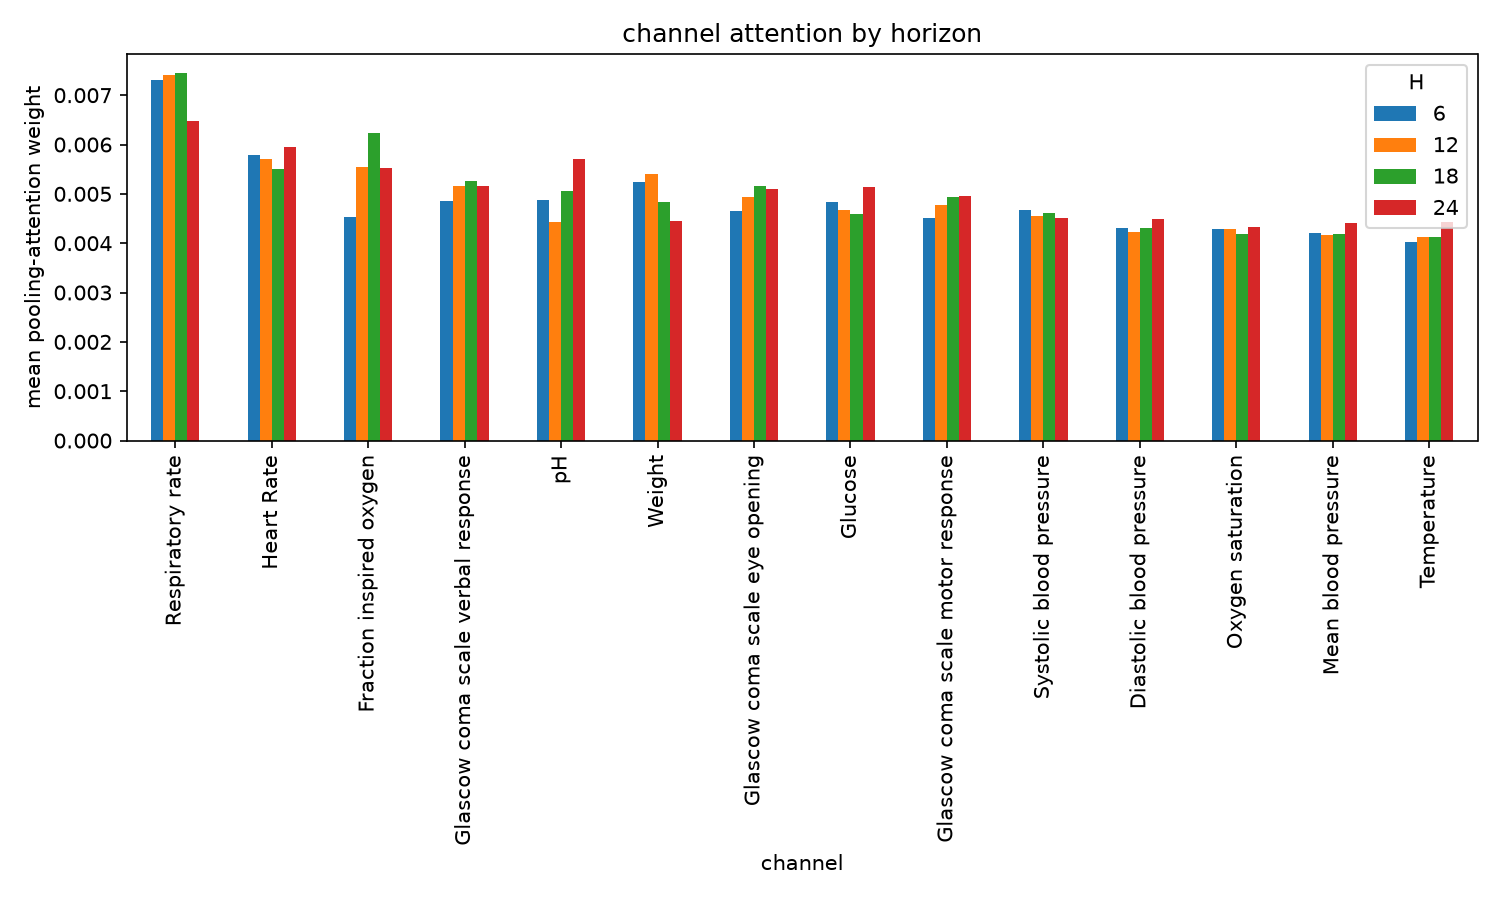

In [48]:
display(img)

In [46]:
import os

img_path = "/workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_channel_attn.png"

print(os.path.exists(img_path))
print(os.path.getsize(img_path) if os.path.exists(img_path) else "Not found")

True
101697


In [68]:
from IPython.display import display
from PIL import Image

# ---------------- Channel attention plot ----------------
piv = all_attn.groupby(['H', 'channel'])['attn'].mean().unstack('H')
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(10,6))
piv.plot(kind='bar', ax=ax)

ax.set_ylabel('Mean pooling-attention weight')
ax.set_title('Channel Attention by Horizon')

plt.tight_layout()

channel_fig = os.path.join(CKPT_ROOT, 'phase2_channel_attn.png')
plt.savefig(channel_fig, dpi=150)

print(f"✓ Saved: {channel_fig}")

plt.show()

# Display saved image
display(Image.open(channel_fig))


# ---------------- Attention vs recency ----------------
all_attn['hrs_before_cutoff'] = TRAIN_WINDOW - all_attn['time_h']

fig, ax = plt.subplots(figsize=(8,5))

for H in HORIZONS_USE:
    sub = all_attn[all_attn.H == H]
    binned = sub.groupby(
        pd.cut(sub['hrs_before_cutoff'], bins=12, labels=False)
    )['attn'].mean()

    ax.plot(binned.index, binned.values, marker='o', label=f'{H}h')

ax.set_xlabel('Bin (0 = most recent, 11 = most distant)')
ax.set_ylabel('Mean attention')
ax.set_title('Attention vs Recency')
ax.legend()

plt.tight_layout()

recency_fig = os.path.join(CKPT_ROOT, 'phase2_attn_recency.png')
plt.savefig(recency_fig, dpi=150)

print(f"✓ Saved: {recency_fig}")

plt.show()

# Display saved image
display(Image.open(recency_fig))

NameError: name 'all_attn' is not defined

✓ Found: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_attn_recency.png
File size: 86,982 bytes


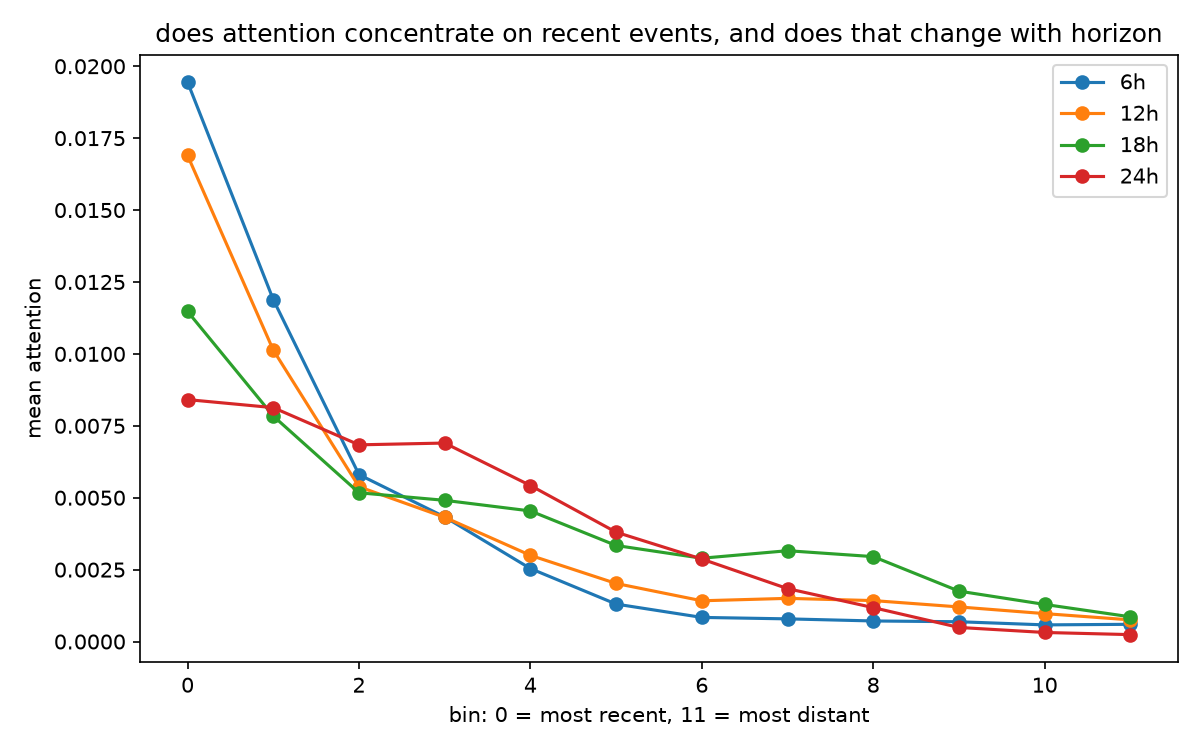

In [50]:
import os
from IPython.display import display, Image

# Path
recency_fig = os.path.join(CKPT_ROOT, "phase2_attn_recency.png")

# Check if file exists
if os.path.exists(recency_fig):
    print(f"✓ Found: {recency_fig}")
    print(f"File size: {os.path.getsize(recency_fig):,} bytes")

    # Display image
    display(Image(filename=recency_fig))
else:
    print("✗ Image not found!")

In [56]:
import os
import pandas as pd
from datetime import datetime

RESULT_DIR = os.path.join(CKPT_ROOT, "shapley_results")
os.makedirs(RESULT_DIR, exist_ok=True)

FEATURE_CSV = os.path.join(RESULT_DIR, "feature_shapley.csv")
MODALITY_CSV = os.path.join(RESULT_DIR, "modality_shapley.csv")
ERROR_CSV = os.path.join(RESULT_DIR, "error_log.csv")
print("saved")

saved


In [57]:
if os.path.exists(FEATURE_CSV):
    done_feat = pd.read_csv(FEATURE_CSV)
    processed = set(zip(done_feat.H, done_feat.stay_id))
    
else:
    processed = set()

print("Already finished patients:", len(processed))

Already finished patients: 0


In [58]:
# ===== CELL: split the model into a cheap-to-rerun EHR path and an expensive CXR path (cached once) =====
@torch.no_grad()
def get_cxr_feat_cached(model, imgs, img_mask, recency_norm):
    B, K, C, Hh, W = imgs.shape
    flat = model.cxr_model(imgs.reshape(B*K, C, Hh, W))
    flat = model.projection(flat).reshape(B, K, -1)
    cxr_feat, _ = img_pool_forward_with_attn(model.img_pool, flat, img_mask, recency_norm)
    return cxr_feat

@torch.no_grad()
def ehr_feat_from_events(model, x, t, pad_mask):
    pooled, _, _ = ehr_encoder_forward_with_attn(model.ehr_encoder, x, t, pad_mask)
    return pooled

@torch.no_grad()
def predict_from_feats(model, ehr_feat, cxr_feat):
    return torch.sigmoid(model.head(torch.cat([ehr_feat, cxr_feat], dim=-1)).squeeze(-1))

In [44]:
print("img_pool_forward_with_attn" in globals())

True


In [59]:
# ===== CELL: pruning curve for one patient -- prediction as a function of how far back we keep events =====
from PIL import Image
@torch.no_grad()
def pruning_curve(model, x, t, pad_mask, cxr_feat):
    valid_idx = (~pad_mask.squeeze(0).squeeze(-1)).nonzero(as_tuple=True)[0]
    x_v, t_v = x[:, valid_idx, :], t[:, valid_idx]
    T = len(valid_idx)
    probs = []
    for k in range(0, T+1):
        if k == 0:
            feat = model.missing_ehr.unsqueeze(0)   # model's own learned "no EHR" embedding
        else:
            xk, tk = x_v[:, T-k:, :], t_v[:, T-k:]
            pmk = torch.zeros(1, k, 1, dtype=torch.bool, device=x.device)
            feat = ehr_feat_from_events(model, xk, tk, pmk)
        probs.append(predict_from_feats(model, feat, cxr_feat).item())
    return np.array(probs)

def plot_pruning_curve(probs, H, stay_id):
    fig, ax = plt.subplots(figsize=(7,4))
    ax.plot(range(len(probs)), probs, marker='o')
    ax.set_xlabel('# most-recent events kept (rest genuinely removed)')
    ax.set_ylabel('predicted mortality probability')
    ax.set_title(f'pruning curve, stay {stay_id}, {H}h'); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def find_pruning_cutoff(probs, tol=0.02):
    target = probs[-1]
    for k in range(len(probs)):
        if all(abs(p - target) < tol for p in probs[k:]):
            return k
    return len(probs) - 1

# example: run on the first patient of each horizon's test set
for H in HORIZONS_USE:
    fold, _ = best_fold_for_horizon(H)
    model = load_fold_model(H, fold)
    _, loader = get_test_loader(H, batch_size=1)
    batch = next(iter(loader))
    x, t = batch['x'].to(DEVICE), batch['t'].to(DEVICE)
    pm = batch['pad_mask'].to(DEVICE)
    imgs, img_mask = batch['imgs'].to(DEVICE), batch['img_mask'].to(DEVICE)
    recency_norm = batch['recency_norm'].to(DEVICE)
    cxr_feat = get_cxr_feat_cached(model, imgs, img_mask, recency_norm)
    probs = pruning_curve(model, x, t, pm, cxr_feat)
    cutoff = find_pruning_cutoff(probs)
    print(f'{H}h stay {batch["stay_id"][0]}: relevant window = last {len(probs)-1-cutoff} of {len(probs)-1} events')
    plot_pruning_curve(probs, H, batch['stay_id'][0])
    del model
    if DEVICE.type == 'cuda': gc.collect(); torch.cuda.empty_cache()

  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
6h stay 34001306: relevant window = last 194 of 200 events
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
12h stay 34001306: relevant window = last 190 of 200 events
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
18h stay 34001306: relevant window = last 135 of 200 events
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
24h stay 34001306: relevant window = last 187 of 200 events


In [60]:
# ===== CELL: event-level Shapley within the relevant (post-pruning) window =====
@torch.no_grad()
def event_level_shapley(model, x, t, pad_mask, cxr_feat, window_start_idx, n_samples=150, seed=0):
    rng = np.random.default_rng(seed)
    valid_idx = (~pad_mask.squeeze(0).squeeze(-1)).nonzero(as_tuple=True)[0]
    x_win, t_win = x[:, valid_idx[window_start_idx:], :], t[:, valid_idx[window_start_idx:]]
    n = x_win.shape[1]
    if n == 0:
        return np.array([])
    baseline_feat = model.missing_ehr.unsqueeze(0)
    phi = np.zeros(n)
    for _ in range(n_samples):
        perm = rng.permutation(n)
        included, prev_pred = [], predict_from_feats(model, baseline_feat, cxr_feat).item()
        for idx in perm:
            included.append(idx); sel = sorted(included)
            xk, tk = x_win[:, sel, :], t_win[:, sel]
            pmk = torch.zeros(1, len(sel), 1, dtype=torch.bool, device=x.device)
            pred = predict_from_feats(model, ehr_feat_from_events(model, xk, tk, pmk), cxr_feat).item()
            phi[idx] += (pred - prev_pred); prev_pred = pred
    return phi / n_samples

In [61]:
# ===== CELL: feature-level (channel) Shapley -- "removing" a channel = drop every event on it =====
@torch.no_grad()
def feature_level_shapley(model, x, t, pad_mask, cxr_feat, n_samples=150, seed=1):
    rng = np.random.default_rng(seed)
    valid_idx = (~pad_mask.squeeze(0).squeeze(-1)).nonzero(as_tuple=True)[0]
    x_v, t_v = x[:, valid_idx, :], t[:, valid_idx]
    ch_of_event = x_v[0, :, :N_CH].cpu().numpy().argmax(axis=1)
    baseline_feat = model.missing_ehr.unsqueeze(0)
    phi = np.zeros(N_CH)
    for _ in range(n_samples):
        perm = rng.permutation(N_CH)
        included, prev_pred = set(), predict_from_feats(model, baseline_feat, cxr_feat).item()
        for ch in perm:
            included.add(ch)
            keep = np.isin(ch_of_event, list(included))
            if keep.sum() == 0:
                pred = prev_pred
            else:
                sel = np.where(keep)[0]
                pmk = torch.zeros(1, len(sel), 1, dtype=torch.bool, device=x.device)
                pred = predict_from_feats(model, ehr_feat_from_events(model, x_v[:, sel, :], t_v[:, sel], pmk), cxr_feat).item()
            phi[ch] += (pred - prev_pred); prev_pred = pred
    return phi / n_samples

In [62]:
# ===== CELL: exact EHR-vs-CXR Shapley, 4 coalitions, no sampling needed =====
@torch.no_grad()
def modality_shapley(model, x, t, pad_mask, imgs, img_mask, recency_norm):
    ehr_feat = ehr_feat_from_events(model, x, t, pad_mask)
    cxr_feat = get_cxr_feat_cached(model, imgs, img_mask, recency_norm)
    miss_ehr, miss_cxr = model.missing_ehr.unsqueeze(0), model.missing_cxr.unsqueeze(0)
    v00 = predict_from_feats(model, miss_ehr, miss_cxr).item()
    v10 = predict_from_feats(model, ehr_feat, miss_cxr).item()
    v01 = predict_from_feats(model, miss_ehr, cxr_feat).item()
    v11 = predict_from_feats(model, ehr_feat, cxr_feat).item()
    phi_ehr = 0.5*(v10-v00) + 0.5*(v11-v01)
    phi_cxr = 0.5*(v01-v00) + 0.5*(v11-v10)
    return {'EHR': phi_ehr, 'CXR': phi_cxr, 'full_pred': v11, 'base_pred': v00}

In [63]:
# ===== CELL: query the ODE-based attention at a dense, continuous time grid =====
@torch.no_grad()
def continuous_query(encoder, x, t, pad_mask, qt):
    h = encoder.lin_in(x) + encoder.temporal_enc(t)
    slf_attn = encoder.encoder.slf_attn
    qt_b = qt.unsqueeze(0).to(x.device)
    q_in = slf_attn.layer_norm(h) if slf_attn.normalize_before else h
    d_k, n_head = slf_attn.d_k, slf_attn.n_head
    sz_b, len_k, len_qt = h.size(0), h.size(1), qt_b.size(1)

    valid_mask = (~pad_mask).float()  # invert: interpolate's convention wants True/1 = valid
    q = slf_attn.w_qs.interpolate(q_in, t, qt_b, mask=valid_mask).view(sz_b, len_qt, len_k, -1, n_head, d_k)
    k = slf_attn.w_ks.interpolate(h, t, qt_b).view(sz_b, len_qt, len_k, -1, n_head, d_k)
    v = slf_attn.w_vs.interpolate(h, t, qt_b).view(sz_b, len_qt, len_k, -1, n_head, d_k)
    q, k, v = q.permute(0,4,1,2,3,5), k.permute(0,4,1,2,3,5), v.permute(0,4,1,2,3,5)

    m = valid_mask.squeeze(-1)[:, None, None, :]
    print("q shape    :", q.shape)
    print("k shape    :", k.shape)
    print("v shape    :", v.shape)
    print("mask shape :", m.shape)
    output, attn = slf_attn.attention.interpolate(q, k, v, mask=m)
    output = output.transpose(1, 2).contiguous().view(sz_b, len_qt, -1)
    hidden_at_qt = slf_attn.fc(output)
    attn_at_qt = attn.mean(dim=1)  # average heads -> (1, Q, T)
    return hidden_at_qt, attn_at_qt

In [64]:
# ===== CELL: plot a patient's continuous trajectory + continuous attention (PCA by default) =====
def project_trajectory(H_np, method='pca'):
    if method == 'pca':
        return PCA(n_components=2).fit_transform(H_np)
    if method == 'umap':
        import umap
        return umap.UMAP(n_components=2, random_state=42).fit_transform(H_np)
    if method == 'tsne':
        from sklearn.manifold import TSNE
        perp = max(2, min(30, len(H_np) - 1))
        return TSNE(n_components=2, random_state=42, perplexity=perp).fit_transform(H_np)
    raise ValueError(method)

@torch.no_grad()
def plot_continuous_trajectory(model, batch, idx, H, n_query=300, method='pca'):
    x = batch['x'][idx:idx+1].to(DEVICE); t = batch['t'][idx:idx+1].to(DEVICE)
    pad_mask = batch['pad_mask'][idx:idx+1].to(DEVICE)
    real_t = t[0][(~pad_mask[0].squeeze(-1))].cpu().numpy()
    qt = torch.linspace(0, TRAIN_WINDOW, n_query)
    print("x:", x.shape)
    print("t:", t.shape)
    print("pad_mask:", pad_mask.shape)
    print("qt:", qt.shape)
    hidden_at_qt, attn_at_qt = continuous_query(model.ehr_encoder, x, t, pad_mask, qt)
    pcs = project_trajectory(hidden_at_qt[0].cpu().numpy(), method=method)

    fig, axes = plt.subplots(1, 2, figsize=(13,5))
    sc = axes[0].scatter(pcs[:,0], pcs[:,1], c=qt.numpy(), cmap='viridis', s=10)
    axes[0].plot(pcs[:,0], pcs[:,1], color='gray', alpha=0.3, lw=0.8)
    plt.colorbar(sc, ax=axes[0], label='time (h)')
    for rt in real_t:
        near = int(np.argmin(np.abs(qt.numpy() - rt)))
        axes[0].scatter(pcs[near,0], pcs[near,1], color='red', marker='x', s=60, zorder=5)
    axes[0].set_title(f'continuous trajectory ({method}), stay {batch["stay_id"][idx]}, {H}h')

    attn_np = attn_at_qt[0].cpu().numpy()
    axes[1].imshow(attn_np.T, aspect='auto', cmap='magma', extent=[0, TRAIN_WINDOW, len(real_t), 0])
    axes[1].set_xlabel('query time (h)'); axes[1].set_ylabel('event index'); axes[1].set_title('continuous attention')
    plt.tight_layout(); plt.savefig(os.path.join(CKPT_ROOT, f'phase2_trajectory_{H}h_{method}.png'), dpi=150); plt.show()

for H in HORIZONS_USE:
    fold, _ = best_fold_for_horizon(H)
    model = load_fold_model(H, fold)
    _, loader = get_test_loader(H, batch_size=2)
    batch = next(iter(loader))
    plot_continuous_trajectory(model, batch, 0, H, method='pca')
    del model
    if DEVICE.type == 'cuda': gc.collect(); torch.cuda.empty_cache()

  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
x: torch.Size([1, 200, 19])
t: torch.Size([1, 200])
pad_mask: torch.Size([1, 200, 1])
qt: torch.Size([300])
q shape    : torch.Size([1, 4, 300, 200, 2, 8])
k shape    : torch.Size([1, 4, 300, 200, 2, 8])
v shape    : torch.Size([1, 4, 300, 200, 2, 8])
mask shape : torch.Size([1, 1, 1, 200])
>>> ENTER interpolate <<<
ATTN SHAPE: torch.Size([1, 4, 300, 200])
MASK SHAPE: torch.Size([1, 1, 1, 200])
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
x: torch.Size([1, 200, 19])
t: torch.Size([1, 200])
pad_mask: torch.Size([1, 200, 1])
qt: torch.Size([300])
q shape    : torch.Size([1, 4, 300, 200, 2, 8])
k shape    : torch.Size([1, 4, 300, 200, 2, 8])
v shape    : torch.Size([1, 4, 300, 200, 2, 8])
mask shape : torch.Size([1, 1, 1, 200])
>>> ENTER interpolate <<<
ATTN SHAPE: torch.Size([1, 4, 300, 200])
MASK SHAPE: torch.Size([1

In [65]:
# ===== CELL: optional -- try UMAP / t-SNE instead of PCA on one horizon's first test patient =====
fold, _ = best_fold_for_horizon(HORIZONS_USE[0])
model = load_fold_model(HORIZONS_USE[0], fold)
_, loader = get_test_loader(HORIZONS_USE[0], batch_size=1)
batch = next(iter(loader))
for method in ['umap', 'tsne']:
    try:
        plot_continuous_trajectory(model, batch, 0, HORIZONS_USE[0], method=method)
    except ImportError:
        print(f'{method} not installed, run: pip install umap-learn --quiet')
del model
if DEVICE.type == 'cuda': gc.collect(); torch.cuda.empty_cache()

  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
x: torch.Size([1, 200, 19])
t: torch.Size([1, 200])
pad_mask: torch.Size([1, 200, 1])
qt: torch.Size([300])
q shape    : torch.Size([1, 4, 300, 200, 2, 8])
k shape    : torch.Size([1, 4, 300, 200, 2, 8])
v shape    : torch.Size([1, 4, 300, 200, 2, 8])
mask shape : torch.Size([1, 1, 1, 200])
>>> ENTER interpolate <<<
ATTN SHAPE: torch.Size([1, 4, 300, 200])
MASK SHAPE: torch.Size([1, 1, 1, 200])
umap not installed, run: pip install umap-learn --quiet
x: torch.Size([1, 200, 19])
t: torch.Size([1, 200])
pad_mask: torch.Size([1, 200, 1])
qt: torch.Size([300])
q shape    : torch.Size([1, 4, 300, 200, 2, 8])
k shape    : torch.Size([1, 4, 300, 200, 2, 8])
v shape    : torch.Size([1, 4, 300, 200, 2, 8])
mask shape : torch.Size([1, 1, 1, 200])
>>> ENTER interpolate <<<
ATTN SHAPE: torch.Size([1, 4, 300, 200])
MASK SHAPE: torch.Size([1, 1, 1, 200])


In [72]:
# ===== CELL: global feature-level + modality-level Shapley, per horizon =====
import time
def aggregate_interpretability(H, fold, model, loader, n_patients=30, n_samples_feat=150, seed=0):

    feat_rows, mod_rows = [], []
    already_done = len(processed)
    if already_done >= n_patients:
        print(f"Already have {already_done} patients. Nothing to do.")
        return None, None
    count = 0
    print(f"Already processed : {already_done}")
    print(f"Need to process   : {n_patients-already_done}")

    print(f"\n========== Horizon {H}h ==========")

    for batch_id, batch in enumerate(loader):

        print(f"\nLoading batch {batch_id+1} ...")

        for b in range(batch['x'].shape[0]):

            if already_done + count >= n_patients:
                break

            stay = batch['stay_id'][b]
            if (H, stay) in processed:
                print(f"Skipping stay {stay}")
                continue

            print("\n------------------------------------------------")
            print(f"Patient {already_done + count + 1}/{n_patients}")
            print(f"Stay ID : {stay}")

            x = batch['x'][b:b+1].to(DEVICE)
            t = batch['t'][b:b+1].to(DEVICE)
            pm = batch['pad_mask'][b:b+1].to(DEVICE)

            imgs = batch['imgs'][b:b+1].to(DEVICE)
            img_mask = batch['img_mask'][b:b+1].to(DEVICE)
            recency_norm = batch['recency_norm'][b:b+1].to(DEVICE)
            start_time = time.time()

            try:

                print("Step 1/3 : Computing CXR feature...")
                cxr_feat = get_cxr_feat_cached(
                    model,
                    imgs,
                    img_mask,
                    recency_norm
                )
                print("✓ CXR feature done")

                print("Step 2/3 : Computing Feature-Level Shapley...")
                phi_feat = feature_level_shapley(
                    model,
                    x,
                    t,
                    pm,
                    cxr_feat,
                    n_samples=n_samples_feat,
                    seed=seed+count
                )
                print("✓ Feature-Level Shapley done")
                elapsed = time.time() - start_time

                

                for ci, chn in enumerate(CH):
                    feat_rows.append({
                        'H': H,
                        'fold': fold,
                        'stay_id': stay,
                        'patient_index': already_done + count + 1,
                        'channel': chn,
                        'channel_index': ci,
                        'shapley': phi_feat[ci],
                        'n_events': int((~pm.squeeze().cpu()).sum()),
                        'seed': seed + count,
                        'n_samples': n_samples_feat,
                        'processing_time_sec': elapsed,
                        'timestamp': datetime.now()
                        
                        
                        
                    })

                feat_df = pd.DataFrame(feat_rows)
                feat_df.to_csv(
                    FEATURE_CSV,
                    mode='a',
                    header=not os.path.exists(FEATURE_CSV),
                    index=False
                )
                
                feat_rows.clear()
                
                
                    

                print("Step 3/3 : Computing Modality Shapley...")

                mod = modality_shapley(
                    model,
                    x,
                    t,
                    pm,
                    imgs,
                    img_mask,
                    recency_norm
                )
               

                print("✓ Modality Shapley done")

                mod_rows.append({
                    'H': H,
                    'fold': fold,
                    'stay_id': stay,
                    'patient_index': already_done + count + 1,
                    **mod,
                    'processing_time_sec': elapsed,
                    'timestamp': datetime.now()
                })
                mod_df = pd.DataFrame(mod_rows)
                
                mod_df.to_csv(
                    MODALITY_CSV,
                    mode='a',
                    header=not os.path.exists(MODALITY_CSV),
                    index=False
                )
                processed.add((H, stay)) 
                count += 1
                
                mod_rows.clear()    
                    
                    
                

                print("✓ Patient finished")

            except Exception as e:
                err = pd.DataFrame([{
                    "H": H,
                    "fold": fold,
                    "stay_id": stay,
                    "error": str(e),
                    "time": datetime.now()
                    }])
                err.to_csv(  
                    ERROR_CSV,
                    mode='a',
                    header=not os.path.exists(ERROR_CSV),
                    index=False
                )
                    
                    
                print(f"❌ ERROR for stay {stay}")
                print(e)

           

        if already_done + count >= n_patients:
            break

    print(f"\nFinished Horizon {H}h")
    print(f"Patients processed : {count}")
    print(f"Completed : {already_done + count}/{n_patients}")

    return None, None




for H in HORIZONS_USE:

    print("\n===================================================")
    print(f"Starting Horizon {H}h")
    print("===================================================")

    fold, _ = best_fold_for_horizon(H)

    print("Loading model...")
    model = load_fold_model(H, fold)
    print("✓ Model loaded")

    print("Loading test loader...")
    _, loader = get_test_loader(H, batch_size=4)
    print("✓ Loader ready")

    fdf, mdf = aggregate_interpretability(
        H,
        fold,
        model,
        loader,
        n_patients=30,
        n_samples_feat=150
    )


    print(f"Finished Horizon {H}h")

    del model

    if DEVICE.type == "cuda":
        gc.collect()
        torch.cuda.empty_cache()

print("\n====================================")
print("Results already saved to CSV.")
print("Done!")
print("Feature results saved to :", FEATURE_CSV)
print("Modality results saved to :", MODALITY_CSV)
print("Error log :", ERROR_CSV)
print("="*60)


Starting Horizon 6h
Loading model...
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
✓ Model loaded
Loading test loader...
✓ Loader ready
Already have 30 patients. Nothing to do.
Finished Horizon 6h

Starting Horizon 12h
Loading model...
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
✓ Model loaded
Loading test loader...
✓ Loader ready
Already have 30 patients. Nothing to do.
Finished Horizon 12h

Starting Horizon 18h
Loading model...
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
✓ Model loaded
Loading test loader...
✓ Loader ready
Already have 30 patients. Nothing to do.
Finished Horizon 18h

Starting Horizon 24h
Loading model...
  MedFuseCXR: 2,160,128/6,953,856 params trainable (31.1%) -- frozen everything but ('denseblock4', 'norm5')
✓ Model loaded
Loading test loader...
✓ Loader ready
Already have

In [80]:
# =====================================================
# CELL 1 : Load CSV + Sanity Check
# =====================================================

import pandas as pd
import numpy as np
import os
from IPython.display import display

feat_all = pd.read_csv(FEATURE_CSV)
mod_all = pd.read_csv(MODALITY_CSV)

print("="*70)
print("Feature CSV :", FEATURE_CSV)
print("Modality CSV:", MODALITY_CSV)
print("="*70)

print("Feature Shape :", feat_all.shape)
print("Modality Shape:", mod_all.shape)

print("\nFeature Columns")
print(feat_all.columns.tolist())

print("\nModality Columns")
print(mod_all.columns.tolist())

print("\nFirst 5 Feature Rows")
display(feat_all.head())

print("\nFirst 5 Modality Rows")
display(mod_all.head())

print("\nUnique Patients :", feat_all["stay_id"].nunique())
print("Unique Features :", feat_all["channel"].nunique())

print("\nMissing Values")
display(feat_all.isnull().sum())

print("\nPatients per Horizon")
display(
    feat_all.groupby("H")["stay_id"]
    .nunique()
    .reset_index(name="Patients")
)

Feature CSV : /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/shapley_results/feature_shapley.csv
Modality CSV: /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/shapley_results/modality_shapley.csv
Feature Shape : (510, 12)
Modality Shape: (30, 10)

Feature Columns
['H', 'fold', 'stay_id', 'patient_index', 'channel', 'channel_index', 'shapley', 'n_events', 'seed', 'n_samples', 'processing_time_sec', 'timestamp']

Modality Columns
['H', 'fold', 'stay_id', 'patient_index', 'EHR', 'CXR', 'full_pred', 'base_pred', 'processing_time_sec', 'timestamp']

First 5 Feature Rows


,H,fold,stay_id,patient_index,channel,channel_index,shapley,n_events,seed,n_samples,processing_time_sec,timestamp
0,6,0,34001306,1,Capillary refill rate,0,0.000088,200,0,150,2444.672017,2026-08-04 04:05:13.837053
1,6,0,34001306,1,Diastolic blood pressure,1,-0.011679,200,0,150,2444.672017,2026-08-04 04:05:13.837152
2,6,0,34001306,1,Fraction inspired oxygen,2,NaN,200,0,150,2444.672017,2026-08-04 04:05:13.837200
3,6,0,34001306,1,Glascow coma scale eye opening,3,NaN,200,0,150,2444.672017,2026-08-04 04:05:13.837257
4,6,0,34001306,1,Glascow coma scale motor response,4,-0.004492,200,0,150,2444.672017,2026-08-04 04:05:13.837298



First 5 Modality Rows


,H,fold,stay_id,patient_index,EHR,CXR,full_pred,base_pred,processing_time_sec,timestamp
0,6,0,34001306,1,0.063162,-0.072774,0.330630,0.340242,2444.672017,2026-08-04 04:05:14.872229
1,6,0,31736067,2,0.021649,-0.079791,0.282099,0.340242,2336.303110,2026-08-04 04:44:12.131536
2,6,0,30510626,3,0.027837,-0.049696,0.318383,0.340242,2397.131916,2026-08-04 05:24:10.227622
3,6,0,34404648,4,0.048442,-0.088929,0.299755,0.340242,2402.652673,2026-08-04 06:04:13.943714
4,6,0,33613209,5,0.071015,-0.102277,0.308979,0.340242,2422.991235,2026-08-04 06:44:38.255341



Unique Patients : 30
Unique Features : 17

Missing Values


H                        0
fold                     0
stay_id                  0
patient_index            0
channel                  0
channel_index            0
shapley                273
n_events                 0
seed                     0
n_samples                0
processing_time_sec      0
timestamp                0
dtype: int64


Patients per Horizon


,H,Patients
0,6,30


In [84]:
# =====================================================
# CELL 2 : Global Feature Importance
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns

summary = (
    feat_all
    .groupby("channel")["shapley"]
    .agg(
        Mean="mean",
        Std="std",
        Median="median"
    )
)

summary["AbsMean"] = summary["Mean"].abs()

summary = summary.sort_values(
    "AbsMean",
    ascending=False
)

display(summary.round(4))

plt.figure(figsize=(7,8))

sns.heatmap(
    summary[["Mean"]],
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0
)

plt.title("Global Feature Importance (6h)")
plt.tight_layout()

save_path = os.path.join(
    CKPT_ROOT,
    "phase2_6h_global_feature_shapley.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

print(save_path)

,Mean,Std,Median,AbsMean
channel,,,,
Diastolic blood pressure,-0.0089,0.0052,-0.0074,0.0089
Glascow coma scale verbal response,-0.0070,0.0067,-0.0044,0.0070
Oxygen saturation,-0.0070,0.0055,-0.0058,0.0070
Glascow coma scale motor response,-0.0058,0.0054,-0.0035,0.0058
Heart Rate,0.0057,0.0303,-0.0013,0.0057
Temperature,-0.0055,0.0032,-0.0049,0.0055
Respiratory rate,-0.0052,0.0241,-0.0122,0.0052
Systolic blood pressure,-0.0043,0.0279,-0.0029,0.0043
Glascow coma scale eye opening,-0.0042,0.0029,-0.0035,0.0042


/workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_6h_global_feature_shapley.png


In [85]:
# =====================================================
# CELL 3 : Modality Analysis
# =====================================================

mod_long = mod_all.melt(
    id_vars=["stay_id"],
    value_vars=["EHR","CXR"],
    var_name="Modality",
    value_name="Shapley"
)

display(mod_long.head())

summary = (
    mod_long
    .groupby("Modality")["Shapley"]
    .agg(
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max"
    )
)

print(summary)

display(summary.round(4))

plt.figure(figsize=(5,5))

sns.boxplot(
    data=mod_long,
    x="Modality",
    y="Shapley"
)

plt.title("Modality Contribution")

plt.tight_layout()

save_path=os.path.join(
    CKPT_ROOT,
    "phase2_6h_modality_boxplot.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

,stay_id,Modality,Shapley
0,34001306,EHR,0.063162
1,31736067,EHR,0.021649
2,30510626,EHR,0.027837
3,34404648,EHR,0.048442
4,33613209,EHR,0.071015


              Mean       Std    Median       Min       Max
Modality                                                  
CXR      -0.034390  0.084628 -0.071269 -0.102277  0.189438
EHR       0.015344  0.055380  0.003159 -0.088377  0.165578


,Mean,Std,Median,Min,Max
Modality,,,,,
CXR,-0.0344,0.0846,-0.0713,-0.1023,0.1894
EHR,0.0153,0.0554,0.0032,-0.0884,0.1656


In [86]:
# =====================================================
# CELL 4 : Feature Variability
# =====================================================

cv = (
    feat_all
    .groupby("channel")["shapley"]
    .agg(
        Mean="mean",
        Std="std"
    )
)

cv["AbsMean"] = cv["Mean"].abs()

cv["CV"] = cv["Std"]/(cv["AbsMean"]+1e-8)

cv = cv.sort_values("CV")

display(cv.round(4))

plt.figure(figsize=(10,5))

sns.barplot(
    x=cv.index,
    y=cv["CV"]
)

plt.xticks(rotation=60)

plt.ylabel("Coefficient of Variation")

plt.title("Feature Stability")

plt.tight_layout()

save_path=os.path.join(
    CKPT_ROOT,
    "phase2_6h_feature_variability.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

print("\nMost Stable Features")
display(cv.head(5).round(4))

print("\nMost Variable Features")
display(cv.tail(5).round(4))

,Mean,Std,AbsMean,CV
channel,,,,
Temperature,-0.0055,0.0032,0.0055,0.5849
Diastolic blood pressure,-0.0089,0.0052,0.0089,0.5875
Glascow coma scale eye opening,-0.0042,0.0029,0.0042,0.6898
Oxygen saturation,-0.0070,0.0055,0.0070,0.7950
Glascow coma scale motor response,-0.0058,0.0054,0.0058,0.9344
Glascow coma scale verbal response,-0.0070,0.0067,0.0070,0.9575
Glucose,-0.0036,0.0038,0.0036,1.0479
Fraction inspired oxygen,-0.0009,0.0019,0.0009,2.0326
Height,-0.0001,0.0003,0.0001,2.8111



Most Stable Features


,Mean,Std,AbsMean,CV
channel,,,,
Temperature,-0.0055,0.0032,0.0055,0.5849
Diastolic blood pressure,-0.0089,0.0052,0.0089,0.5875
Glascow coma scale eye opening,-0.0042,0.0029,0.0042,0.6898
Oxygen saturation,-0.0070,0.0055,0.0070,0.7950
Glascow coma scale motor response,-0.0058,0.0054,0.0058,0.9344



Most Variable Features


,Mean,Std,AbsMean,CV
channel,,,,
Heart Rate,0.0057,0.0303,0.0057,5.3409
Capillary refill rate,0.0000,0.0002,0.0000,5.6060
Systolic blood pressure,-0.0043,0.0279,0.0043,6.4200
Mean blood pressure,-0.0012,0.0108,0.0012,8.6827
Glascow coma scale total,-0.0000,0.0002,0.0000,26.1190


In [75]:
# =====================================================
# CELL 5 : Feature Distribution
# =====================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("Feature Distribution")
print("="*60)

plt.figure(figsize=(12,7))

order = (
    feat_all
    .groupby("channel")["shapley"]
    .mean()
    .sort_values(ascending=False)
    .index
)

sns.boxplot(
    data=feat_all,
    x="channel",
    y="shapley",
    order=order
)

plt.xticks(rotation=60)

plt.xlabel("Clinical Feature")
plt.ylabel("Shapley Value")

plt.title("Distribution of Feature-level Shapley Values")

plt.tight_layout()

save_path = os.path.join(
    CKPT_ROOT,
    "phase2_6h_feature_distribution.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

print("Saved :",save_path)

Feature Distribution
Saved : /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_6h_feature_distribution.png


In [76]:
# =====================================================
# CELL 6 : Patient × Feature Heatmap
# =====================================================

import os
import matplotlib.pyplot as plt
import seaborn as sns

print("="*70)
print("Patient × Feature Heatmap")
print("="*70)

# -----------------------------------------------------
# Pivot table
# -----------------------------------------------------

heat = feat_all.pivot_table(
    index="channel",
    columns="patient_index",
    values="shapley",
    aggfunc="mean"
)

# Feature order (highest average importance first)

feature_order = (
    feat_all
    .groupby("channel")["shapley"]
    .mean()
    .sort_values(ascending=False)
    .index
)

heat = heat.loc[feature_order]

print("Heatmap matrix shape:", heat.shape)

display(heat.head())

# -----------------------------------------------------
# Heatmap
# -----------------------------------------------------

plt.figure(figsize=(14,7))

sns.heatmap(
    heat,
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    cbar_kws={"label":"Shapley Value"}
)

plt.title("Patient × Feature Shapley Heatmap")

plt.xlabel("Patient")

plt.ylabel("Clinical Feature")

plt.tight_layout()

save_path = os.path.join(
    CKPT_ROOT,
    "phase2_6h_patient_feature_heatmap.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

print("\nSaved:")
print(save_path)

Patient × Feature Heatmap
Heatmap matrix shape: (17, 22)


patient_index,1,2,3,4,5,6,7,8,9,10,...,13,14,15,16,17,25,26,27,29,30
channel,,,,,,,,,,,,,,,,,,,,,
Heart Rate,0.075027,NaN,-0.032320,-0.011173,NaN,NaN,NaN,0.054428,NaN,NaN,...,-0.012308,0.012228,0.006319,0.005178,-0.001075,NaN,-0.011886,NaN,NaN,-0.014748
Capillary refill rate,0.000088,NaN,-0.000048,-0.000295,-0.000049,NaN,0.000068,0.000150,0.000042,NaN,...,0.000088,0.000133,NaN,0.000004,0.000038,NaN,0.000304,0.000036,-0.000137,-0.000016
Glascow coma scale total,NaN,NaN,-0.000004,NaN,NaN,NaN,NaN,-0.000307,NaN,NaN,...,0.000012,NaN,0.000067,0.000102,0.000036,0.000463,-0.000239,NaN,NaN,-0.000258
Height,NaN,NaN,-0.000080,0.000028,NaN,NaN,-0.000225,0.000222,NaN,NaN,...,-0.000132,NaN,-0.001019,0.000184,0.000015,0.000007,0.000142,-0.000048,NaN,0.000082
Weight,0.000057,NaN,NaN,NaN,NaN,0.000244,NaN,-0.000203,NaN,NaN,...,0.000231,NaN,NaN,-0.000081,0.000050,NaN,-0.000474,NaN,NaN,-0.006852


/tmp/ipykernel_906/3367625730.py:44: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(14,7))



Saved:
/workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_6h_patient_feature_heatmap.png


In [87]:
# ------------------------------------------
# Sort by absolute importance
# ------------------------------------------

ranking = (
    feat_all
    .groupby("channel")["shapley"]
    .agg(
        Mean="mean",
        Std="std",
        Median="median",
        Min="min",
        Max="max",
        Count="count"
    )
)

ranking["AbsMean"] = ranking["Mean"].abs()

ranking = ranking.sort_values(
    by="AbsMean",
    ascending=False
)

# Rank
ranking.insert(0, "Rank", range(1, len(ranking)+1))

# Save CSV
save_csv = os.path.join(
    CKPT_ROOT,
    "phase2_6h_feature_ranking.csv"
)

ranking.to_csv(save_csv)

print("="*70)
print("GLOBAL FEATURE RANKING (Top 17)")
print("="*70)

display(ranking.round(4))

print(f"\nSaved : {save_csv}")

GLOBAL FEATURE RANKING (Top 17)


,Rank,Mean,Std,Median,Min,Max,Count,AbsMean
channel,,,,,,,,
Diastolic blood pressure,1,-0.0089,0.0052,-0.0074,-0.0230,-0.0030,17,0.0089
Glascow coma scale verbal response,2,-0.0070,0.0067,-0.0044,-0.0233,0.0000,14,0.0070
Oxygen saturation,3,-0.0070,0.0055,-0.0058,-0.0231,-0.0001,17,0.0070
Glascow coma scale motor response,4,-0.0058,0.0054,-0.0035,-0.0195,-0.0001,14,0.0058
Heart Rate,5,0.0057,0.0303,-0.0013,-0.0323,0.0750,12,0.0057
Temperature,6,-0.0055,0.0032,-0.0049,-0.0120,-0.0005,9,0.0055
Respiratory rate,7,-0.0052,0.0241,-0.0122,-0.0388,0.0367,12,0.0052
Systolic blood pressure,8,-0.0043,0.0279,-0.0029,-0.0942,0.0421,21,0.0043
Glascow coma scale eye opening,9,-0.0042,0.0029,-0.0035,-0.0119,-0.0014,11,0.0042



Saved : /workspace/output/contiformer_mm_data/checkpoints/contiformer_multimodal_v2/phase2_6h_feature_ranking.csv


In [88]:
# =====================================================
# CELL 8 : Final Interpretability Summary Report
# =====================================================

import os
import pandas as pd

print("="*80)
print("INTERPRETABILITY SUMMARY REPORT")
print("="*80)

n_patients = feat_all["stay_id"].nunique()
n_features = feat_all["channel"].nunique()

print(f"Prediction Horizon : {feat_all['H'].iloc[0]}h")
print(f"Patients           : {n_patients}")
print(f"Clinical Features  : {n_features}")

print("\n" + "="*80)
print("TOP FEATURES")
print("="*80)

top_features = (
    feat_all
    .groupby("channel")["shapley"]
    .agg(["mean","std"])
)

top_features["abs_mean"] = top_features["mean"].abs()

top_features = top_features.sort_values(
    "abs_mean",
    ascending=False
)

display(top_features.round(4))

print("\nTop Feature :")
print(top_features.index[0])
print(f"Mean Shapley : {top_features.iloc[0]['mean']:.4f}")

print("\n" + "="*80)
print("MODALITY SUMMARY")
print("="*80)

ehr_mean = mod_all["EHR"].mean()
cxr_mean = mod_all["CXR"].mean()

print(f"Average EHR Contribution : {ehr_mean:.4f}")
print(f"Average CXR Contribution : {cxr_mean:.4f}")

if ehr_mean > cxr_mean:
    print("\nDominant Modality : EHR")
else:
    print("\nDominant Modality : CXR")

print("\n" + "="*80)
print("MOST STABLE FEATURES")
print("="*80)

cv = (
    feat_all
    .groupby("channel")["shapley"]
    .agg(["mean","std"])
)

cv["CV"] = cv["std"]/(cv["mean"].abs()+1e-8)

stable = cv.sort_values("CV").head(5)
display(stable.round(4))

print("\n" + "="*80)
print("MOST VARIABLE FEATURES")
print("="*80)

variable = cv.sort_values("CV",ascending=False).head(5)
display(variable.round(4))

print("\n" + "="*80)
print("GENERATED FILES")
print("="*80)

files = [
    "phase2_6h_global_feature_shapley.png",
    "phase2_6h_feature_distribution.png",
    "phase2_6h_patient_feature_heatmap.png",
    "phase2_6h_feature_ranking.csv",
    "phase2_6h_summary.csv",
    "phase2_6h_modality_summary.csv",
    "phase2_6h_modality_boxplot.png",
    "phase2_6h_modality_mean.png"
]

for f in files:

    path = os.path.join(CKPT_ROOT,f)

    if os.path.exists(path):
        print("✓",f)
    else:
        print("✗",f)

print("\n" + "="*80)
print("Analysis Completed Successfully.")
print("="*80)

INTERPRETABILITY SUMMARY REPORT
Prediction Horizon : 6h
Patients           : 30
Clinical Features  : 17

TOP FEATURES


,mean,std,abs_mean
channel,,,
Diastolic blood pressure,-0.0089,0.0052,0.0089
Glascow coma scale verbal response,-0.0070,0.0067,0.0070
Oxygen saturation,-0.0070,0.0055,0.0070
Glascow coma scale motor response,-0.0058,0.0054,0.0058
Heart Rate,0.0057,0.0303,0.0057
Temperature,-0.0055,0.0032,0.0055
Respiratory rate,-0.0052,0.0241,0.0052
Systolic blood pressure,-0.0043,0.0279,0.0043
Glascow coma scale eye opening,-0.0042,0.0029,0.0042



Top Feature :
Diastolic blood pressure
Mean Shapley : -0.0089

MODALITY SUMMARY
Average EHR Contribution : 0.0153
Average CXR Contribution : -0.0344

Dominant Modality : EHR

MOST STABLE FEATURES


,mean,std,CV
channel,,,
Temperature,-0.0055,0.0032,0.5849
Diastolic blood pressure,-0.0089,0.0052,0.5875
Glascow coma scale eye opening,-0.0042,0.0029,0.6898
Oxygen saturation,-0.0070,0.0055,0.7950
Glascow coma scale motor response,-0.0058,0.0054,0.9344



MOST VARIABLE FEATURES


,mean,std,CV
channel,,,
Glascow coma scale total,-0.0000,0.0002,26.1190
Mean blood pressure,-0.0012,0.0108,8.6827
Systolic blood pressure,-0.0043,0.0279,6.4200
Capillary refill rate,0.0000,0.0002,5.6060
Heart Rate,0.0057,0.0303,5.3409



GENERATED FILES
✓ phase2_6h_global_feature_shapley.png
✓ phase2_6h_feature_distribution.png
✓ phase2_6h_patient_feature_heatmap.png
✓ phase2_6h_feature_ranking.csv
✗ phase2_6h_summary.csv
✗ phase2_6h_modality_summary.csv
✓ phase2_6h_modality_boxplot.png
✗ phase2_6h_modality_mean.png

Analysis Completed Successfully.


In [73]:
from IPython.display import display
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import os

# ============================================
# Load CSV
# ============================================

feat_all = pd.read_csv(FEATURE_CSV)
mod_all = pd.read_csv(MODALITY_CSV)

print("="*60)
print("Feature shape :", feat_all.shape)
print("Modality shape:", mod_all.shape)
print("="*60)

display(feat_all.head())
display(mod_all.head())

print("\nPatients per horizon")

patient_count = (
    feat_all
    .groupby("H")["stay_id"]
    .nunique()
    .rename("patients")
    .reset_index()
)

display(patient_count)

# warning

for _, row in patient_count.iterrows():

    if row["patients"] < 30:

        print(f"⚠ Horizon {row['H']}h has only {row['patients']} patients")

    else:

        print(f"✓ Horizon {row['H']}h completed ({row['patients']} patients)")

Feature shape : (510, 12)
Modality shape: (30, 10)


,H,fold,stay_id,patient_index,channel,channel_index,shapley,n_events,seed,n_samples,processing_time_sec,timestamp
0,6,0,34001306,1,Capillary refill rate,0,0.000088,200,0,150,2444.672017,2026-08-04 04:05:13.837053
1,6,0,34001306,1,Diastolic blood pressure,1,-0.011679,200,0,150,2444.672017,2026-08-04 04:05:13.837152
2,6,0,34001306,1,Fraction inspired oxygen,2,NaN,200,0,150,2444.672017,2026-08-04 04:05:13.837200
3,6,0,34001306,1,Glascow coma scale eye opening,3,NaN,200,0,150,2444.672017,2026-08-04 04:05:13.837257
4,6,0,34001306,1,Glascow coma scale motor response,4,-0.004492,200,0,150,2444.672017,2026-08-04 04:05:13.837298


,H,fold,stay_id,patient_index,EHR,CXR,full_pred,base_pred,processing_time_sec,timestamp
0,6,0,34001306,1,0.063162,-0.072774,0.330630,0.340242,2444.672017,2026-08-04 04:05:14.872229
1,6,0,31736067,2,0.021649,-0.079791,0.282099,0.340242,2336.303110,2026-08-04 04:44:12.131536
2,6,0,30510626,3,0.027837,-0.049696,0.318383,0.340242,2397.131916,2026-08-04 05:24:10.227622
3,6,0,34404648,4,0.048442,-0.088929,0.299755,0.340242,2402.652673,2026-08-04 06:04:13.943714
4,6,0,33613209,5,0.071015,-0.102277,0.308979,0.340242,2422.991235,2026-08-04 06:44:38.255341



Patients per horizon


,H,patients
0,6,30


✓ Horizon 6h completed (30 patients)


In [ ]:
# =====================================================
# CELL 2 : Global Feature-level Shapley Analysis
# =====================================================

import os

# -----------------------------------------------------
# Mean Shapley per feature per horizon
# -----------------------------------------------------

rank_mean = (
    feat_all
    .groupby(["H", "channel"])["shapley"]
    .mean()
    .unstack("H")
)

rank_std = (
    feat_all
    .groupby(["H", "channel"])["shapley"]
    .std()
    .unstack("H")
)

# Sort by overall importance

rank_mean = rank_mean.loc[
    rank_mean.abs().mean(axis=1).sort_values(ascending=False).index
]

rank_std = rank_std.loc[rank_mean.index]

print("="*70)
print("Average Global Feature Shapley")
print("="*70)

display(rank_mean.round(4))

# -----------------------------------------------------
# Heatmap
# -----------------------------------------------------

plt.figure(figsize=(7,8))

sns.heatmap(
    rank_mean,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    linewidths=.5
)

plt.title("Global Feature-level Shapley")
plt.xlabel("Prediction Horizon")
plt.ylabel("Clinical Feature")

plt.tight_layout()

save_path = os.path.join(
    CKPT_ROOT,
    "phase2_global_feature_shapley.png"
)

plt.savefig(save_path, dpi=300)
plt.show()

print("Saved:", save_path)

# -----------------------------------------------------
# Ranking table
# -----------------------------------------------------

ranking_rows = []

print("\n")
print("="*70)
print("Top Features Per Horizon")
print("="*70)

for H in sorted(feat_all["H"].unique()):

    print(f"\nPrediction Horizon = {H}h")

    tmp = (
        feat_all[feat_all.H == H]
        .groupby("channel")["shapley"]
        .agg(["mean","std"])
        .sort_values("mean", ascending=False)
    )

    tmp["H"] = H
    tmp["Rank"] = range(1, len(tmp)+1)

    ranking_rows.append(tmp.reset_index())

    display(tmp.head(10).round(4))

ranking_df = pd.concat(ranking_rows, ignore_index=True)

ranking_csv = os.path.join(
    CKPT_ROOT,
    "phase2_feature_ranking.csv"
)

ranking_df.to_csv(
    ranking_csv,
    index=False
)

print("\nRanking CSV saved:")
print(ranking_csv)

# -----------------------------------------------------
# Summary statistics
# -----------------------------------------------------

summary_rows = []

for H in sorted(feat_all["H"].unique()):

    tmp = feat_all[feat_all.H == H]

    summary_rows.append({

        "Horizon":H,

        "Patients":tmp.stay_id.nunique(),

        "Features":tmp.channel.nunique(),

        "Mean(|Shapley|)":tmp.shapley.abs().mean(),

        "Std":tmp.shapley.std()

    })

summary_df = pd.DataFrame(summary_rows)

summary_csv = os.path.join(
    CKPT_ROOT,
    "phase2_summary.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False
)

print("\nSummary")

display(summary_df.round(4))

print("\nSummary CSV saved:")
print(summary_csv)

In [ ]:
# =====================================================
# CELL 3 : Modality-level Shapley Analysis
# =====================================================

# -----------------------------------------------------
# Long-format dataframe
# -----------------------------------------------------

mod_long = mod_all.melt(
    id_vars=["H", "stay_id"],
    value_vars=["EHR", "CXR"],
    var_name="modality",
    value_name="shapley"
)

print("="*70)
print("Modality-level Shapley")
print("="*70)

display(mod_long.head())

# -----------------------------------------------------
# Summary statistics
# -----------------------------------------------------

mod_summary = (
    mod_long
    .groupby(["H","modality"])["shapley"]
    .agg(["mean","std","median","min","max"])
    .round(4)
    .reset_index()
)

print("\nModality Summary Statistics")
display(mod_summary)

summary_path = os.path.join(
    CKPT_ROOT,
    "phase2_modality_summary.csv"
)

mod_summary.to_csv(
    summary_path,
    index=False
)

print("Saved:", summary_path)

# -----------------------------------------------------
# Boxplot
# -----------------------------------------------------

plt.figure(figsize=(8,5))

sns.boxplot(
    data=mod_long,
    x="H",
    y="shapley",
    hue="modality"
)

plt.title("Modality-level Shapley Contribution")
plt.xlabel("Prediction Horizon")
plt.ylabel("Shapley Value")

plt.tight_layout()

save_path = os.path.join(
    CKPT_ROOT,
    "phase2_modality_boxplot.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

print("Saved:", save_path)

# -----------------------------------------------------
# Mean Bar Plot
# -----------------------------------------------------

mean_mod = (
    mod_long
    .groupby(["H","modality"])["shapley"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    data=mean_mod,
    x="H",
    y="shapley",
    hue="modality"
)

plt.title("Average Modality Contribution")
plt.xlabel("Prediction Horizon")
plt.ylabel("Mean Shapley")

plt.tight_layout()

save_path = os.path.join(
    CKPT_ROOT,
    "phase2_modality_mean.png"
)

plt.savefig(save_path,dpi=300)

plt.show()

print("Saved:",save_path)

# -----------------------------------------------------
# Print Horizon-wise Summary
# -----------------------------------------------------

print("\n")
print("="*70)
print("Horizon-wise Modality Contribution")
print("="*70)

for H in sorted(mod_long.H.unique()):

    print(f"\nPrediction Horizon : {H}h")

    tmp = (
        mod_long[mod_long.H==H]
        .groupby("modality")["shapley"]
        .agg(["mean","std","median"])
        .round(4)
    )

    display(tmp)

    if tmp.loc["EHR","mean"] > tmp.loc["CXR","mean"]:
        print("→ EHR contributes more on average.")
    else:
        print("→ CXR contributes more on average.")

In [ ]:
# =====================================================
# CELL 4 : Patient-level Feature Variability
# =====================================================

import numpy as np

print("="*70)
print("Patient-level Feature Variability")
print("="*70)

rows = []

for H in sorted(feat_all.H.unique()):

    tmp = (
        feat_all[feat_all.H == H]
        .groupby("channel")["shapley"]
        .agg(["mean", "std"])
    )

    tmp["abs_mean"] = tmp["mean"].abs()

    # coefficient of variation
    tmp["cv"] = tmp["std"] / (tmp["abs_mean"] + 1e-8)

    tmp["H"] = H
    tmp["channel"] = tmp.index

    rows.append(tmp.reset_index(drop=True))

variability_df = pd.concat(rows, ignore_index=True)

display(variability_df.round(4))

# -------------------------------------------------
# Save CSV
# -------------------------------------------------

save_csv = os.path.join(
    CKPT_ROOT,
    "phase2_feature_variability.csv"
)

variability_df.to_csv(
    save_csv,
    index=False
)

print("Saved:", save_csv)

# -------------------------------------------------
# Plot CV
# -------------------------------------------------

plt.figure(figsize=(9,6))

sns.barplot(
    data=variability_df,
    x="channel",
    y="cv",
    hue="H"
)

plt.xticks(rotation=60)

plt.ylabel("Coefficient of Variation")

plt.title("Feature Variability Across Patients")

plt.tight_layout()

save_fig = os.path.join(
    CKPT_ROOT,
    "phase2_feature_variability.png"
)

plt.savefig(save_fig, dpi=300)

plt.show()

print("Saved:", save_fig)

# -------------------------------------------------
# Stable / Variable Features
# -------------------------------------------------

print("\n")
print("="*70)
print("Most Stable Features")
print("="*70)

for H in sorted(variability_df.H.unique()):

    print(f"\nHorizon {H}h")

    stable = (
        variability_df[
            variability_df.H == H
        ]
        .sort_values("cv")
        .head(5)
    )

    display(stable[["channel","mean","std","cv"]].round(4))

print("\n")
print("="*70)
print("Most Variable Features")
print("="*70)

for H in sorted(variability_df.H.unique()):

    print(f"\nHorizon {H}h")

    variable = (
        variability_df[
            variability_df.H == H
        ]
        .sort_values("cv", ascending=False)
        .head(5)
    )

    display(variable[["channel","mean","std","cv"]].round(4))

In [ ]:
# =====================================================
# CELL 5 : Feature Importance Trend Across Horizons
# =====================================================

import os

mean_feat = (
    feat_all
    .groupby(["H","channel"])["shapley"]
    .mean()
    .reset_index()
)

print("="*70)
print("Feature Importance Trend")
print("="*70)

display(mean_feat.head())

save_dir = os.path.join(
    CKPT_ROOT,
    "feature_trends"
)

os.makedirs(save_dir, exist_ok=True)

for feature in sorted(mean_feat.channel.unique()):

    plt.figure(figsize=(5,3))

    tmp = mean_feat[
        mean_feat.channel==feature
    ].sort_values("H")

    plt.plot(
        tmp["H"],
        tmp["shapley"],
        marker="o"
    )

    plt.title(feature)

    plt.xlabel("Prediction Horizon (hours)")
    plt.ylabel("Mean Shapley")

    plt.grid(True)

    plt.tight_layout()

    fig_name = os.path.join(
        save_dir,
        f"{feature}.png"
    )

    plt.savefig(
        fig_name,
        dpi=300
    )

    plt.close()

print(f"\nSaved {len(mean_feat.channel.unique())} trend figures.")
print(save_dir)

In [ ]:
EVENT_CSV = os.path.join(RESULT_DIR, "event_shapley.csv")

if os.path.exists(EVENT_CSV):
    done_event = pd.read_csv(EVENT_CSV)
    processed_event = set(zip(done_event.H, done_event.stay_id))
else:
    processed_event = set()

In [ ]:
import time

def aggregate_event_shapley(
    H,
    fold,
    model,
    loader,
    n_patients=30,
    n_samples=150,
    seed=0
):

    rows=[]
    count=0

    print(f"\n========== Horizon {H} ==========")

    for batch_id,batch in enumerate(loader):

        print(f"\nLoading batch {batch_id+1}")

        for b in range(batch["x"].shape[0]):

            if count>=n_patients:
                break

            stay=batch["stay_id"][b]

            if (H,stay) in processed_event:
                print("Skipping",stay)
                continue

            print("-"*50)
            print("Patient",count+1)
            print("Stay",stay)

            x=batch["x"][b:b+1].to(DEVICE)
            t=batch["t"][b:b+1].to(DEVICE)
            pm=batch["pad_mask"][b:b+1].to(DEVICE)

            imgs=batch["imgs"][b:b+1].to(DEVICE)
            img_mask=batch["img_mask"][b:b+1].to(DEVICE)
            recency=batch["recency_norm"][b:b+1].to(DEVICE)

            start=time.time()

            try:

                cxr_feat=get_cxr_feat_cached(
                    model,
                    imgs,
                    img_mask,
                    recency
                )

                probs=pruning_curve(
                    model,
                    x,
                    t,
                    pm,
                    cxr_feat
                )

                cutoff=find_pruning_cutoff(probs)

                phi=event_level_shapley(
                    model,
                    x,
                    t,
                    pm,
                    cxr_feat,
                    window_start_idx=cutoff,
                    n_samples=n_samples,
                    seed=seed+count
                )

                elapsed=time.time()-start

                for i,v in enumerate(phi):

                    rows.append({

                        "H":H,
                        "fold":fold,
                        "stay_id":stay,
                        "patient_index":count+1,
                        "event_index":i,
                        "event_shapley":v,
                        "processing_time_sec":elapsed,
                        "timestamp":datetime.now()

                    })

                pd.DataFrame(rows).to_csv(
                    EVENT_CSV,
                    mode="a",
                    header=not os.path.exists(EVENT_CSV),
                    index=False
                )

                rows.clear()

                processed_event.add((H,stay))

                print("✓ Saved")

            except Exception as e:

                print(e)

            count+=1

        if count>=n_patients:
            break

In [ ]:
for H in HORIZONS_USE:

    fold,_=best_fold_for_horizon(H)

    model=load_fold_model(H,fold)

    _,loader=get_test_loader(H,batch_size=4)

    aggregate_event_shapley(
        H,
        fold,
        model,
        loader,
        n_patients=30,
        n_samples=150
    )

    del model

    if DEVICE.type=="cuda":
        gc.collect()
        torch.cuda.empty_cache()

In [ ]:
event_df=pd.read_csv(EVENT_CSV)

pivot=(
    event_df
    .groupby(["H","event_index"])["event_shapley"]
    .mean()
    .unstack("H")
)

plt.figure(figsize=(7,8))

sns.heatmap(
    pivot,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".3f"
)

plt.title("Global Event-level Shapley")

save=os.path.join(
    CKPT_ROOT,
    "phase2_event_shapley.png"
)

plt.tight_layout()
plt.savefig(save,dpi=200)
plt.show()

print(save)

## Practical notes for running this on vast.ai

**Don't run this straight in a browser tab you might close.** Jupyter losing its websocket
connection can kill the kernel's output buffering even if the process survives, and if the vast.ai
instance itself reboots the whole kernel dies. Two safe options:
- Run the whole notebook inside `tmux` (`tmux new -s train`, start Jupyter or your script inside
  it, detach with `Ctrl+b d`, reconnect any time with `tmux attach -t train`).
- Or export the run cells to a plain `.py` script and launch with
  `nohup python train.py > /workspace/output/train_stdout.log 2>&1 &` — this keeps running even
  after you close the terminal entirely.

Either way, the persistent log file printed by the logger cell (`RUN_LOG`) gives you a second,
independent way to check progress: `tail -f <that path>` from any fresh SSH session.

**Storage persistence.** Everything under `/workspace` on vast.ai survives a stop/restart of the
*same* instance, but is gone for good if you destroy/return the instance. If these runs are worth
real money to you, either attach a vast.ai network volume and point `CKPT_ROOT`/`OUT` at it, or
periodically copy `CKPT_ROOT` somewhere durable (`rsync`, `rclone` to cloud storage, etc.).

**Compute budget.** `N_FOLDS=5 × REPEATS=1 × 4 horizons × 2 modes = 40` fine-tuning runs, plus 2
pretraining runs, plus every fine-tuning run now does ~8x more CNN forward passes per batch than
before (all available X-rays, not just one). If that's too slow/expensive: drop to fewer horizons
(e.g. just `[12, 24]`) before dropping `N_FOLDS` back down — the fold ensembling is doing real work
in stabilizing your numbers, which matters even more now that the cohort size is fixed by the
disease filter. Leave `REPEATS=1` unless you have GPU hours to spare; it's the first thing to turn
back down if you need to save compute, and the first thing to raise if you want a tighter estimate.

**If you still don't reach 85% after all this:** with `DISEASE_FILTER` required to stay on, this is
the ceiling of what pipeline/architecture changes alone can do for this cohort size — the per-run
AUROC spread printed at the end of the report cell will tell you honestly how far you are from a
reliable number, and whether the gap is "close, just noisy" or "not there yet." If it's the latter,
that's worth taking back to your supervisor as a finding in itself (this task, at this exact cohort
size, doesn't yet support that number) rather than something to keep tuning against — the tuning
options within the disease-filter constraint are now largely exhausted by this notebook.
